# AI Project P22- Fake News Detection


Mentor- Geethika

#### Group 2
- Sumit Reddy
- Shashank Arvind Karade
- Deepak Kumar
- Samruddhi Vijay Patil
- Nigar Saiyad
- Gayathri Ramesh


## 1. Project Objective

- Develop an automated fake news detection system using **NLP and Deep Learning** techniques.
- Perform **EDA, data preprocessing, and feature engineering** on the LIAR dataset.
- Build and compare **Logistic Regression, Linear SVM, BiLSTM + Attention, and BERT** models.
- Evaluate the models using appropriate classification metrics and identify the **best-performing model**.
- Deploy the trained models using **Streamlit** for real-time fake news detection.

## 2 Project setup

In [ ]:
from pathlib import Path
from google.colab import drive
import shutil

# Ensure the mountpoint is empty before mounting.
# This helps resolve 'Mountpoint must not already contain files' errors.
if Path("/content/drive").exists():
    try:
        shutil.rmtree("/content/drive")
        print("Removed existing /content/drive directory.")
    except OSError as e:
        print(f"Error removing /content/drive: {e}. Attempting to proceed.")

# Mount Google Drive so that project files remain persistent
# even when the Colab runtime is restarted.
drive.mount("/content/drive", force_remount=True)


# Define the existing P22 project location in Google Drive.
# This is the main directory for the entire project.
PROJECT_ROOT = Path("/content/drive/MyDrive/Ai_project/P22")


# Raw dataset files will be stored here.
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Cleaned and processed datasets will be stored here.
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

# Preprocessing artifacts such as TF-IDF vectorizers
# and tokenizers will be stored here.
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

# Trained models, checkpoints, histories, and backups
# will be stored here.
MODELS_DIR = PROJECT_ROOT / "models"

# Evaluation results and model comparison outputs
# will be stored here.
RESULTS_DIR = PROJECT_ROOT / "results"

# Files required for Streamlit deployment will be stored here.
DEPLOYMENT_DIR = PROJECT_ROOT / "deployment"


# Create all required directories if they do not already exist.
# exist_ok=True prevents errors when the directories are already present.
PROJECT_DIRECTORIES = [
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    ARTIFACTS_DIR,
    MODELS_DIR,
    RESULTS_DIR,
    DEPLOYMENT_DIR,
]

for directory in PROJECT_DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)


# Display the main project location so we can verify
# that the notebook is working inside the correct folder. #
print(f"Project root: {PROJECT_ROOT}")

# Display all directories created or already available.
print("\nProject directories:")
for directory in PROJECT_DIRECTORIES:
    print(f"  - {directory}")

Error removing /content/drive: [Errno 125] Operation canceled: '/content/drive/.Encrypted/MyDrive'. Attempting to proceed.
Mounted at /content/drive
Project root: /content/drive/MyDrive/Ai_project/P22

Project directories:
  - /content/drive/MyDrive/Ai_project/P22/data/raw
  - /content/drive/MyDrive/Ai_project/P22/data/processed
  - /content/drive/MyDrive/Ai_project/P22/artifacts
  - /content/drive/MyDrive/Ai_project/P22/models
  - /content/drive/MyDrive/Ai_project/P22/results
  - /content/drive/MyDrive/Ai_project/P22/deployment


In [ ]:
# 2.2. IMPORTS & CONFIGURATION


# -----------------------------
# Standard Python libraries
# -----------------------------

# Used for general operating-system and environment operations.
import os

# Used for reproducibility and random operations.
import random

# Used for numerical computations and array operations.
import numpy as np

# Used for data loading, manipulation, and analysis.
import pandas as pd


# -----------------------------
# Visualization libraries
# -----------------------------

# Used for creating project visualizations during EDA.
import matplotlib.pyplot as plt

# Used for displaying plots and tables clearly in the notebook.
from IPython.display import display


# -----------------------------
# Reproducibility configuration
# -----------------------------

# Define one central random seed for the project.
# Keeping the seed fixed makes experiments more reproducible.
RANDOM_SEED = 42


# -----------------------------
# General project configuration
# -----------------------------

# Define the column names provided by the LIAR dataset.
# Keeping them in one place avoids repeatedly writing them later.
LIAR_COLUMNS = [
    "id",
    "label",
    "statement",
    "subject",
    "speaker",
    "job",
    "state",
    "party",
    "barely_true_ct",
    "false_ct",
    "half_true_ct",
    "mostly_true_ct",
    "pants_fire_ct",
    "context"
]


# -----------------------------
# Display configuration
# -----------------------------

# Display all columns when inspecting DataFrames.
pd.set_option("display.max_columns", None)

# Display a reasonable number of characters from long text fields.
pd.set_option("display.max_colwidth", 100)


# -----------------------------
# Confirmation
# -----------------------------

# Confirm that the project configuration has been loaded.
print("Imports and project configuration loaded successfully.")
print(f"Random seed: {RANDOM_SEED}")
print(f"Number of LIAR dataset columns: {len(LIAR_COLUMNS)}")

Imports and project configuration loaded successfully.
Random seed: 42
Number of LIAR dataset columns: 14


In [ ]:
# 2.3. REPRODUCIBILITY SETUP


# Set the Python random seed so that Python-level random
# operations produce reproducible results.
# Controls Python's built-in random operations.
random.seed(RANDOM_SEED)

# Set the NumPy random seed so that NumPy-based operations
# produce reproducible results.
# Controls NumPy's random operations.
np.random.seed(RANDOM_SEED)

# Set the environment-level hash seed to improve reproducibility
# for operations affected by Python hash randomization.
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)


# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------

# Confirm that the reproducibility configuration has been applied.
print(f"Reproducibility seed set to: {RANDOM_SEED}")

Reproducibility seed set to: 42


## 2.4. Dataset Download & Loading

In [ ]:
# 2.4 DOWNLOAD THE LIAR DATASET


# Import libraries required for downloading and extracting
# the LIAR dataset.
import urllib.request
import zipfile


# ------------------------------------------------------------
# Define dataset location
# ------------------------------------------------------------

# Official LIAR dataset URL provided in the project requirements.
LIAR_DATASET_URL = (
    "https://www.cs.ucsb.edu/~william/data/liar_dataset.zip"
)

# Define the local ZIP-file path inside our persistent
# Google Drive project directory.
LIAR_ZIP_PATH = RAW_DATA_DIR / "liar_dataset.zip"


# ------------------------------------------------------------
# Download the dataset
# ------------------------------------------------------------

# Download the dataset only when the ZIP file does not
# already exist in the project directory.
if not LIAR_ZIP_PATH.exists():

    # Download the official LIAR dataset ZIP file.
    urllib.request.urlretrieve(
        LIAR_DATASET_URL,
        LIAR_ZIP_PATH
    )

    # Confirm that the download was completed.
    print("LIAR dataset downloaded successfully.")

else:

    # Avoid downloading the dataset again if it is already present.
    print("LIAR dataset ZIP already exists. Skipping download.")


# ------------------------------------------------------------
# Extract the dataset
# ------------------------------------------------------------

# Extract the ZIP contents only when the expected dataset
# files are not already present.
expected_files = [
    RAW_DATA_DIR / "train.tsv",
    RAW_DATA_DIR / "valid.tsv",
    RAW_DATA_DIR / "test.tsv"
]

if not all(file_path.exists() for file_path in expected_files):

    # Open the downloaded ZIP file.
    with zipfile.ZipFile(LIAR_ZIP_PATH, "r") as zip_file:

        # Extract all dataset files into the raw-data directory.
        zip_file.extractall(RAW_DATA_DIR)

    # Confirm successful extraction.
    print("LIAR dataset extracted successfully.")

else:

    # Avoid extracting the files again if they already exist.
    print("LIAR dataset files already exist. Skipping extraction.")


# ------------------------------------------------------------
# Verify the downloaded files
# ------------------------------------------------------------

# Display the expected dataset files and their availability.
print("\nDataset files:")

for file_path in expected_files:

    # Check whether each expected file exists.
    status = "Found" if file_path.exists() else "Missing"

    # Display the verification result.
    print(f"{file_path.name}: {status}")

LIAR dataset downloaded successfully.
LIAR dataset extracted successfully.

Dataset files:
train.tsv: Found
valid.tsv: Found
test.tsv: Found


In [ ]:
# 2.5 LOAD TRAIN, VALIDATION & TEST DATA


def load_liar_split(file_path, split_name, column_names):
    """
    Load one LIAR dataset split and assign the required
    column names.

    Parameters
    ----------
    file_path : Path
        Location of the TSV file.

    split_name : str
        Name of the dataset split.

    column_names : list
        Expected LIAR dataset column names.

    Returns
    -------
    pandas.DataFrame
        Loaded dataset split.
    """

    # Load the tab-separated file without assuming that
    # the original file contains a header row.
    dataframe = pd.read_csv(
        file_path,
        sep="\t",
        header=None,
        names=column_names
    )

    # Display a confirmation so we know which split was loaded.
    print(
        f"{split_name} data loaded successfully: "
        f"{dataframe.shape[0]:,} rows × "
        f"{dataframe.shape[1]} columns"
    )

    # Return the loaded DataFrame.
    return dataframe


# ------------------------------------------------------------
# Load each official split separately
# ------------------------------------------------------------

# Load the training split.
train_df = load_liar_split(
    RAW_DATA_DIR / "train.tsv",
    "TRAIN",
    LIAR_COLUMNS
)

# Load the validation split.
valid_df = load_liar_split(
    RAW_DATA_DIR / "valid.tsv",
    "VALIDATION",
    LIAR_COLUMNS
)

# Load the test split.
test_df = load_liar_split(
    RAW_DATA_DIR / "test.tsv",
    "TEST",
    LIAR_COLUMNS
)


# ------------------------------------------------------------
# Verify the loaded datasets
# ------------------------------------------------------------

# Display the first few rows of each split so that we can
# confirm the columns and data structure before proceeding.
print("\nTRAIN sample:")
display(train_df.head())

print("\nVALIDATION sample:")
display(valid_df.head())

print("\nTEST sample:")
display(test_df.head())

TRAIN data loaded successfully: 10,240 rows × 14 columns
VALIDATION data loaded successfully: 1,284 rows × 14 columns
TEST data loaded successfully: 1,267 rows × 14 columns

TRAIN sample:


,id,label,statement,subject,speaker,job,state,party,barely_true_ct,false_ct,half_true_ct,mostly_true_ct,pants_fire_ct,context
0,2635.json,false,Says the Annies List political group supports third-trimester abortions on demand.,abortion,dwayne-bohac,State representative,Texas,republican,0.0,1.0,0.0,0.0,0.0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started when natural gas took off that started to begin i...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0.0,0.0,1.0,1.0,0.0,a floor speech.
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt ...",foreign-policy,barack-obama,President,Illinois,democrat,70.0,71.0,160.0,163.0,9.0,Denver
3,1123.json,false,Health care reform legislation is likely to mandate free sex change surgeries.,health-care,blog-posting,NaN,NaN,none,7.0,19.0,3.0,5.0,44.0,a news release
4,9028.json,half-true,The economic turnaround started at the end of my term.,"economy,jobs",charlie-crist,NaN,Florida,democrat,15.0,9.0,20.0,19.0,2.0,an interview on CNN



VALIDATION sample:


,id,label,statement,subject,speaker,job,state,party,barely_true_ct,false_ct,half_true_ct,mostly_true_ct,pants_fire_ct,context
0,12134.json,barely-true,We have less Americans working now than in the 70s.,"economy,jobs",vicky-hartzler,U.S. Representative,Missouri,republican,1,0,1,0,0,an interview with ABC17 News
1,238.json,pants-fire,"When Obama was sworn into office, he DID NOT use the Holy Bible, but instead the Kuran (Their eq...","obama-birth-certificate,religion",chain-email,NaN,NaN,none,11,43,8,5,105,NaN
2,7891.json,false,Says Having organizations parading as being social welfare organizations and then being involved...,"campaign-finance,congress,taxes",earl-blumenauer,U.S. representative,Oregon,democrat,0,1,1,1,0,a U.S. Ways and Means hearing
3,8169.json,half-true,Says nearly half of Oregons children are poor.,poverty,jim-francesconi,Member of the State Board of Higher Education,Oregon,none,0,1,1,1,0,an opinion article
4,929.json,half-true,On attacks by Republicans that various programs in the economic stimulus plan are not stimulativ...,"economy,stimulus",barack-obama,President,Illinois,democrat,70,71,160,163,9,interview with CBS News



TEST sample:


,id,label,statement,subject,speaker,job,state,party,barely_true_ct,false_ct,half_true_ct,mostly_true_ct,pants_fire_ct,context
0,11972.json,true,Building a wall on the U.S.-Mexico border will take literally years.,immigration,rick-perry,Governor,Texas,republican,30,30,42,23,18,Radio interview
1,11685.json,false,Wisconsin is on pace to double the number of layoffs this year.,jobs,katrina-shankland,State representative,Wisconsin,democrat,2,1,0,0,0,a news conference
2,11096.json,false,Says John McCain has done nothing to help the vets.,"military,veterans,voting-record",donald-trump,President-Elect,New York,republican,63,114,51,37,61,comments on ABC's This Week.
3,5209.json,half-true,Suzanne Bonamici supports a plan that will cut choice for Medicare Advantage seniors.,"medicare,message-machine-2012,campaign-advertising",rob-cornilles,consultant,Oregon,republican,1,1,3,1,1,a radio show
4,9524.json,pants-fire,When asked by a reporter whether hes at the center of a criminal scheme to violate campaign laws...,"campaign-finance,legal-issues,campaign-advertising",state-democratic-party-wisconsin,NaN,Wisconsin,democrat,5,7,2,2,7,a web video


## 3. Data Quality Checks

In [ ]:
# 3.1 DATA QUALITY CHECK FUNCTION


def check_data_quality(dataframe, split_name):
    """
    Perform standard data-quality checks for one LIAR dataset split.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Dataset split to inspect.

    split_name : str
        Name of the split being inspected.

    Returns
    -------
    None
        Displays the quality-check results.
    """

    # --------------------------------------------------------
    # Display split information
    # --------------------------------------------------------

    print("=" * 70)
    print(f"{split_name} DATA QUALITY CHECK")
    print("=" * 70)


    # --------------------------------------------------------
    # Check dataset shape
    # --------------------------------------------------------

    print(f"\nShape: {dataframe.shape}")


    # --------------------------------------------------------
    # Check data types
    # --------------------------------------------------------

    print("\nData types:")
    display(dataframe.dtypes.to_frame(name="dtype"))


    # --------------------------------------------------------
    # Check missing values
    # --------------------------------------------------------

    missing_values = dataframe.isnull().sum()

    missing_values = missing_values[missing_values > 0]

    if missing_values.empty:

        print("\nMissing values: None")

    else:

        print("\nMissing values:")
        display(missing_values.to_frame(name="missing_count"))


    # --------------------------------------------------------
    # Check duplicate rows
    # --------------------------------------------------------

    duplicate_count = dataframe.duplicated().sum()

    print(f"\nDuplicate rows: {duplicate_count}")


    # --------------------------------------------------------
    # Check empty statements
    # --------------------------------------------------------

    empty_statement_mask = (
        dataframe["statement"]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
    )

    # Count total number of statements.
    total_statements = dataframe["statement"].notna().sum()

    # Count how many statements are empty.
    empty_statement_count = empty_statement_mask.sum()

    print(f"\nTotal statements: {total_statements:,}")
    print(f"Empty statements: {empty_statement_count}")


    # --------------------------------------------------------
    # Check label values
    # --------------------------------------------------------

    unique_labels = sorted(
        dataframe["label"].dropna().astype(str).unique()
    )

    print("\nLabel values:")
    for label in unique_labels:
        print(f"  - {label}")


    # --------------------------------------------------------
    # Label summary
    # --------------------------------------------------------

    # Count the number of different labels/classes present.
    number_of_labels = len(unique_labels)

    # Count how many records have a label.
    total_labeled_records = dataframe["label"].notna().sum()

    # Count how many records have a missing label.
    missing_label_count = dataframe["label"].isna().sum()

    print(f"\nNumber of distinct labels: {number_of_labels}")
    print(f"Total labeled records: {total_labeled_records:,}")
    print(f"Missing labels: {missing_label_count}")


    # --------------------------------------------------------
    # Label frequencies
    # --------------------------------------------------------

    # Count records belonging to each label.
    print("\nLabel counts:")
    display(
        dataframe["label"]
        .value_counts(dropna=False)
        .to_frame(name="count")
    )

    print()

In [ ]:
# 3.2 APPLY QUALITY CHECKS TO ALL DATA SPLITS


# Store all dataset splits in one dictionary so that the same
# quality-check function can be applied without duplicating code.
dataset_splits = {
    "TRAIN": train_df,
    "VALIDATION": valid_df,
    "TEST": test_df
}


# Run the quality checks for every dataset split.
for split_name, dataframe in dataset_splits.items():

    # Apply the reusable quality-check function to the
    # current dataset split.
    check_data_quality(
        dataframe,
        split_name
    )

TRAIN DATA QUALITY CHECK

Shape: (10240, 14)

Data types:


,dtype
id,object
label,object
statement,object
subject,object
speaker,object
job,object
state,object
party,object
barely_true_ct,float64
false_ct,float64



Missing values:


,missing_count
subject,2
speaker,2
job,2898
state,2210
party,2
barely_true_ct,2
false_ct,2
half_true_ct,2
mostly_true_ct,2
pants_fire_ct,2



Duplicate rows: 0

Total statements: 10,240
Empty statements: 0

Label values:
  - barely-true
  - false
  - half-true
  - mostly-true
  - pants-fire
  - true

Number of distinct labels: 6
Total labeled records: 10,240
Missing labels: 0

Label counts:


,count
label,
half-true,2114
false,1995
mostly-true,1962
true,1676
barely-true,1654
pants-fire,839


... (8 outputs left out)


Missing values:


,missing_count
job,325
state,262
context,17



Duplicate rows: 0

Total statements: 1,267
Empty statements: 0

Label values:
  - barely-true
  - false
  - half-true
  - mostly-true
  - pants-fire
  - true

Number of distinct labels: 6
Total labeled records: 1,267
Missing labels: 0

Label counts:


,count
label,
half-true,265
false,249
mostly-true,241
barely-true,212
true,208
pants-fire,92


## 3.3 Data Quality Findings

The data quality analysis was performed separately on the **training,
validation, and test datasets** to understand their structure and identify
potential data-quality issues before preprocessing.

### Dataset Quality Summary

| Check | Train | Validation | Test |
|---|---:|---:|---:|
| Number of rows | 10,240 | 1,284 | 1,267 |
| Number of columns | 14 | 14 | 14 |
| Number of statements | 10,240 | 1,284 | 1,267 |
| Total labeled records | 10,240 | 1,284 | 1,267 |
| Missing labels | 0 | 0 | 0 |
| Duplicate rows | 0 | 0 | 0 |
| Empty statements | 0 | 0 | 0 |
| All 6 labels present | Yes | Yes | Yes |
### Missing-Value Findings

Missing values were found mainly in **metadata columns** such as `job`,
`state`, and `context`. Importantly, the `statement` column contains **no
missing or empty statements in any of the three splits**, which is essential
because the statement is the primary text used for fake news classification.

- **Training set:** Missing values are present in `job`, `state`, `context`,
  and some historical credibility-count columns.
- **Validation set:** Missing values are present in `job`, `state`, and
  `context`.
- **Test set:** Missing values are present in `job`, `state`, and `context`.

### Class Distribution Findings

All six original LIAR labels are present in the training, validation, and
test sets.

| Label | Train | Validation | Test |
|---|---:|---:|---:|
| `half-true` | 2,114 | 248 | 265 |
| `false` | 1,995 | 263 | 249 |
| `mostly-true` | 1,962 | 251 | 241 |
| `true` | 1,676 | 169 | 208 |
| `barely-true` | 1,654 | 237 | 212 |
| `pants-fire` | 839 | 116 | 92 |

The class distributions are not perfectly balanced. The `pants-fire` class
has the fewest samples in all three splits, while `half-true` is the largest
class in the training and test sets.

Therefore, **class imbalance will be considered during model evaluation**,
and metrics such as precision, recall, F1-score, and ROC-AUC will be examined
along with accuracy.

### Overall Conclusion

The dataset is structurally suitable for NLP modeling:

- There are **no duplicate rows** in any split.
- There are **no empty statements**.
- All six original LIAR labels are represented in every split.
- Missing values occur primarily in metadata rather than the main statement
  text.
- The class distribution shows some imbalance, particularly for `pants-fire`.

No data rows will be removed solely based on these initial checks. The
appropriate handling of missing metadata and text preprocessing will be
determined in the subsequent preprocessing stage while keeping the
**train, validation, and test splits separate**.

## 4. EDA — Exploratory Data Analysis

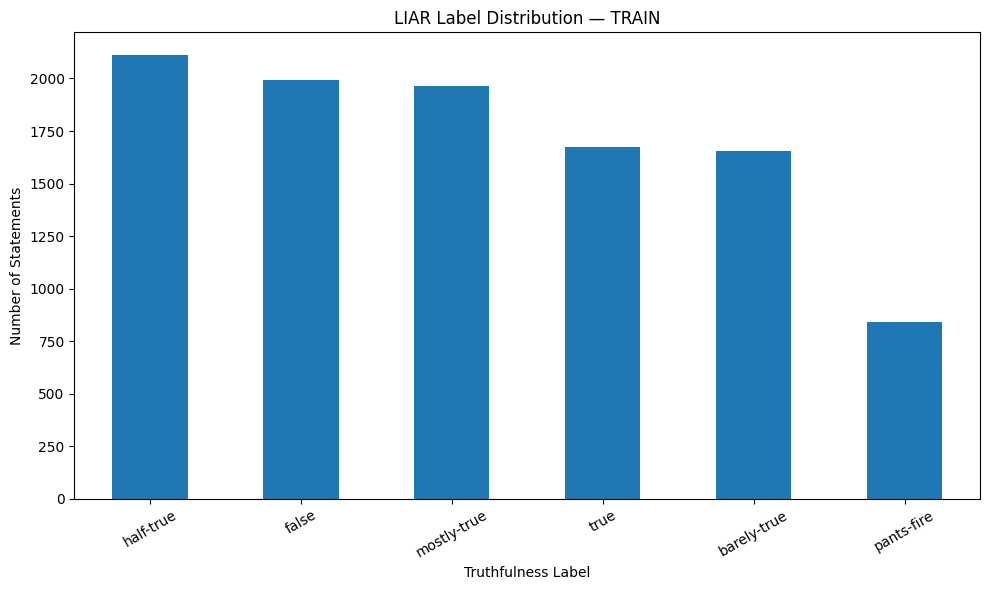

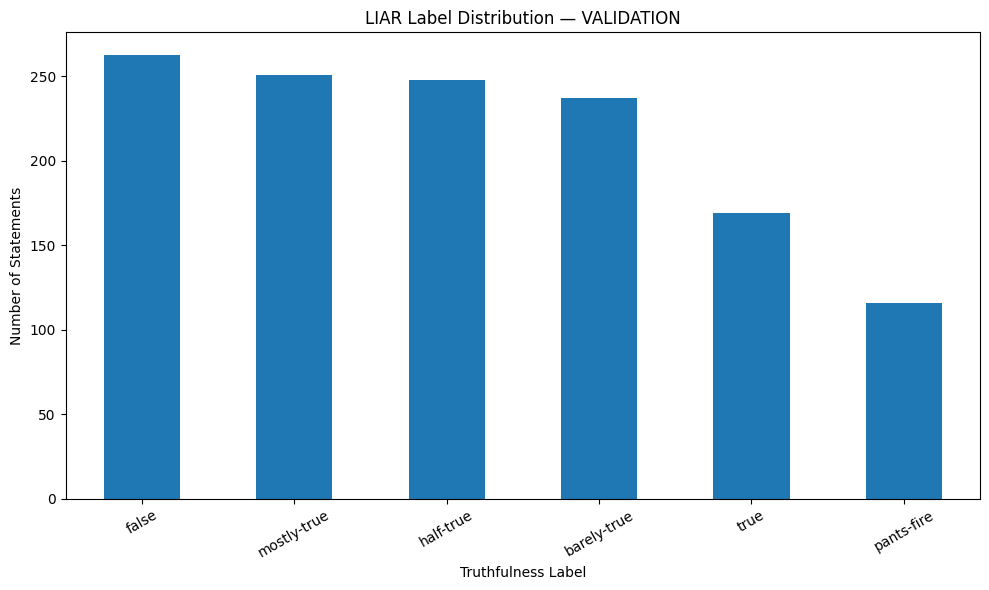

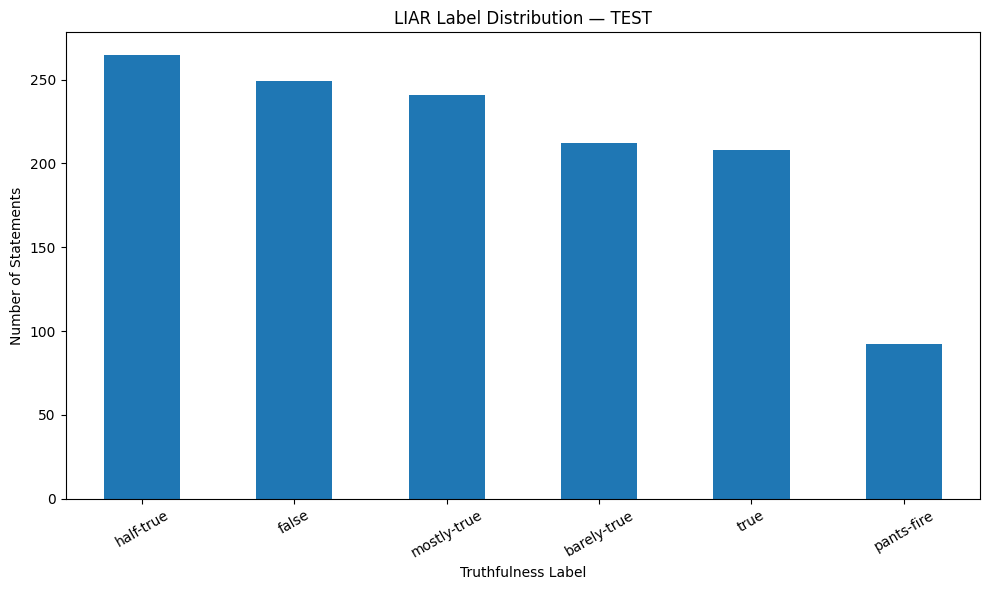

In [ ]:
# 4.1 LABEL DISTRIBUTION


def plot_label_distribution(dataframe, split_name):
    """
    Plot the distribution of the original six LIAR labels
    for a given dataset split.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        Dataset split to analyze.

    split_name : str
        Name of the dataset split.
    """

    # Calculate the number of statements belonging to each label.
    label_counts = dataframe["label"].value_counts()

    # Create a figure for the label-distribution visualization.
    plt.figure(figsize=(10, 6))

    # Plot the label frequencies as a bar chart.
    label_counts.plot(kind="bar")

    # Add a descriptive title identifying the dataset split.
    plt.title(f"LIAR Label Distribution — {split_name}")

    # Label the horizontal axis.
    plt.xlabel("Truthfulness Label")

    # Label the vertical axis.
    plt.ylabel("Number of Statements")

    # Rotate labels slightly to make them easier to read.
    plt.xticks(rotation=30)

    # Adjust the layout so labels are not cut off.
    plt.tight_layout()

    # Display the visualization.
    plt.show()


# ------------------------------------------------------------
# Apply the same EDA function to all three splits
# ------------------------------------------------------------

# Generate the label-distribution graph for the training set.
plot_label_distribution(
    train_df,
    "TRAIN"
)

# Generate the label-distribution graph for the validation set.
plot_label_distribution(
    valid_df,
    "VALIDATION"
)

# Generate the label-distribution graph for the test set.
plot_label_distribution(
    test_df,
    "TEST"
)

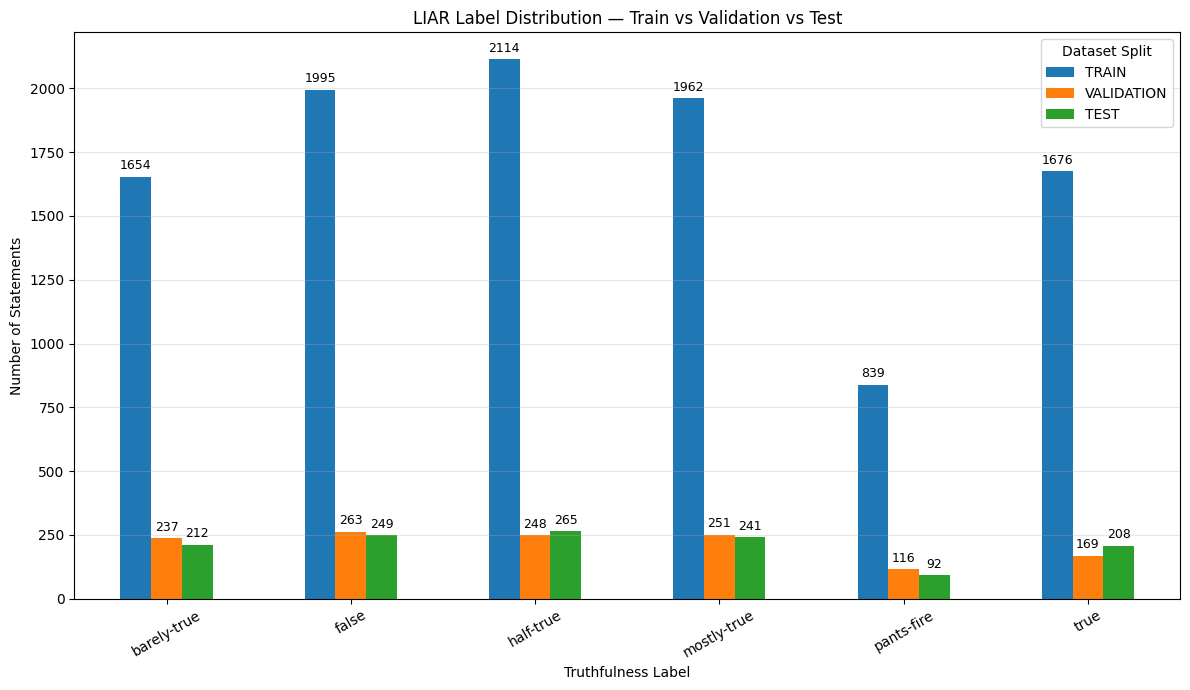

In [ ]:
# 4.2 LABEL DISTRIBUTION — TRAIN vs VALIDATION vs TEST

def plot_combined_label_distribution(dataset_splits):
    """
    Plot the original LIAR label distribution for all dataset
    splits in one grouped bar chart and display counts above bars.
    """

    # Keep the six LIAR labels in a fixed order
    # so all three splits are compared consistently.
    label_order = [
        "barely-true",
        "false",
        "half-true",
        "mostly-true",
        "pants-fire",
        "true"
    ]

    # Create one table containing label counts for each split.
    label_counts = pd.DataFrame({
        split_name: dataframe["label"].value_counts()
        for split_name, dataframe in dataset_splits.items()
    })

    # Reorder the rows to match the fixed label order.
    label_counts = label_counts.reindex(label_order)

    # Create the grouped bar chart.
    ax = label_counts.plot(
        kind="bar",
        figsize=(12, 7)
    )

    # Add a descriptive title and axis labels.
    ax.set_title(
        "LIAR Label Distribution — Train vs Validation vs Test"
    )
    ax.set_xlabel("Truthfulness Label")
    ax.set_ylabel("Number of Statements")

    # Improve readability of label names.
    plt.xticks(rotation=30)

    # Add legend for the three dataset splits.
    plt.legend(title="Dataset Split")

    # Add a light grid to make bar heights easier to compare.
    plt.grid(axis="y", alpha=0.3)

    # Display the exact count above every bar.
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%d",
            padding=3,
            fontsize=9
        )

    # Adjust layout so labels and counts are not cut off.
    plt.tight_layout()

    # Display the graph.
    plt.show()


# Generate the combined label-distribution graph.
plot_combined_label_distribution(dataset_splits)

### 4.2 Label Distribution — Findings

The label distribution was compared across the **Train, Validation, and Test**
splits using a grouped bar chart.

- All six original LIAR labels are present in all three dataset splits.
- `half-true` is the largest class in the training and test sets.
- `false` is the largest class in the validation set.
- `pants-fire` is the smallest class across all three splits.
- The training set contains substantially more samples than the validation
  and test sets, while their overall class proportions are broadly similar.
- The distribution indicates the presence of **class imbalance**, which will
  be considered during model training and evaluation.

### Conclusion

The dataset is suitable for classification, but model performance should not
be judged using accuracy alone. **Precision, recall, macro F1, and weighted F1**
will also be considered, particularly because the `pants-fire` class has
fewer samples.

## 4.3 Word Count Analysis
### 4.3.1 Calculate Word Counts and Plot Distributions

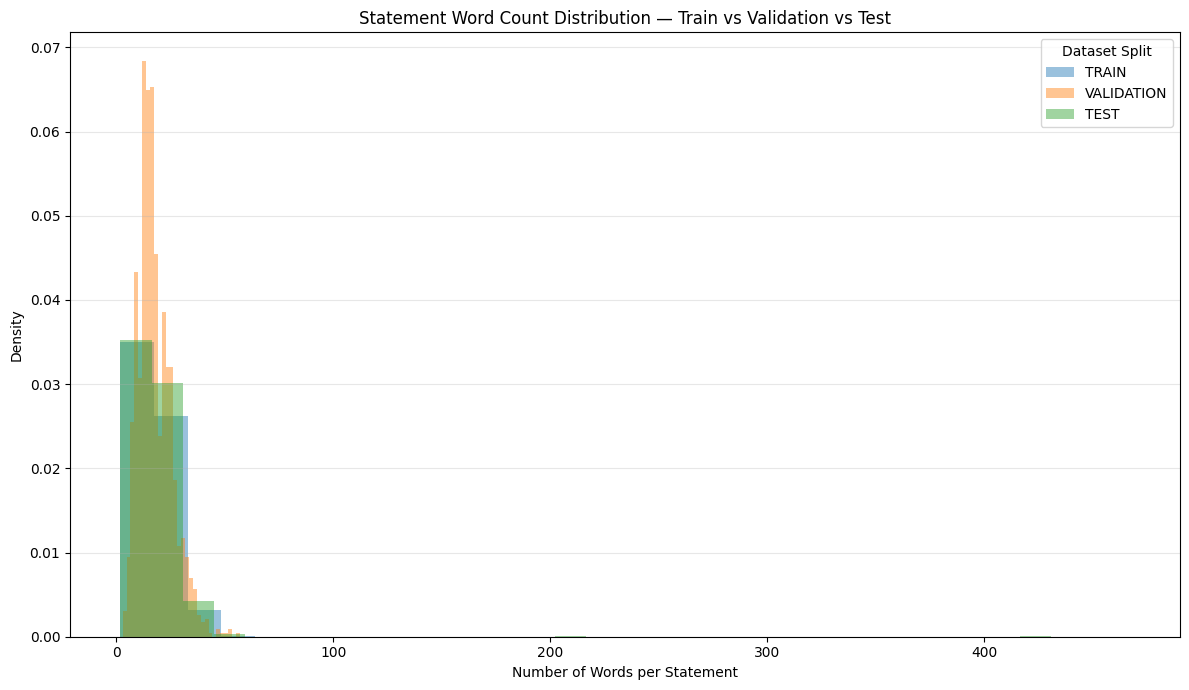

In [ ]:
# 4.3.1 WORD COUNT ANALYSIS

def add_word_count(dataframe):
    """
    Calculate the number of words in each statement.

    The original DataFrame is not modified.
    A copy containing the new word-count column is returned.
    """

    # Create a copy so that the original dataset remains unchanged.
    dataframe_copy = dataframe.copy()

    # Count whitespace-separated words in each statement.
    dataframe_copy["word_count"] = (
        dataframe_copy["statement"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    # Return the DataFrame containing the calculated word counts.
    return dataframe_copy


def plot_word_count_distribution(dataset_splits):
    """
    Compare statement word-count distributions for TRAIN,
    VALIDATION, and TEST in one visualization.
    """

    # Create a figure for the combined word-count analysis.
    plt.figure(figsize=(12, 7))

    # Store the calculated word counts for later summary statistics.
    word_count_data = {}

    # Process each dataset split using the same logic.
    for split_name, dataframe in dataset_splits.items():

        # Calculate word counts without modifying the original DataFrame.
        dataframe_with_counts = add_word_count(dataframe)

        # Store the word-count series for this split.
        word_count_data[split_name] = dataframe_with_counts["word_count"]

        # Plot the distribution using a histogram.
        # Density=True allows the distributions to be compared
        # fairly even though TRAIN has many more observations.
        plt.hist(
            dataframe_with_counts["word_count"],
            bins=30,
            alpha=0.45,
            density=True,
            label=split_name
        )

    # Add a descriptive title.
    plt.title("Statement Word Count Distribution — Train vs Validation vs Test")

    # Label the x-axis.
    plt.xlabel("Number of Words per Statement")

    # Label the y-axis.
    plt.ylabel("Density")

    # Display the legend identifying each dataset split.
    plt.legend(title="Dataset Split")

    # Add a horizontal grid to make the distributions easier to read.
    plt.grid(axis="y", alpha=0.3)

    # Adjust the layout.
    plt.tight_layout()

    # Display the combined histogram.
    plt.show()

    # Return the calculated word counts so that they can be
    # reused later without calculating them again.
    return word_count_data


# ------------------------------------------------------------
# Generate the word-count distributions
# ------------------------------------------------------------

# Calculate and plot word-count distributions for all
# three dataset splits.
word_count_data = plot_word_count_distribution(dataset_splits)

### 4.3.1 Word Count Analysis — Findings

The word-count distributions of the Train, Validation, and Test datasets were
compared using a combined density histogram.

- Most statements in all three splits are relatively short and concentrated
  within a similar word-count range.
- The three distributions show substantial overlap, indicating that statement
  lengths are broadly similar across the dataset splits.
- The distributions are right-skewed, with a small number of considerably
  longer statements.
- A few extreme long-statement outliers are visible, extending beyond the
  main concentration of the data.
- The Validation distribution appears taller in some regions because the plot
  uses density rather than raw counts, allowing the distributions to be
  compared despite the different dataset sizes.

### Conclusion

The statement-length distributions are broadly consistent across the three
splits, although some long-text outliers are present. Statement length will
be considered later when selecting appropriate input sequence lengths for the
BiLSTM and BERT models.

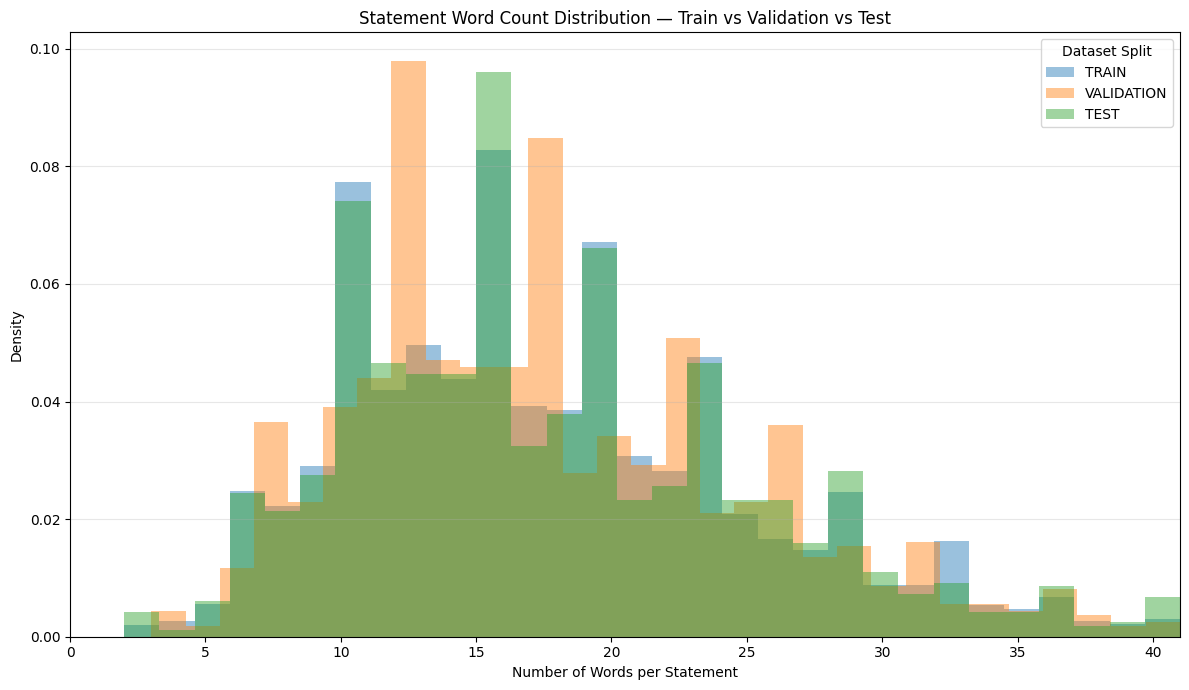

99th-percentile visualization cutoff: 41 words
Note: Statements above this cutoff are NOT deleted or modified. They are excluded only from this visualization so the main distribution is easier to see.


In [ ]:
# 4.3.2 WORD COUNT ANALYSIS — FOCUSED DISTRIBUTION


def calculate_word_counts(dataframe):
    """
    Calculate the number of words in each statement.

    The original DataFrame is not modified.
    """

    # Create a copy so the original dataset remains unchanged.
    dataframe_copy = dataframe.copy()

    # Count whitespace-separated words in each statement.
    dataframe_copy["word_count"] = (
        dataframe_copy["statement"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    # Return the calculated word-count series.
    return dataframe_copy["word_count"]


def plot_focused_word_count_distribution(dataset_splits):
    """
    Plot Train, Validation, and Test word-count distributions
    while limiting the visualization to the 99th percentile.

    Extreme observations are not removed from the dataset.
    They are excluded only from the displayed graph.
    """

    # --------------------------------------------------------
    # Calculate word counts for all dataset splits
    # --------------------------------------------------------

    # Store word counts for every dataset split.
    word_count_data = {}

    for split_name, dataframe in dataset_splits.items():

        # Calculate word counts using the reusable function.
        word_count_data[split_name] = calculate_word_counts(dataframe)


    # --------------------------------------------------------
    # Determine the visualization cutoff
    # --------------------------------------------------------

    # Combine all word counts so that one common cutoff
    # is used for Train, Validation, and Test.
    combined_word_counts = pd.concat(
        word_count_data.values(),
        ignore_index=True
    )

    # Calculate the 99th percentile across all three splits.
    percentile_99 = combined_word_counts.quantile(0.99)

    # Round the cutoff upward to the nearest whole word.
    visualization_limit = int(np.ceil(percentile_99))


    # --------------------------------------------------------
    # Create the focused histogram
    # --------------------------------------------------------

    # Create one figure for comparing all three splits.
    plt.figure(figsize=(12, 7))

    for split_name, word_counts in word_count_data.items():

        # Keep observations within the 99th-percentile range
        # only for visualization.
        focused_counts = word_counts[
            word_counts <= visualization_limit
        ]

        # Plot the distribution using density normalization.
        plt.hist(
            focused_counts,
            bins=30,
            alpha=0.45,
            density=True,
            label=split_name
        )

    # Add a descriptive title.
    plt.title(
        "Statement Word Count Distribution "
        "— Train vs Validation vs Test"
    )

    # Label the x-axis.
    plt.xlabel("Number of Words per Statement")

    # Label the y-axis.
    plt.ylabel("Density")

    # Set the x-axis limit using the common 99th-percentile cutoff.
    plt.xlim(0, visualization_limit)

    # Display the dataset-split legend.
    plt.legend(title="Dataset Split")

    # Add a light horizontal grid.
    plt.grid(axis="y", alpha=0.3)

    # Adjust the layout.
    plt.tight_layout()

    # Display the graph.
    plt.show()


    # --------------------------------------------------------
    # Display information about the excluded tail
    # --------------------------------------------------------

    print(
        f"99th-percentile visualization cutoff: "
        f"{visualization_limit} words"
    )

    print(
        "Note: Statements above this cutoff are NOT deleted "
        "or modified. They are excluded only from this "
        "visualization so the main distribution is easier to see."
    )

    # Return the word-count data and cutoff for possible
    # reuse in later analysis.
    return word_count_data, visualization_limit


# ------------------------------------------------------------
# Generate the focused word-count visualization
# ------------------------------------------------------------

word_count_data, word_count_visualization_limit = (
    plot_focused_word_count_distribution(dataset_splits)
)

## 4.3.2 Word Count Analysis — Findings

The statement word-count distributions of the Train, Validation, and Test
datasets were compared using a combined density histogram. To make the main
distribution easier to interpret, the visualization was limited to the
99th-percentile word-count range.

- Most statements are concentrated approximately between 5 and 30 words.
- The highest concentration of statements occurs around the 10–20 word range.
- The three dataset splits show substantial overlap, indicating that their
  statement-length distributions are broadly similar.
- Validation and Test generally follow the same overall distribution pattern
  as the Training set.
- A smaller number of longer statements are present, but they represent only
  a small portion of the dataset.

### Conclusion

The Train, Validation, and Test datasets have broadly consistent statement
length distributions. The presence of some longer statements will be
considered later when determining suitable input sequence lengths for the
BiLSTM and BERT models.

The long statements were not removed from the dataset; the 99th-percentile
cutoff was applied only to improve visualization of the main distribution.

## 4.3.2 Handling Skewness and Long-Text Outliers

For this project, skewness and long-text observations will be handled according
to the nature of text data rather than using conventional numerical outlier
treatment.

- **Skewness:** We do not need to "fix" the word-count skewness using
  transformations such as log or square-root transformations. Word count is
  primarily an EDA characteristic of the text and is not necessarily used
  directly as a numerical feature for the Logistic Regression or Linear SVM
  models.

- **Long-text outliers:** Long statements will **not be deleted simply because
  they are long**. They may represent legitimate political statements and
  should only be removed if they are found to be genuinely erroneous or
  corrupted records.

- **BiLSTM / BERT:** Long sequences will be handled during model-specific
  preprocessing using tokenization and a selected maximum sequence length.
  Depending on the model configuration, longer sequences may be truncated and
  shorter sequences padded.

- **TF-IDF models:** The text is converted into TF-IDF feature vectors.
  Therefore, conventional numerical outlier treatment is not required for
  word-count skewness.

### Overall Approach

```text
EDA
 │
 ├── Identify skewness / long-text observations
 │
 ├── Understand their extent
 │
 └── Do NOT automatically remove them
          ↓
Model-Specific Preprocessing
 │
 ├── TF-IDF → Vectorization
 │
 ├── BiLSTM → Tokenization + Padding / Truncation
 │
 └── BERT → Tokenizer + Maximum Sequence Length

## 4.4 Top Speaker Analysis
### 4.4.1 Top Speakers — Train vs Validation vs Test

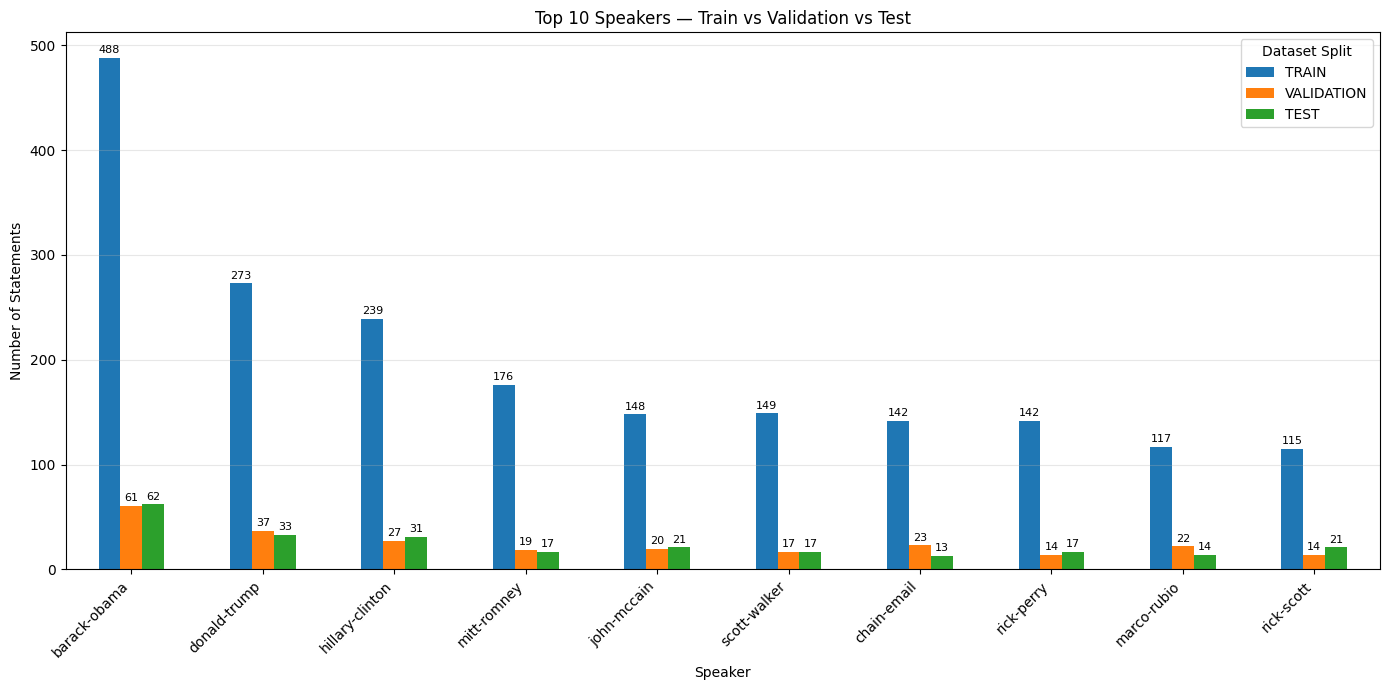


Top Speaker Frequency Table:


,TRAIN,VALIDATION,TEST,TOTAL
speaker,,,,
barack-obama,488,61,62,611
donald-trump,273,37,33,343
hillary-clinton,239,27,31,297
mitt-romney,176,19,17,212
john-mccain,148,20,21,189
scott-walker,149,17,17,183
chain-email,142,23,13,178
rick-perry,142,14,17,173
marco-rubio,117,22,14,153


In [ ]:
# 4.4.1 TOP SPEAKER ANALYSIS


def plot_top_speakers(dataset_splits, top_n=10):


    # --------------------------------------------------------
    # Calculate speaker frequencies for each split
    # --------------------------------------------------------

    speaker_counts = {}

    for split_name, dataframe in dataset_splits.items():

        # Treat missing speaker values as "Unknown" only for
        # this analysis without modifying the original DataFrame.
        speaker_counts[split_name] = (
            dataframe["speaker"]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
            .value_counts()
        )


    # --------------------------------------------------------
    # Identify the overall top speakers
    # --------------------------------------------------------

    # Combine speaker frequencies from all three splits.
    combined_speaker_counts = (
        pd.concat(speaker_counts.values(), axis=1)
        .fillna(0)
        .sum(axis=1)
        .sort_values(ascending=False)
    )

    # Select the top N speakers based on their total
    # representation across all dataset splits.
    top_speakers = combined_speaker_counts.head(top_n).index


    # --------------------------------------------------------
    # Create comparison table
    # --------------------------------------------------------

    # Build a table containing the selected speakers and
    # their counts in each individual dataset split.
    top_speaker_table = pd.DataFrame({
        split_name: counts.reindex(top_speakers, fill_value=0)
        for split_name, counts in speaker_counts.items()
    })

    # Add the overall count across all three splits.
    top_speaker_table["TOTAL"] = top_speaker_table.sum(axis=1)

    # Sort by overall frequency.
    top_speaker_table = top_speaker_table.sort_values(
        "TOTAL",
        ascending=False
    )


    # --------------------------------------------------------
    # Plot the comparison
    # --------------------------------------------------------

    # Plot only the three dataset splits.
    # TOTAL is retained in the table but is not plotted.
    ax = top_speaker_table[
        ["TRAIN", "VALIDATION", "TEST"]
    ].plot(
        kind="bar",
        figsize=(14, 7)
    )

    # Add a descriptive title.
    ax.set_title(
        f"Top {top_n} Speakers — Train vs Validation vs Test"
    )

    # Label the horizontal axis.
    ax.set_xlabel("Speaker")

    # Label the vertical axis.
    ax.set_ylabel("Number of Statements")

    # Rotate speaker names for readability.
    plt.xticks(rotation=45, ha="right")

    # Display the dataset-split legend.
    plt.legend(title="Dataset Split")

    # Add a light horizontal grid.
    plt.grid(axis="y", alpha=0.3)

    # Display exact counts above every bar.
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%d",
            padding=2,
            fontsize=8
        )

    # Adjust the layout.
    plt.tight_layout()

    # Display the graph.
    plt.show()


    # --------------------------------------------------------
    # Display the numerical comparison table
    # --------------------------------------------------------

    print("\nTop Speaker Frequency Table:")

    display(top_speaker_table)


    # Return the table for possible reuse later.
    return top_speaker_table


# ------------------------------------------------------------
# Generate the top-speaker analysis
# ------------------------------------------------------------

top_speaker_results = plot_top_speakers(
    dataset_splits,
    top_n=10
)

## 4.4.1 Top Speaker Analysis — Findings

The top 10 speakers were identified based on their combined frequency across
the Train, Validation, and Test datasets. Their representation in each split
was then compared using a grouped bar chart.

- `barack-obama` is the most frequently represented speaker among the top 10.
- `donald-trump` and `hillary-clinton` are the next most frequently
  represented speakers.
- The remaining top speakers have substantially fewer statements compared
  with the most frequent speakers.
- The major speakers appear across Train, Validation, and Test, although their
  frequencies differ between the splits.
- The Training set has higher absolute speaker counts because it contains
  substantially more statements than the Validation and Test sets.

### Conclusion

The dataset contains statements from a relatively small group of highly
represented speakers. Speaker distribution is therefore an important
characteristic to consider during modeling.

Speaker information may potentially provide predictive shortcuts if used
directly, so its influence will be considered carefully when selecting
features for the final models.

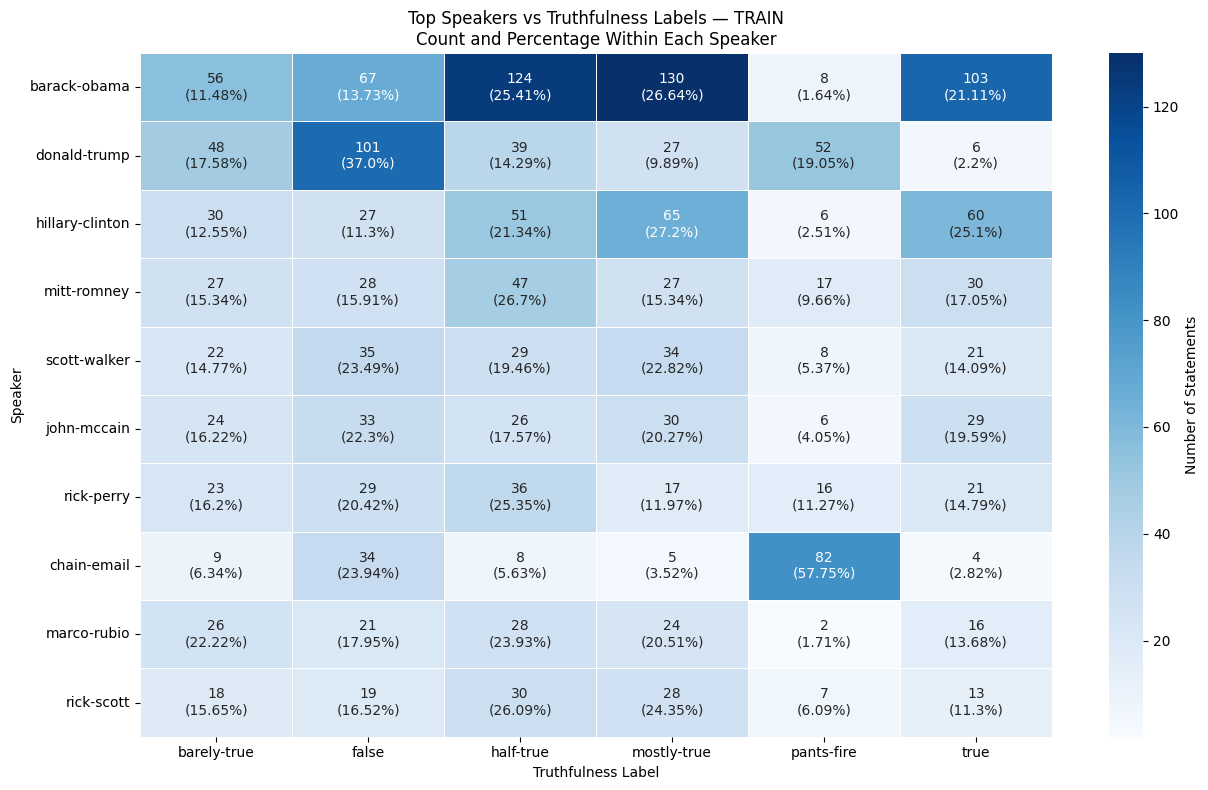

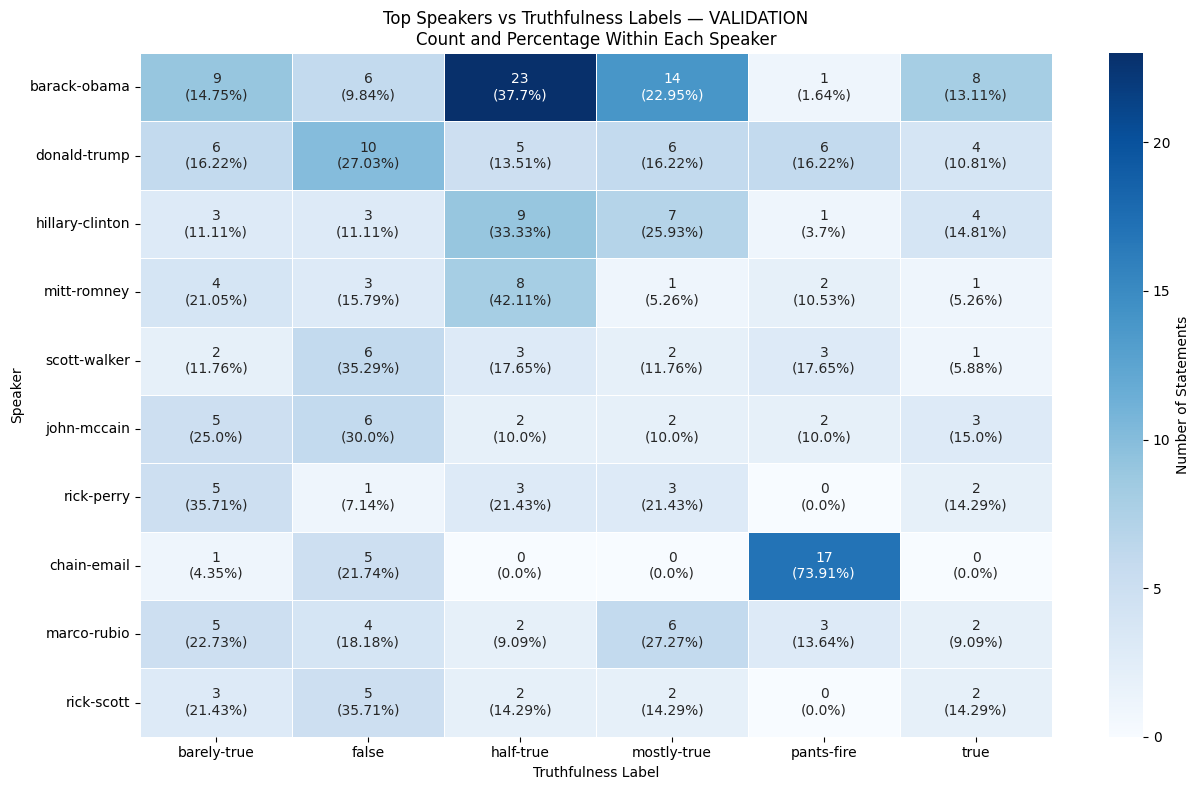

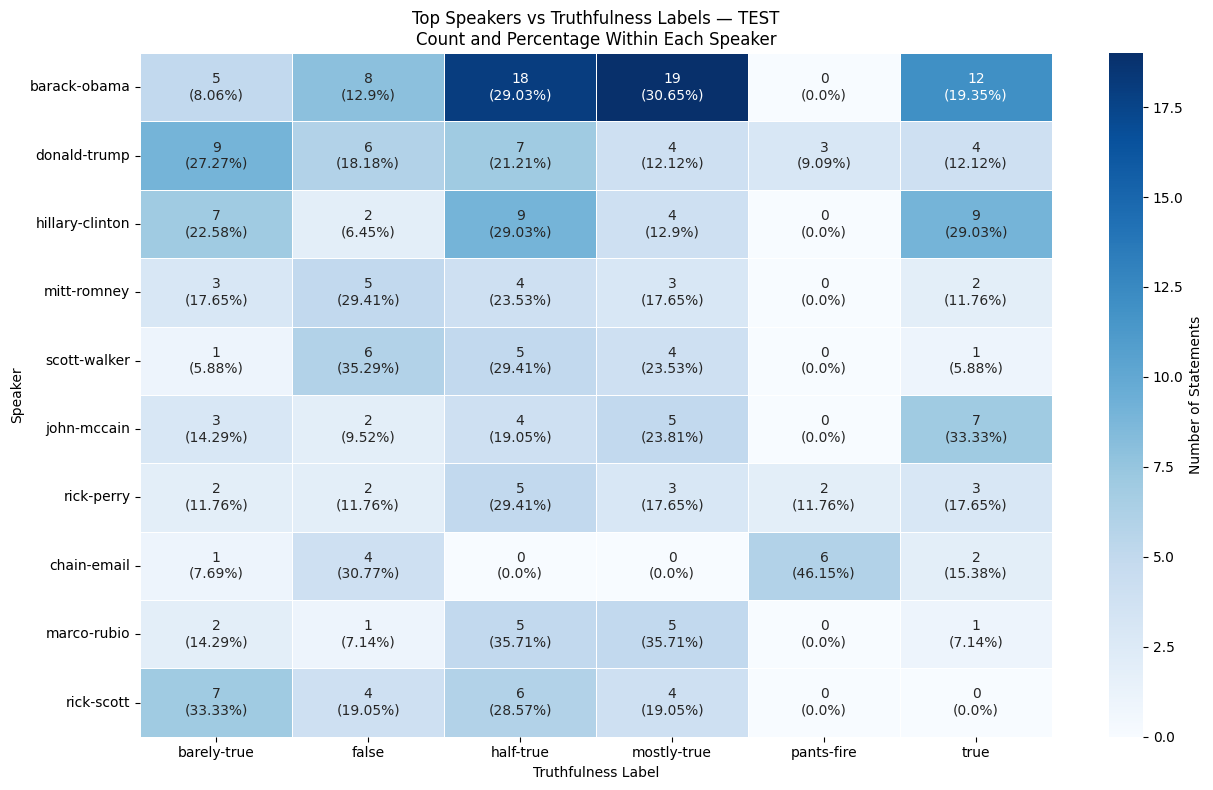


TRAIN — SPEAKER TRUTHFULNESS COUNTS


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
speaker,,,,,,,
barack-obama,488,56,67,124,130,8,103
donald-trump,273,48,101,39,27,52,6
hillary-clinton,239,30,27,51,65,6,60
mitt-romney,176,27,28,47,27,17,30
scott-walker,149,22,35,29,34,8,21
john-mccain,148,24,33,26,30,6,29
rick-perry,142,23,29,36,17,16,21
chain-email,142,9,34,8,5,82,4
marco-rubio,117,26,21,28,24,2,16



TRAIN — SPEAKER TRUTHFULNESS PERCENTAGES (%)


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
speaker,,,,,,,
barack-obama,488,11.48,13.73,25.41,26.64,1.64,21.11
donald-trump,273,17.58,37.00,14.29,9.89,19.05,2.20
hillary-clinton,239,12.55,11.30,21.34,27.20,2.51,25.10
mitt-romney,176,15.34,15.91,26.70,15.34,9.66,17.05
scott-walker,149,14.77,23.49,19.46,22.82,5.37,14.09
john-mccain,148,16.22,22.30,17.57,20.27,4.05,19.59
rick-perry,142,16.20,20.42,25.35,11.97,11.27,14.79
chain-email,142,6.34,23.94,5.63,3.52,57.75,2.82
marco-rubio,117,22.22,17.95,23.93,20.51,1.71,13.68



VALIDATION — SPEAKER TRUTHFULNESS COUNTS


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
speaker,,,,,,,
barack-obama,61,9,6,23,14,1,8
donald-trump,37,6,10,5,6,6,4
hillary-clinton,27,3,3,9,7,1,4
mitt-romney,19,4,3,8,1,2,1
scott-walker,17,2,6,3,2,3,1
john-mccain,20,5,6,2,2,2,3
rick-perry,14,5,1,3,3,0,2
chain-email,23,1,5,0,0,17,0
marco-rubio,22,5,4,2,6,3,2


... (2 outputs left out)


TEST — SPEAKER TRUTHFULNESS COUNTS


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
speaker,,,,,,,
barack-obama,62,5,8,18,19,0,12
donald-trump,33,9,6,7,4,3,4
hillary-clinton,31,7,2,9,4,0,9
mitt-romney,17,3,5,4,3,0,2
scott-walker,17,1,6,5,4,0,1
john-mccain,21,3,2,4,5,0,7
rick-perry,17,2,2,5,3,2,3
chain-email,13,1,4,0,0,6,2
marco-rubio,14,2,1,5,5,0,1



TEST — SPEAKER TRUTHFULNESS PERCENTAGES (%)


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
speaker,,,,,,,
barack-obama,62,8.06,12.90,29.03,30.65,0.00,19.35
donald-trump,33,27.27,18.18,21.21,12.12,9.09,12.12
hillary-clinton,31,22.58,6.45,29.03,12.90,0.00,29.03
mitt-romney,17,17.65,29.41,23.53,17.65,0.00,11.76
scott-walker,17,5.88,35.29,29.41,23.53,0.00,5.88
john-mccain,21,14.29,9.52,19.05,23.81,0.00,33.33
rick-perry,17,11.76,11.76,29.41,17.65,11.76,17.65
chain-email,13,7.69,30.77,0.00,0.00,46.15,15.38
marco-rubio,14,14.29,7.14,35.71,35.71,0.00,7.14


In [ ]:
# 4.4.2 SPEAKER VS TRUTHFULNESS LABEL
# COUNT + PERCENTAGE — TRAIN / VALIDATION / TEST


# Import Seaborn for heatmap visualization.
import seaborn as sns


def create_speaker_label_analysis(dataframe, top_speakers, label_order):
    """
    Create speaker-vs-label count and percentage tables
    for a given dataset split.

    Percentage is calculated within each speaker:

        Label % = Label Count / Total Speaker Statements × 100
    """

    # --------------------------------------------------------
    # Prepare speaker values
    # --------------------------------------------------------

    # Create a copy so the original DataFrame is not modified.
    analysis_data = dataframe.copy()

    # Handle missing speaker values only for this analysis.
    analysis_data["speaker_analysis"] = (
        analysis_data["speaker"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )


    # --------------------------------------------------------
    # Keep selected top speakers
    # --------------------------------------------------------

    analysis_data = analysis_data[
        analysis_data["speaker_analysis"].isin(top_speakers)
    ]


    # --------------------------------------------------------
    # Create speaker × label count table
    # --------------------------------------------------------

    speaker_label_counts = pd.crosstab(
        analysis_data["speaker_analysis"],
        analysis_data["label"]
    )


    # Ensure all six LIAR labels are present.
    speaker_label_counts = speaker_label_counts.reindex(
        columns=label_order,
        fill_value=0
    )


    # Keep speakers in the same order across all splits.
    speaker_label_counts = speaker_label_counts.reindex(
        top_speakers,
        fill_value=0
    )


    # --------------------------------------------------------
    # Calculate percentages within each speaker
    # --------------------------------------------------------

    # Calculate total statements for every speaker.
    speaker_totals = speaker_label_counts.sum(axis=1)


    # Calculate percentage of each truthfulness label
    # within the speaker's own statements.
    speaker_label_percentages = (
        speaker_label_counts.div(
            speaker_totals,
            axis=0
        ) * 100
    )


    # --------------------------------------------------------
    # Create COUNT + PERCENTAGE annotations
    # --------------------------------------------------------

    heatmap_annotations = (
        speaker_label_counts.astype(str)
        + "\n("
        + speaker_label_percentages.round(2).astype(str)
        + "%)"
    )


    # Return all analysis results.
    return (
        speaker_label_counts,
        speaker_label_percentages,
        heatmap_annotations
    )


def plot_speaker_label_heatmaps(dataset_splits, top_n=10):
    """
    Compare the top speakers against the six LIAR
    truthfulness labels across Train, Validation, and Test.

    Each heatmap cell displays:

        Count
        (Percentage within speaker)
    """

    # --------------------------------------------------------
    # Define original LIAR label order
    # --------------------------------------------------------

    label_order = [
        "barely-true",
        "false",
        "half-true",
        "mostly-true",
        "pants-fire",
        "true"
    ]


    # --------------------------------------------------------
    # Identify top speakers using TRAIN only
    # --------------------------------------------------------

    train_speakers = (
        dataset_splits["TRAIN"]["speaker"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

    # Select the top speakers using Training data only.
    top_speakers = (
        train_speakers
        .value_counts()
        .head(top_n)
        .index
    )


    # --------------------------------------------------------
    # Analyze all three dataset splits
    # --------------------------------------------------------

    speaker_results = {}

    for split_name in ["TRAIN", "VALIDATION", "TEST"]:

        # Create count and percentage analysis for this split.
        counts, percentages, annotations = (
            create_speaker_label_analysis(
                dataset_splits[split_name],
                top_speakers,
                label_order
            )
        )

        # Store results.
        speaker_results[split_name] = {
            "counts": counts,
            "percentages": percentages,
            "annotations": annotations
        }


    # --------------------------------------------------------
    # Create one heatmap for each split
    # --------------------------------------------------------

    for split_name in ["TRAIN", "VALIDATION", "TEST"]:

        # Create a separate figure for each dataset split.
        plt.figure(figsize=(13, 8))

        # Plot the count-based heatmap.
        sns.heatmap(
            speaker_results[split_name]["counts"],
            annot=speaker_results[split_name]["annotations"],
            fmt="",
            cmap="Blues",
            linewidths=0.5,
            cbar_kws={
                "label": "Number of Statements"
            }
        )

        # Add descriptive title.
        plt.title(
            f"Top Speakers vs Truthfulness Labels — "
            f"{split_name}\n"
            f"Count and Percentage Within Each Speaker"
        )

        # Label axes.
        plt.xlabel("Truthfulness Label")
        plt.ylabel("Speaker")

        # Adjust layout.
        plt.tight_layout()

        # Display the heatmap.
        plt.show()


    # --------------------------------------------------------
    # Display summary tables for all three splits
    # --------------------------------------------------------

    for split_name in ["TRAIN", "VALIDATION", "TEST"]:

        # Get count table.
        count_table = (
            speaker_results[split_name]["counts"]
            .copy()
        )

        # Add total statements column.
        count_table.insert(
            0,
            "Total Statements",
            count_table.sum(axis=1)
        )

        print(
            f"\n{'=' * 70}\n"
            f"{split_name} — SPEAKER TRUTHFULNESS COUNTS\n"
            f"{'=' * 70}"
        )

        display(count_table)


        # Get percentage table.
        percentage_table = (
            speaker_results[split_name]["percentages"]
            .copy()
            .round(2)
        )

        # Add total statements for reference.
        percentage_table.insert(
            0,
            "Total Statements",
            count_table["Total Statements"]
        )

        print(
            f"\n{split_name} — SPEAKER TRUTHFULNESS "
            f"PERCENTAGES (%)"
        )

        display(percentage_table)


    # Return all results for later interpretation.
    return {
        "top_speakers": top_speakers,
        "results": speaker_results
    }


# ------------------------------------------------------------
# Generate the complete speaker-label analysis
# ------------------------------------------------------------

speaker_label_analysis = plot_speaker_label_heatmaps(
    dataset_splits,
    top_n=10
)

## 4.4.2 Top Speaker Analysis — Findings

The speaker-level analysis was extended to examine the distribution of
truthfulness labels within the statements made by the top 10 speakers.
For each speaker, both the raw statement count and the percentage of
statements belonging to each truthfulness category were analyzed across
the Train, Validation, and Test datasets.

### Key Findings

- The truthfulness-label distribution varies considerably between speakers,
  indicating that speaker identity has a noticeable relationship with the
  labels in this dataset.

- Barack Obama has a relatively high proportion of `half-true` and
  `mostly-true` statements across the splits.

- Donald Trump shows a comparatively high proportion of `false` statements
  in the Training set, although the distribution becomes more varied in the
  Validation and Test sets.

- Hillary Clinton has relatively high proportions of `half-true`,
  `mostly-true`, and `true` statements.

- Chain-email shows a particularly high proportion of `pants-fire`
  statements across the splits. However, its smaller number of observations
  means that these percentages should be interpreted with caution.

- Percentage differences between Validation and Test can be larger because
  these datasets contain substantially fewer statements for each speaker
  than the Training set.

### Modeling Consideration

The analysis indicates that `speaker` may contain predictive information
about the truthfulness label. However, directly using speaker identity as a
model feature could allow a model to learn speaker-specific patterns rather
than relying primarily on the textual content of the statement.

Therefore, the influence of speaker metadata will be considered carefully
when designing the model feature sets.

### Conclusion

Speaker identity and truthfulness labels show a noticeable relationship in
the LIAR dataset. This relationship is important for understanding the
dataset and for making an informed decision about the use of speaker
metadata during model development.

## 4.5 Subject Analysis
### 4.5.1 Subject Distribution

TOP 15 SUBJECTS — TRAIN / VALIDATION / TEST


,TRAIN,VALIDATION,TEST
subject,,,
health-care,381,53,40
taxes,308,29,19
immigration,253,32,18
elections,252,21,31
education,237,42,30
candidates-biography,190,19,30
economy,137,12,21
guns,130,11,11
"economy,jobs",125,16,11


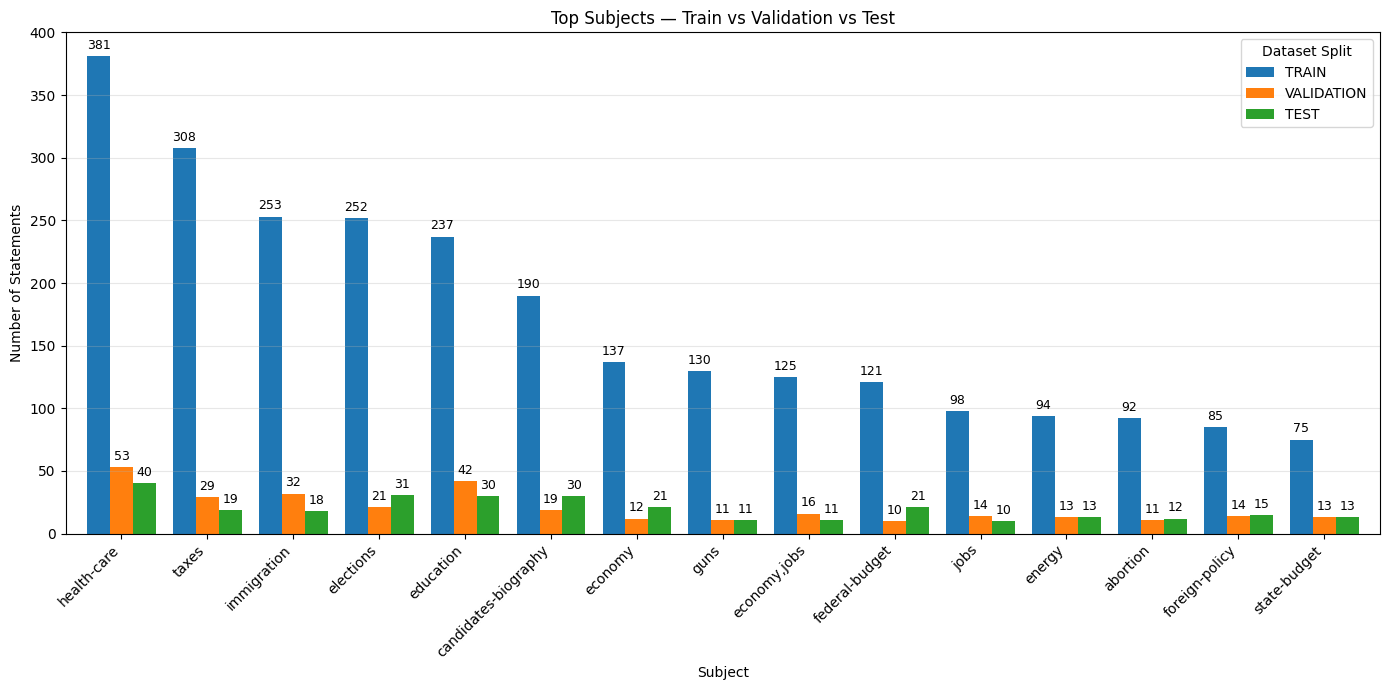

In [ ]:
# 4.5.1 SUBJECT DISTRIBUTION


def analyze_subject_distribution(dataset_splits, top_n=15):
    """
    Analyze and visualize the most frequent subjects
    across Train, Validation, and Test datasets.
    """

    # --------------------------------------------------------
    # Identify top subjects using TRAINING data
    # --------------------------------------------------------

    train_subjects = (
        dataset_splits["TRAIN"]["subject"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

    top_subjects = (
        train_subjects
        .value_counts()
        .head(top_n)
        .index
    )


    # --------------------------------------------------------
    # Create subject count table
    # --------------------------------------------------------

    subject_counts = {}

    for split_name, dataframe in dataset_splits.items():

        subjects = (
            dataframe["subject"]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
        )

        counts = subjects.value_counts()

        counts = counts.reindex(
            top_subjects,
            fill_value=0
        )

        subject_counts[split_name] = counts


    # --------------------------------------------------------
    # Combine all split results
    # --------------------------------------------------------

    subject_summary = pd.DataFrame(subject_counts)

    subject_summary = subject_summary[
        ["TRAIN", "VALIDATION", "TEST"]
    ]


    # --------------------------------------------------------
    # Display count table
    # --------------------------------------------------------

    print(
        f"{'=' * 70}\n"
        f"TOP {top_n} SUBJECTS — TRAIN / VALIDATION / TEST\n"
        f"{'=' * 70}"
    )

    display(subject_summary)


    # --------------------------------------------------------
    # Create comparison graph
    # --------------------------------------------------------

    ax = subject_summary.plot(
        kind="bar",
        figsize=(14, 7),
        width=0.8
    )

    # --------------------------------------------------------
    # Add count labels above every bar
    # --------------------------------------------------------

    for container in ax.containers:

        ax.bar_label(
            container,
            fmt="%d",
            padding=3,
            fontsize=9
        )


    # --------------------------------------------------------
    # Add title and axis labels
    # --------------------------------------------------------

    plt.title(
        "Top Subjects — Train vs Validation vs Test"
    )

    plt.xlabel("Subject")

    plt.ylabel("Number of Statements")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.legend(
        title="Dataset Split"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # Return results
    # --------------------------------------------------------

    return subject_summary


# ------------------------------------------------------------
# Generate subject distribution analysis
# ------------------------------------------------------------

subject_distribution_results = analyze_subject_distribution(
    dataset_splits,
    top_n=15
)

**bold text**## 4.5.1 Subject Distribution — Findings

The distribution of the most frequent subjects was analyzed across the
Training, Validation, and Test datasets.

### Key Findings

- `health-care` is the most frequently represented subject in the Train,validation,test
  dataset.
- `taxes`, `immigration`, `elections`, and `education` are also among the
  most frequently occurring subjects.
- The remaining top subjects have progressively fewer statements compared
  with the most frequent subjects.
- The major subjects are represented across Train, Validation, and Test,
  although their absolute frequencies differ because the dataset sizes are
  different.
- The dataset contains statements covering a broad range of political and
  social topics, while some subjects have substantially more observations
  than others.

### Conclusion

Subject distribution is an important characteristic of the LIAR dataset.
The analysis will help us understand whether particular topics are
associated with specific truthfulness labels before deciding whether
`subject` should be considered as a model feature.

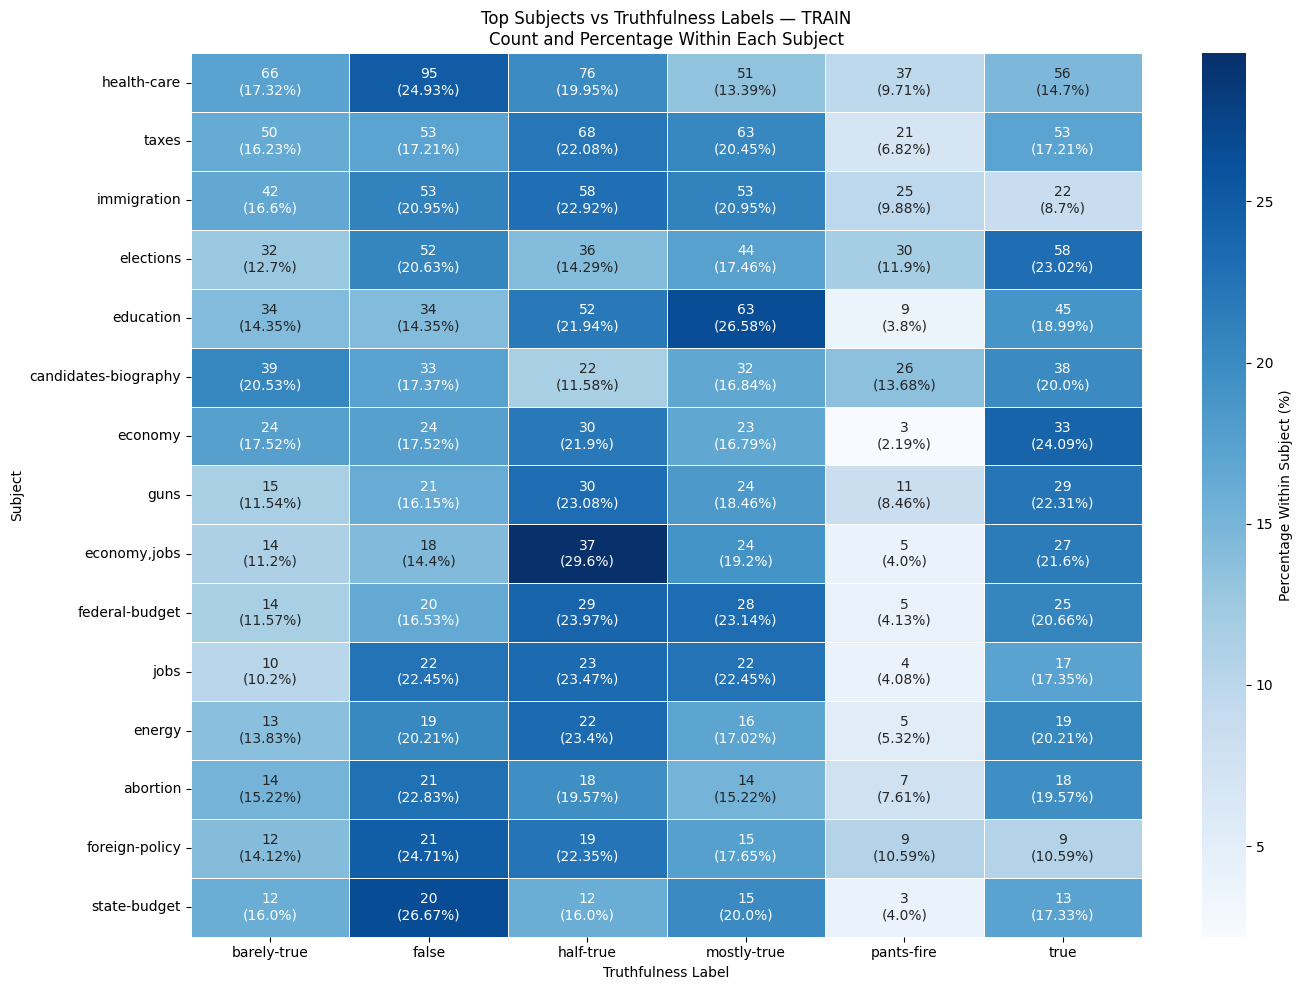

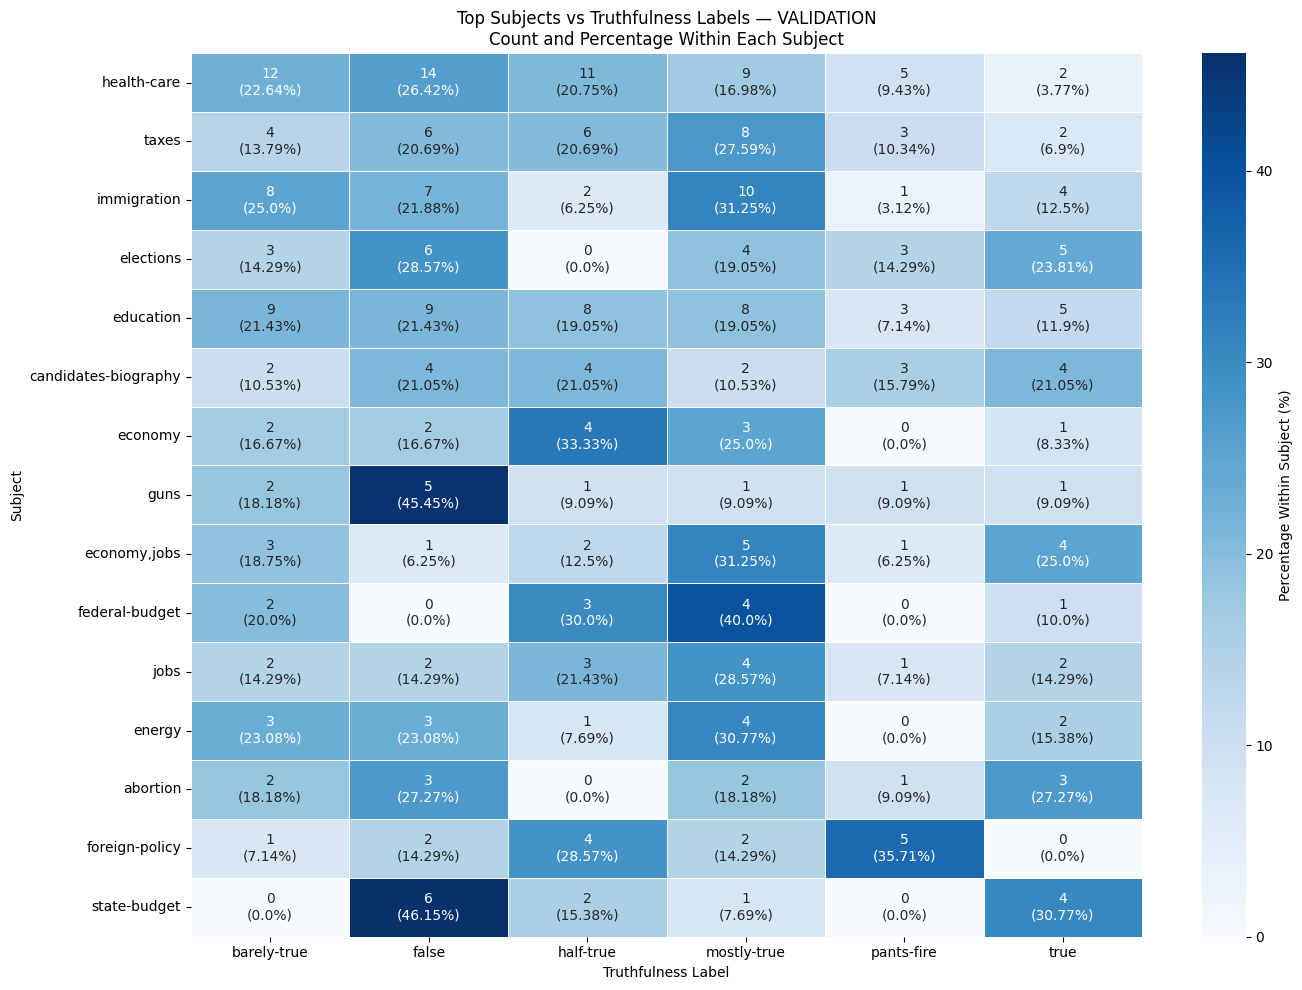

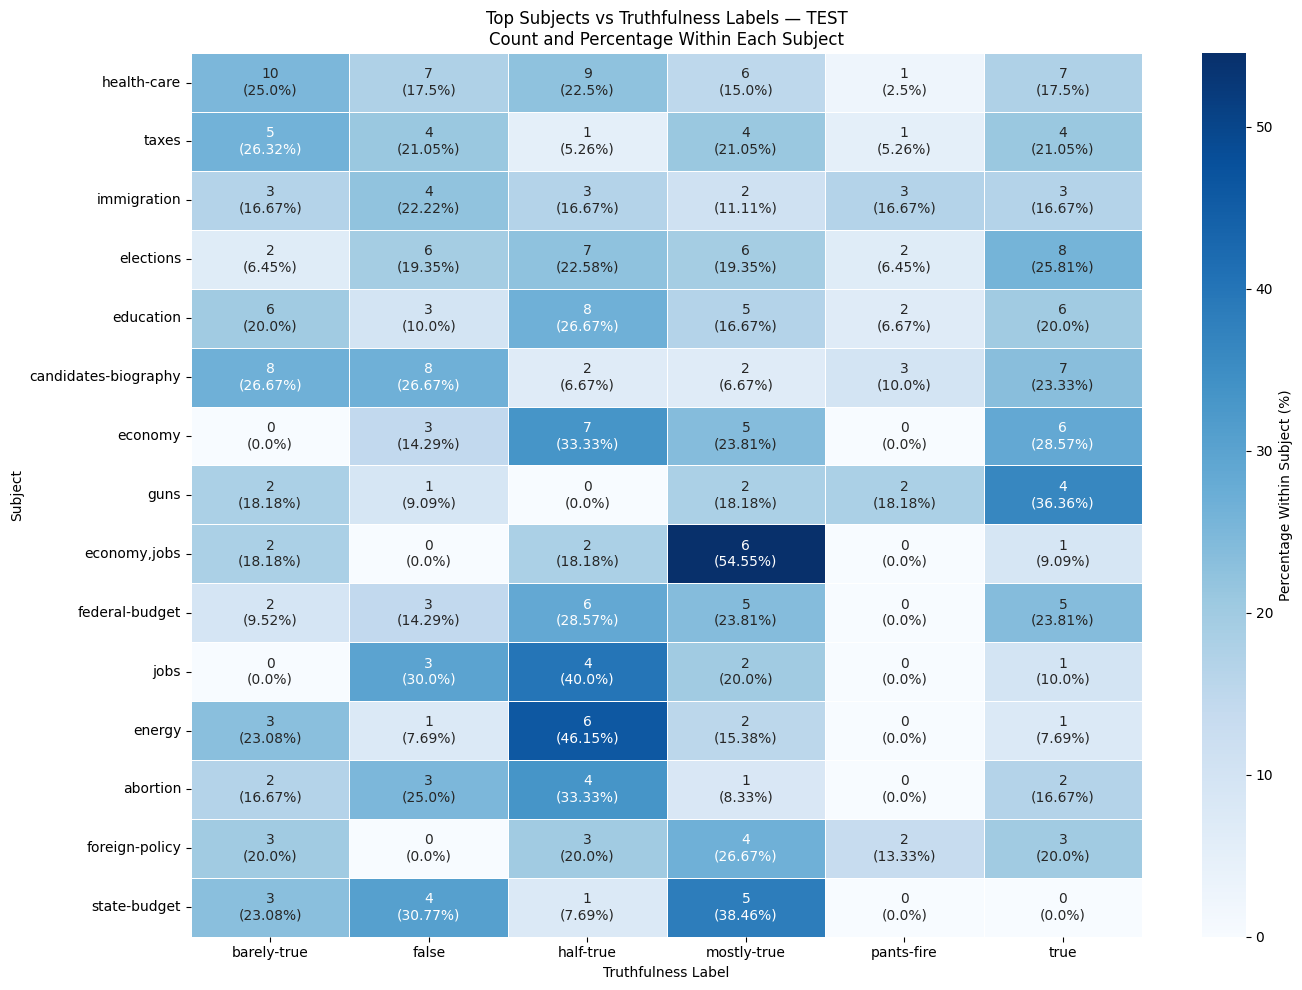


TRAIN — SUBJECT TRUTHFULNESS COUNTS


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
subject,,,,,,,
health-care,381,66,95,76,51,37,56
taxes,308,50,53,68,63,21,53
immigration,253,42,53,58,53,25,22
elections,252,32,52,36,44,30,58
education,237,34,34,52,63,9,45
candidates-biography,190,39,33,22,32,26,38
economy,137,24,24,30,23,3,33
guns,130,15,21,30,24,11,29
"economy,jobs",125,14,18,37,24,5,27



TRAIN — SUBJECT TRUTHFULNESS PERCENTAGES (%)


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
subject,,,,,,,
health-care,381,17.32,24.93,19.95,13.39,9.71,14.70
taxes,308,16.23,17.21,22.08,20.45,6.82,17.21
immigration,253,16.60,20.95,22.92,20.95,9.88,8.70
elections,252,12.70,20.63,14.29,17.46,11.90,23.02
education,237,14.35,14.35,21.94,26.58,3.80,18.99
candidates-biography,190,20.53,17.37,11.58,16.84,13.68,20.00
economy,137,17.52,17.52,21.90,16.79,2.19,24.09
guns,130,11.54,16.15,23.08,18.46,8.46,22.31
"economy,jobs",125,11.20,14.40,29.60,19.20,4.00,21.60



VALIDATION — SUBJECT TRUTHFULNESS COUNTS


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
subject,,,,,,,
health-care,53,12,14,11,9,5,2
taxes,29,4,6,6,8,3,2
immigration,32,8,7,2,10,1,4
elections,21,3,6,0,4,3,5
education,42,9,9,8,8,3,5
candidates-biography,19,2,4,4,2,3,4
economy,12,2,2,4,3,0,1
guns,11,2,5,1,1,1,1
"economy,jobs",16,3,1,2,5,1,4


... (2 outputs left out)


TEST — SUBJECT TRUTHFULNESS COUNTS


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
subject,,,,,,,
health-care,40,10,7,9,6,1,7
taxes,19,5,4,1,4,1,4
immigration,18,3,4,3,2,3,3
elections,31,2,6,7,6,2,8
education,30,6,3,8,5,2,6
candidates-biography,30,8,8,2,2,3,7
economy,21,0,3,7,5,0,6
guns,11,2,1,0,2,2,4
"economy,jobs",11,2,0,2,6,0,1



TEST — SUBJECT TRUTHFULNESS PERCENTAGES (%)


label,Total Statements,barely-true,false,half-true,mostly-true,pants-fire,true
subject,,,,,,,
health-care,40,25.00,17.50,22.50,15.00,2.50,17.50
taxes,19,26.32,21.05,5.26,21.05,5.26,21.05
immigration,18,16.67,22.22,16.67,11.11,16.67,16.67
elections,31,6.45,19.35,22.58,19.35,6.45,25.81
education,30,20.00,10.00,26.67,16.67,6.67,20.00
candidates-biography,30,26.67,26.67,6.67,6.67,10.00,23.33
economy,21,0.00,14.29,33.33,23.81,0.00,28.57
guns,11,18.18,9.09,0.00,18.18,18.18,36.36
"economy,jobs",11,18.18,0.00,18.18,54.55,0.00,9.09


In [ ]:
# 4.5.2 SUBJECT VS TRUTHFULNESS LABEL
# COUNT + PERCENTAGE — TRAIN / VALIDATION / TEST

import seaborn as sns


def create_subject_label_analysis(dataframe, top_subjects, label_order):
    """
    Create subject-vs-label count and percentage tables
    for a given dataset split.

    Percentage is calculated within each subject:

        Label % = Label Count / Total Subject Statements × 100
    """

    # --------------------------------------------------------
    # Prepare subject values
    # --------------------------------------------------------

    analysis_data = dataframe.copy()

    analysis_data["subject_analysis"] = (
        analysis_data["subject"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )


    # --------------------------------------------------------
    # Keep selected top subjects
    # --------------------------------------------------------

    analysis_data = analysis_data[
        analysis_data["subject_analysis"].isin(top_subjects)
    ]


    # --------------------------------------------------------
    # Create subject × label count table
    # --------------------------------------------------------

    subject_label_counts = pd.crosstab(
        analysis_data["subject_analysis"],
        analysis_data["label"]
    )


    # Ensure all six LIAR labels are present.
    subject_label_counts = subject_label_counts.reindex(
        columns=label_order,
        fill_value=0
    )


    # Keep subjects in the same order across all splits.
    subject_label_counts = subject_label_counts.reindex(
        top_subjects,
        fill_value=0
    )


    # --------------------------------------------------------
    # Calculate percentages within each subject
    # --------------------------------------------------------

    subject_totals = subject_label_counts.sum(axis=1)

    subject_label_percentages = (
        subject_label_counts.div(
            subject_totals,
            axis=0
        ) * 100
    )


    # --------------------------------------------------------
    # Create COUNT + PERCENTAGE annotations
    # --------------------------------------------------------

    heatmap_annotations = (
        subject_label_counts.astype(str)
        + "\n("
        + subject_label_percentages.round(2).astype(str)
        + "%)"
    )


    return (
        subject_label_counts,
        subject_label_percentages,
        heatmap_annotations
    )


def plot_subject_label_heatmaps(dataset_splits, top_n=15):
    """
    Compare the top subjects against the six LIAR
    truthfulness labels across Train, Validation, and Test.

    Each heatmap cell displays:

        Count
        (Percentage within subject)
    """

    # --------------------------------------------------------
    # Define original LIAR label order
    # --------------------------------------------------------

    label_order = [
        "barely-true",
        "false",
        "half-true",
        "mostly-true",
        "pants-fire",
        "true"
    ]


    # --------------------------------------------------------
    # Identify top subjects using TRAIN only
    # --------------------------------------------------------

    train_subjects = (
        dataset_splits["TRAIN"]["subject"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

    top_subjects = (
        train_subjects
        .value_counts()
        .head(top_n)
        .index
    )


    # --------------------------------------------------------
    # Analyze all three dataset splits
    # --------------------------------------------------------

    subject_results = {}

    for split_name in ["TRAIN", "VALIDATION", "TEST"]:

        counts, percentages, annotations = (
            create_subject_label_analysis(
                dataset_splits[split_name],
                top_subjects,
                label_order
            )
        )

        subject_results[split_name] = {
            "counts": counts,
            "percentages": percentages,
            "annotations": annotations
        }


    # --------------------------------------------------------
    # Create heatmap for each split
    # --------------------------------------------------------

    for split_name in ["TRAIN", "VALIDATION", "TEST"]:

        plt.figure(figsize=(14, 10))

        sns.heatmap(
            subject_results[split_name]["percentages"],
            annot=subject_results[split_name]["annotations"],
            fmt="",
            cmap="Blues",
            linewidths=0.5,
            cbar_kws={
                "label": "Percentage Within Subject (%)"
            }
        )

        plt.title(
            f"Top Subjects vs Truthfulness Labels — "
            f"{split_name}\n"
            f"Count and Percentage Within Each Subject"
        )

        plt.xlabel("Truthfulness Label")

        plt.ylabel("Subject")

        plt.tight_layout()

        plt.show()


    # --------------------------------------------------------
    # Display count and percentage tables
    # --------------------------------------------------------

    for split_name in ["TRAIN", "VALIDATION", "TEST"]:

        count_table = (
            subject_results[split_name]["counts"]
            .copy()
        )

        count_table.insert(
            0,
            "Total Statements",
            count_table.sum(axis=1)
        )

        print(
            f"\n{'=' * 70}\n"
            f"{split_name} — SUBJECT TRUTHFULNESS COUNTS\n"
            f"{'=' * 70}"
        )

        display(count_table)


        percentage_table = (
            subject_results[split_name]["percentages"]
            .copy()
            .round(2)
        )

        percentage_table.insert(
            0,
            "Total Statements",
            count_table["Total Statements"]
        )

        print(
            f"\n{split_name} — SUBJECT TRUTHFULNESS "
            f"PERCENTAGES (%)"
        )

        display(percentage_table)


    # --------------------------------------------------------
    # Return results
    # --------------------------------------------------------

    return {
        "top_subjects": top_subjects,
        "results": subject_results
    }


# ------------------------------------------------------------
# Generate subject-label analysis
# ------------------------------------------------------------

subject_label_analysis = plot_subject_label_heatmaps(
    dataset_splits,
    top_n=15
)

## 4.5.2 Subject vs Truthfulness Label — Findings

The relationship between subject and truthfulness labels was analyzed using
count and percentage-based heatmaps for the Train, Validation, and Test
datasets.

The percentage shown in each cell represents the proportion of statements
within that subject that belong to the corresponding truthfulness label.
Therefore, the color intensity is based on percentage rather than raw count.

### Key Findings

- The distribution of truthfulness labels varies across subjects, indicating
  that the topic of a statement may have an association with its truthfulness
  label.

- In the Training set, several subjects show noticeable concentrations in
  particular labels. For example, `education` has a relatively high
  proportion of `mostly-true` statements (26.58%), while `economy,jobs` has
  a relatively high proportion of `half-true` statements (29.60%).

- `foreign-policy` has a relatively high proportion of `false` statements
  (24.71%) in the Training set, while `state-budget` also shows a relatively
  high proportion of `false` statements (26.67%).

- The Validation and Test distributions show similar topic-label
  relationships in some subjects, but the percentages can vary noticeably
  between splits.

- Some subjects in the Validation and Test sets contain relatively few
  statements. Consequently, a small change in the number of statements can
  produce a large change in percentage. These observations should therefore
  be interpreted cautiously.

### Modeling Consideration

The analysis suggests that `subject` may contain useful predictive
information about the truthfulness label.

However, subject should not automatically be treated as a decisive feature.
Its usefulness will be evaluated during model development, particularly by
comparing text-only models with models that incorporate selected metadata.

### Conclusion

Subject and truthfulness label show a noticeable relationship in the LIAR
dataset. This finding will be considered during feature engineering and
model experimentation, while avoiding conclusions based solely on subjects
with very small sample sizes.

## 4.6 Party Analysis

TOP 15 PARTIES — TRAIN / VALIDATION / TEST


,TRAIN,VALIDATION,TEST
party,,,
republican,4497,597,571
democrat,3336,395,406
none,1744,223,214
organization,219,18,27
independent,147,19,14
newsmaker,56,7,1
libertarian,40,6,5
activist,39,4,2
journalist,38,2,9


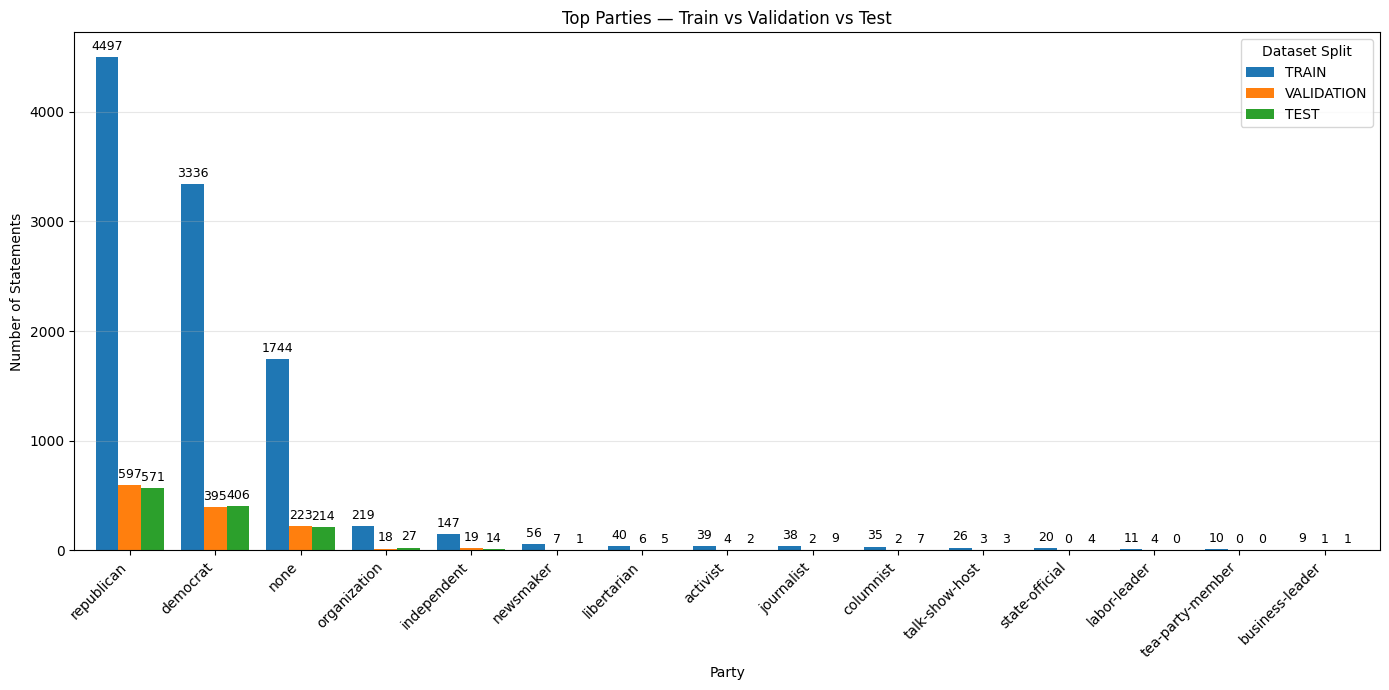

In [ ]:
# 4.6.1 PARTY DISTRIBUTION


def analyze_party_distribution(dataset_splits, top_n=15):
    """
    Analyze and visualize the most frequent parties
    across Train, Validation, and Test datasets.
    """

    # --------------------------------------------------------
    # Identify top parties using TRAINING data
    # --------------------------------------------------------

    train_party = (
        dataset_splits["TRAIN"]["party"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

    top_parties = (
        train_party
        .value_counts()
        .head(top_n)
        .index
    )


    # --------------------------------------------------------
    # Create party count table for all splits
    # --------------------------------------------------------

    party_counts = {}

    for split_name, dataframe in dataset_splits.items():

        party = (
            dataframe["party"]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
        )

        counts = party.value_counts()

        counts = counts.reindex(
            top_parties,
            fill_value=0
        )

        party_counts[split_name] = counts


    # --------------------------------------------------------
    # Combine results
    # --------------------------------------------------------

    party_summary = pd.DataFrame(party_counts)

    party_summary = party_summary[
        ["TRAIN", "VALIDATION", "TEST"]
    ]


    # --------------------------------------------------------
    # Display count table
    # --------------------------------------------------------

    print(
        f"{'=' * 70}\n"
        f"TOP {top_n} PARTIES — TRAIN / VALIDATION / TEST\n"
        f"{'=' * 70}"
    )

    display(party_summary)


    # --------------------------------------------------------
    # Create comparison graph
    # --------------------------------------------------------

    ax = party_summary.plot(
        kind="bar",
        figsize=(14, 7),
        width=0.8
    )


    # --------------------------------------------------------
    # Add count labels above every bar
    # --------------------------------------------------------

    for container in ax.containers:

        ax.bar_label(
            container,
            fmt="%d",
            padding=3,
            fontsize=9
        )


    # --------------------------------------------------------
    # Add title and axis labels
    # --------------------------------------------------------

    plt.title(
        "Top Parties — Train vs Validation vs Test"
    )

    plt.xlabel("Party")

    plt.ylabel("Number of Statements")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.legend(
        title="Dataset Split"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # Return results
    # --------------------------------------------------------

    return party_summary


# ------------------------------------------------------------
# Generate party distribution analysis
# ------------------------------------------------------------

party_distribution_results = analyze_party_distribution(
    dataset_splits,
    top_n=15
)

### 4.6.1 Party Distribution — Findings

The party distribution shows a strong concentration of statements in a small number of categories.

| Observation | Finding |
|---|---|
| Dominant categories | `republican`, `democrat`, and `none` contain the majority of statements |
| Minor categories | Several party categories contain very few observations |
| Class imbalance | Party categories are highly imbalanced |
| Generalization concern | Rare party categories may provide insufficient information for reliable modeling |
| Modeling decision | Party will not be automatically used as a primary feature; its inclusion will be evaluated separately |

### Conclusion

The party feature is highly imbalanced and may introduce **speaker or political-group bias** if directly used for prediction.

Therefore, we will keep the party information available for analysis but will **not automatically include it in the main text-based models**.

The primary models will focus on the **statement text**, while metadata features such as party can be evaluated separately if required.

> **Important:** We will make the final decision about using party as a model feature after discussing it with the curator.

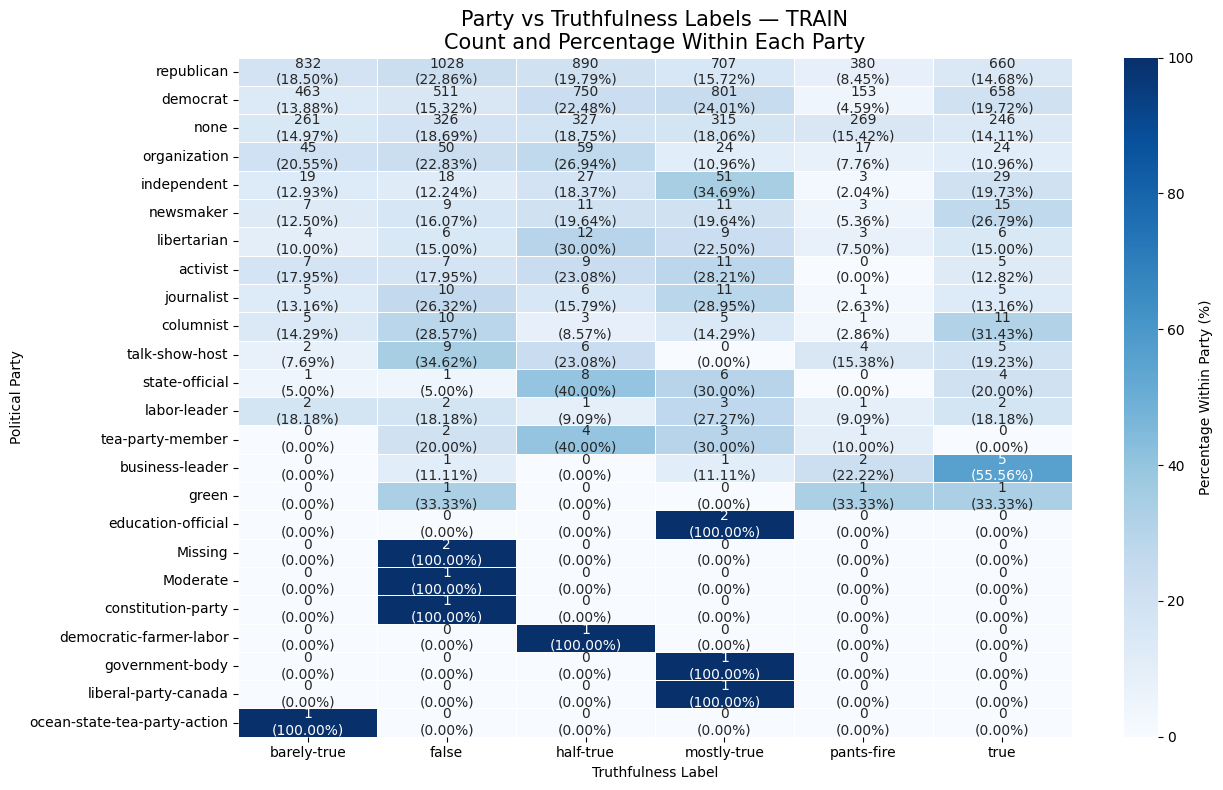

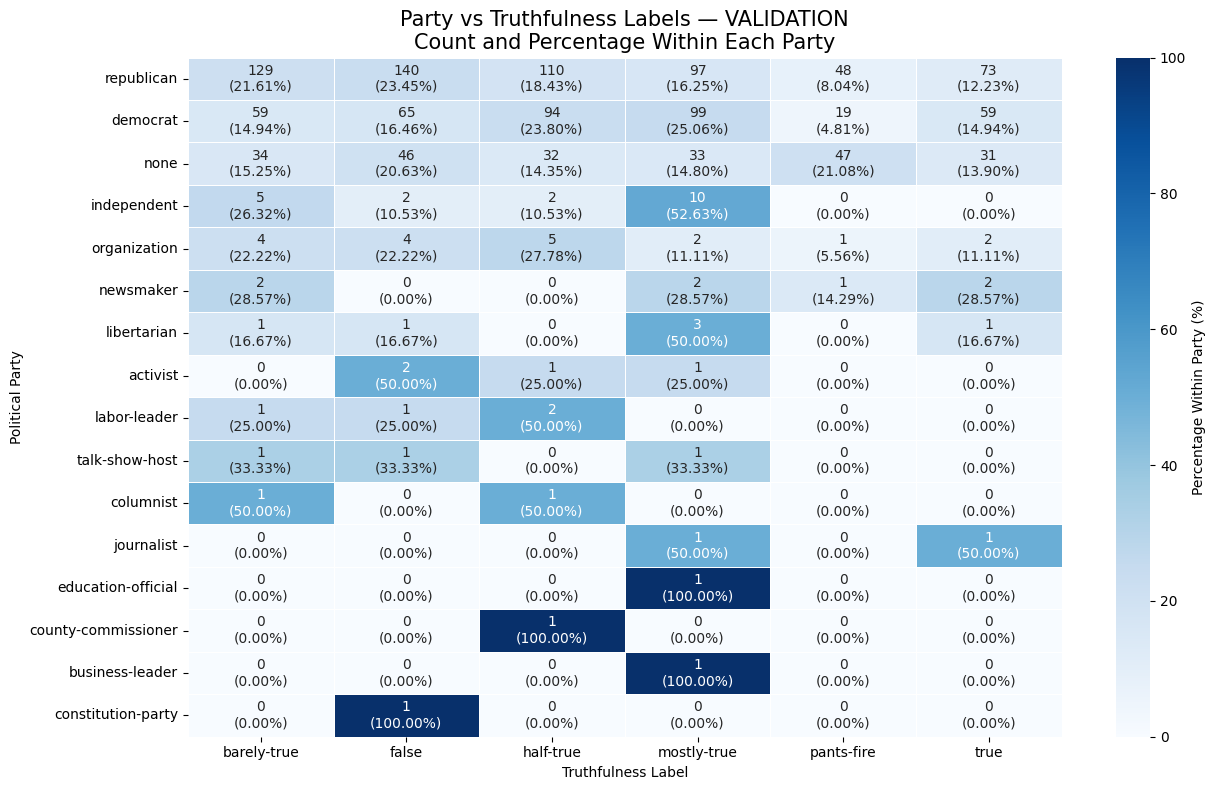

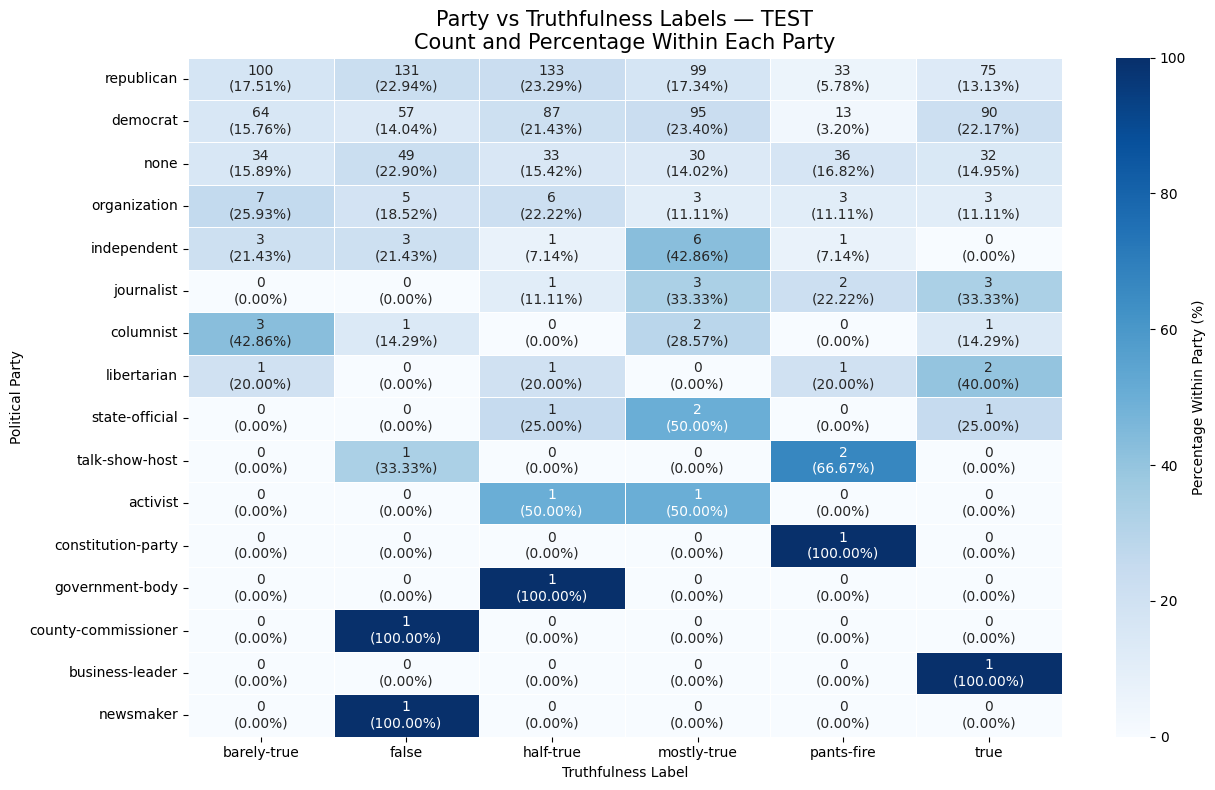

In [ ]:
# 4.6.2 PARTY VS TRUTHFULNESS ANALYSIS
# Count + Percentage Within Each Party

#
# This cell:
# 1. Creates a party vs truthfulness count table.
# 2. Calculates percentages within each party.
# 3. Sorts parties by total statement count.
# 4. Uses percentage for heatmap color intensity.
# 5. Displays count and percentage together in each cell.
# 6. Generates the same analysis for Train, Validation, and Test.
# ============================================================


# Import required libraries.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# Function for Party vs Truthfulness Analysis
# ------------------------------------------------------------

def plot_party_truthfulness_relationship(dataset_splits):

    # Define the expected truthfulness label order.
    label_order = [
        "barely-true",
        "false",
        "half-true",
        "mostly-true",
        "pants-fire",
        "true"
    ]


    # Process each dataset split separately.
    for split_name, dataframe in dataset_splits.items():

        # Create a working copy.
        working_data = dataframe.copy()


        # Replace missing party values with a readable category.
        working_data["party"] = working_data["party"].fillna("Missing")


        # ----------------------------------------------------
        # Create count table.
        # ----------------------------------------------------

        party_label_counts = pd.crosstab(
            working_data["party"],
            working_data["label"]
        )


        # Ensure all truthfulness labels are present
        # and arranged in the required order.
        party_label_counts = party_label_counts.reindex(
            columns=label_order,
            fill_value=0
        )


        # ----------------------------------------------------
        # Sort parties by total number of statements.
        # ----------------------------------------------------

        party_totals = party_label_counts.sum(axis=1)

        party_label_counts = party_label_counts.loc[
            party_totals.sort_values(
                ascending=False
            ).index
        ]


        # ----------------------------------------------------
        # Calculate percentage within each party.
        # ----------------------------------------------------

        party_label_percentages = (
            party_label_counts
            .div(
                party_label_counts.sum(axis=1),
                axis=0
            )
            * 100
        )


        # ----------------------------------------------------
        # Create annotation showing:
        # Count
        # Percentage
        # ----------------------------------------------------

        annotations = party_label_counts.copy().astype(object)

        for party in party_label_counts.index:

            for label in party_label_counts.columns:

                count = party_label_counts.loc[
                    party,
                    label
                ]

                percentage = party_label_percentages.loc[
                    party,
                    label
                ]

                annotations.loc[
                    party,
                    label
                ] = f"{count}\n({percentage:.2f}%)"


        # ----------------------------------------------------
        # Create heatmap.
        # Color is based on percentage.
        # ----------------------------------------------------

        plt.figure(figsize=(13, 8))

        sns.heatmap(
            party_label_percentages,
            annot=annotations,
            fmt="",
            cmap="Blues",
            linewidths=0.5,
            cbar_kws={
                "label": "Percentage Within Party (%)"
            }
        )


        # ----------------------------------------------------
        # Graph title and labels.
        # ----------------------------------------------------

        plt.title(
            f"Party vs Truthfulness Labels — {split_name}\n"
            "Count and Percentage Within Each Party",
            fontsize=15
        )

        plt.xlabel(
            "Truthfulness Label"
        )

        plt.ylabel(
            "Political Party"
        )


        # Adjust layout.
        plt.tight_layout()

        # Display graph.
        plt.show()


# ------------------------------------------------------------
# Run analysis for Train, Validation, and Test.
# ------------------------------------------------------------

plot_party_truthfulness_relationship(
    dataset_splits
)

### Findings

- The Republican, Democrat, and "none" categories contain the largest number of statements across all three dataset splits, while several other party categories have relatively few observations.
- For the major party categories, the truthfulness labels are distributed across multiple classes rather than being concentrated in a single label.
- The Republican category shows a relatively balanced distribution across the major truthfulness labels, with `false` and `half-true` among the more represented categories.
- The Democrat category also contains substantial representation across `false`, `half-true`, `mostly-true`, and `true`, indicating variation in truthfulness labels.
- Several small party categories show very high percentages for individual labels; however, these percentages are based on very small numbers of statements and should not be interpreted as strong evidence of a relationship.
- The overall pattern is reasonably consistent between Train, Validation, and Test for the major party categories, although smaller categories naturally show greater variation.
- This analysis indicates that party may contain useful contextual information, but its usefulness for prediction should be evaluated carefully because some party categories have very limited observations.

## 5. TARGET DEFINITION

## 5.1 Six-Class to Binary Target Mapping

The original LIAR truthfulness labels are preserved.

For the binary classification task, the labels are grouped as follows:

| Original LIAR Label | Binary Target |
|---|---|
| `true` | REAL |
| `mostly-true` | REAL |
| `half-true` | REAL |
| `barely-true` | FAKE |
| `false` | FAKE |
| `pants-fire` | FAKE |

The original `label` column will remain unchanged.

A separate `binary_label` column will be created for the binary
classification task.

In [ ]:
# 5.1 CREATE BINARY TARGET

#
# This cell:
# 1. Preserves the original six-class label.
# 2. Creates a new binary_label column.
# 3. Applies the same mapping to Train, Validation, and Test.
# 4. Verifies that every original label was mapped correctly.
# ============================================================


# ------------------------------------------------------------
# Define the six-to-two label mapping.
# ------------------------------------------------------------

binary_label_mapping = {
    "true": "REAL",
    "mostly-true": "REAL",
    "half-true": "REAL",
    "barely-true": "FAKE",
    "false": "FAKE",
    "pants-fire": "FAKE"
}


# ------------------------------------------------------------
# Function to create the binary target.
# ------------------------------------------------------------

def create_binary_target(dataset_splits, label_mapping):

    updated_splits = {}


    # --------------------------------------------------------
    # Process every dataset split.
    # --------------------------------------------------------

    for split_name, dataframe in dataset_splits.items():

        # Create a copy so the original DataFrame is not
        # modified unexpectedly.
        working_data = dataframe.copy()


        # ----------------------------------------------------
        # Create the binary target.
        # ----------------------------------------------------

        working_data["binary_label"] = (
            working_data["label"]
            .map(label_mapping)
        )


        # ----------------------------------------------------
        # Verify that no label failed to map.
        # ----------------------------------------------------

        unmapped_labels = working_data.loc[
            working_data["binary_label"].isna(),
            "label"
        ].unique()


        if len(unmapped_labels) > 0:

            raise ValueError(
                f"Unmapped labels found in {split_name}: "
                f"{unmapped_labels}"
            )


        # Store the updated dataset.
        updated_splits[split_name] = working_data


    return updated_splits


# ------------------------------------------------------------
# Create binary target for all dataset splits.
# ------------------------------------------------------------

dataset_splits = create_binary_target(
    dataset_splits,
    binary_label_mapping
)


# ------------------------------------------------------------
# Verify the resulting target distribution.
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    print(
        f"\n{'=' * 70}\n"
        f"{split_name} — BINARY TARGET DISTRIBUTION\n"
        f"{'=' * 70}"
    )

    display(
        dataframe["binary_label"]
        .value_counts()
        .rename_axis("binary_label")
        .reset_index(name="count")
    )


TRAIN — BINARY TARGET DISTRIBUTION


,binary_label,count
0,REAL,5752
1,FAKE,4488



VALIDATION — BINARY TARGET DISTRIBUTION


,binary_label,count
0,REAL,668
1,FAKE,616



TEST — BINARY TARGET DISTRIBUTION


,binary_label,count
0,REAL,714
1,FAKE,553


## 5.1 Binary Target Distribution — Findings

The original six-class LIAR labels were successfully mapped into two binary
classes: `REAL` and `FAKE`.

| Dataset Split | REAL | FAKE | Total |
|---|---:|---:|---:|
| Train | 5,752 | 4,488 | 10,240 |
| Validation | 668 | 616 | 1,284 |
| Test | 714 | 553 | 1,267 |

### Key Findings

- The Train dataset contains 5,752 REAL statements and 4,488 FAKE statements.
- The Validation dataset contains 668 REAL statements and 616 FAKE statements.
- The Test dataset contains 714 REAL statements and 553 FAKE statements.
- REAL statements are more frequent than FAKE statements in all three splits.
- The class distribution is not perfectly balanced, but both classes have
  substantial representation in every split.
- The relative distribution is reasonably similar across Train, Validation,
  and Test, which is important for consistent model evaluation.

### Target Definition

The original six-class `label` column is preserved, while the new
`binary_label` column is used for the REAL/FAKE classification task.

No records were removed during target creation.

#### 5.2 SAVE BINARY LABEL MAPPING

In [ ]:
# 5.2 SAVE BINARY LABEL MAPPING


# This cell saves the binary label mapping as an artifact.
# The same mapping will be loaded later during deployment
# to ensure that predictions use the same REAL/FAKE definitions.
# ============================================================


# Import pickle for saving the Python dictionary.
import pickle


# ------------------------------------------------------------
# Define the artifact path
# ------------------------------------------------------------

# Store the mapping inside the project artifacts directory.
BINARY_LABEL_MAPPING_PATH = (
    ARTIFACTS_DIR / "binary_label_mapping.pkl"
)


# ------------------------------------------------------------
# Save the mapping
# ------------------------------------------------------------

# Save the exact mapping used during target creation.
with open(BINARY_LABEL_MAPPING_PATH, "wb") as file:

    pickle.dump(binary_label_mapping, file)


# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------

print(
    f"Binary label mapping saved successfully:\n"
    f"{BINARY_LABEL_MAPPING_PATH}"
)

Binary label mapping saved successfully:
/content/drive/MyDrive/Ai_project/P22/artifacts/binary_label_mapping.pkl


## 6. TEXT CLEANING

In [ ]:
# 6.1 REUSABLE TEXT CLEANING FUNCTION

#
# This function:
# 1. Converts text to lowercase.
# 2. Removes URLs.
# 3. Removes unnecessary special characters.
# 4. Normalizes whitespace.
# 5. Preserves the original statement.
# ============================================================

# Import regular expression library.
import re


# ------------------------------------------------------------
# Function to clean statement text.
# ------------------------------------------------------------

def clean_statement(text):

    # Convert text to string.
    text = str(text)

    # Convert text to lowercase.
    text = text.lower()

    # Remove URLs.
    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    # Keep letters, numbers, spaces and basic punctuation.
    text = re.sub(
        r"[^a-z0-9\s.,!?'-]",
        " ",
        text
    )

    # Replace multiple spaces with a single space.
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    # Remove spaces from the beginning and end.
    text = text.strip()

    return text

In [ ]:
# 6.2 APPLY TEXT CLEANING TO ALL DATASET SPLITS

#
# This cell applies the same cleaning function to the statement
# column of Train, Validation, and Test datasets.
# ============================================================


# Apply the cleaning function to every dataset split.
for split_name, dataframe in dataset_splits.items():

    # Create a separate cleaned text column.
    dataframe["cleaned_statement"] = (
        dataframe["statement"]
        .apply(clean_statement)
    )


# Display confirmation.
for split_name, dataframe in dataset_splits.items():

    print(
        f"{split_name}: "
        f"{dataframe['cleaned_statement'].notna().all()}"
    )

TRAIN: True
VALIDATION: True
TEST: True


In [ ]:
# 6.3 CLEANED TEXT VERIFICATION

#
# This cell compares original statements with their cleaned
# versions for a small sample from each dataset split.
# ============================================================


# Number of examples to display.
sample_size = 5


# Check each dataset split.
for split_name, dataframe in dataset_splits.items():

    print(
        f"\n{'=' * 80}\n"
        f"{split_name} — ORIGINAL VS CLEANED STATEMENTS\n"
        f"{'=' * 80}"
    )

    # Select a small sample.
    comparison = dataframe[
        ["statement", "cleaned_statement"]
    ].sample(
        n=min(sample_size, len(dataframe)),
        random_state=42
    )

    # Display the comparison.
    display(comparison)


TRAIN — ORIGINAL VS CLEANED STATEMENTS


,statement,cleaned_statement
3842,Polling shows that nearly 74 percent of National Rifle Association members support requiring bac...,polling shows that nearly 74 percent of national rifle association members support requiring bac...
6480,I left the city with $43 million in the bank.,i left the city with 43 million in the bank.
4521,"Says she couldn't take stimulus money because it required ""universal building codes.""",says she couldn't take stimulus money because it required universal building codes.
4026,The United States is the only industrialized country that does not guarantee paid time off to ca...,the united states is the only industrialized country that does not guarantee paid time off to ca...
10111,The Health Care and Education Reconciliation Act is the largest-ever investment in higher educat...,the health care and education reconciliation act is the largest-ever investment in higher educat...



VALIDATION — ORIGINAL VS CLEANED STATEMENTS


,statement,cleaned_statement
1244,On the Cuba embargo,on the cuba embargo
331,My campaign alone has created more jobs in the state of Rhode Island than Narragansett Beer.,my campaign alone has created more jobs in the state of rhode island than narragansett beer.
1005,"Since 1981, reconciliation has been used 21 times. Most of it's been used by Republicans.","since 1981, reconciliation has been used 21 times. most of it's been used by republicans."
411,The state GOP ticket says their top priority is a career-long mission to outlaw abortion in all ...,the state gop ticket says their top priority is a career-long mission to outlaw abortion in all ...
1204,The Dodd-Frank financial-reform laws hundreds of new rules will force small banks and credit uni...,the dodd-frank financial-reform laws hundreds of new rules will force small banks and credit uni...



TEST — ORIGINAL VS CLEANED STATEMENTS


,statement,cleaned_statement
1211,On recess appointments.,on recess appointments.
1039,White men account for 69 percent of those arrested for violent crimes.,white men account for 69 percent of those arrested for violent crimes.
422,"When these same Republicans - including Mr. Boehner - were in charge, the number of earmarks and...","when these same republicans - including mr. boehner - were in charge, the number of earmarks and..."
1119,There is no clinical evidence that vaccinating healthcare workers protects patients.,there is no clinical evidence that vaccinating healthcare workers protects patients.
848,"Even among second and third generation Muslims in the United States, theres no real assimilation.","even among second and third generation muslims in the united states, theres no real assimilation."


## 6.3 Text Cleaning — Findings

The text-cleaning process was successfully applied to the Train, Validation,
and Test datasets.

The verification samples confirm that:

- Text was converted to lowercase consistently.
- Meaningful words and numerical information were preserved.
- URLs and unnecessary unwanted characters are removed by the cleaning rules.
- Basic punctuation and meaningful textual structure are retained.
- The original `statement` column remains unchanged.
- The cleaned text is stored separately in `cleaned_statement`.
- The same cleaning function is applied consistently across all three splits.
- Stopword removal and lemmatization were not applied at this stage because
  preprocessing requirements may differ across the TF-IDF, BiLSTM, and BERT
  models.

The cleaned statements are now ready for further text analysis.



## Model-Specific Text Processing

The common text cleaning steps are applied before model-specific processing.  
The remaining preprocessing differs because each model uses a different way
of representing text.

### 1. TF-IDF + Logistic Regression / Linear SVM

Cleaned text
      ↓
TF-IDF Vectorization
      ↓
Numerical feature matrix
      ↓
Logistic Regression / Linear SVM

- No separate tokenization is required because TF-IDF performs token-based
feature extraction internally.
- Stopword removal is not required.
- Lemmatization is not required.
- TF-IDF converts the cleaned text into numerical features based on word
importance.
- These numerical features are then used by Logistic Regression and
Linear SVM for classification.


**More specifically:**

- Tokenization: TF-IDF internally breaks text into tokens when building the vocabulary, so we don't need a separate tokenizer like we do for BiLSTM.
- Lemmatization: TF-IDF can work directly with the cleaned words; lemmatization is not a technical requirement for LR/SVM.
- Stopword removal: It is optional, not mandatory. We can let TF-IDF determine the importance of terms through its weighting rather than automatically removing them.


### 2. BiLSTM + Attention

Cleaned text
      ↓

Tokenization
      ↓
Integer sequences
      ↓
Padding
      ↓
BiLSTM + Attention
      ↓
REAL / FAKE


- Tokenization converts words into integer IDs.
- Padding makes sequences the same length for batch processing.
- The BiLSTM processes the sequence in both directions.
- Attention helps the model focus on important parts of the statement.



### 3. BERT

Cleaned text
      ↓
BERT Tokenizer
      ↓
Subword token IDs + Attention Mask
      ↓
Pre-trained BERT
      ↓
Classification Layer
      ↓
REAL / FAKE

- BERT uses its own pre-trained tokenizer.
- The tokenizer converts text into subword tokens and numerical IDs.
- BERT does not require our separate lemmatization step.
- The pre-trained BERT model provides contextual representations of the
input text.
- A classification layer uses these representations to predict REAL or FAKE.



**Why preprocessing differs between models**

Different models require different text representations. TF-IDF directly
creates numerical features from cleaned text, while BiLSTM requires
tokenized and padded sequences. BERT uses its own pre-trained subword
tokenizer. Therefore, preprocessing is kept model-specific rather than
applying every preprocessing step to every model.


| Model | Actual Model Input |
|---|---|
| **TF-IDF + LR/SVM** | TF-IDF feature matrix + 3 engineered features |
| **BiLSTM + Attention** | Padded integer token sequences |
| **BERT** | Input IDs + Attention Mask |

## 7. WORD FREQUENCY ANALYSIS

In [ ]:
# 7.1 MOST FREQUENT WORDS

#
# This cell:
# 1. Extracts words from cleaned statements.
# 2. Counts word frequencies.
# 3. Finds the most frequent words.
# 4. Performs the analysis separately for Train, Validation,
#    and Test.
# ============================================================


# Import Counter for efficient word-frequency counting.
from collections import Counter


# ------------------------------------------------------------
# Function to calculate word frequencies.
# ------------------------------------------------------------

def get_word_frequencies(dataset_splits, top_n=20):

    # Store the results for every dataset split.
    word_frequency_results = {}


    # Process each dataset split separately.
    for split_name, dataframe in dataset_splits.items():

        # Combine all cleaned statements into one text string.
        combined_text = " ".join(
            dataframe["cleaned_statement"]
            .fillna("")
            .astype(str)
        )


        # Split the combined text into individual words.
        words = combined_text.split()


        # Count how frequently each word occurs.
        word_counts = Counter(words)


        # Select the most frequent words.
        most_common_words = word_counts.most_common(top_n)


        # Convert the result into a DataFrame.
        frequency_table = pd.DataFrame(
            most_common_words,
            columns=["word", "count"]
        )


        # Store the result.
        word_frequency_results[split_name] = frequency_table


        # Display the result.
        print(
            f"\n{'=' * 70}\n"
            f"{split_name} — TOP {top_n} MOST FREQUENT WORDS\n"
            f"{'=' * 70}"
        )

        display(frequency_table)


    # Return all results.
    return word_frequency_results


# ------------------------------------------------------------
# Calculate word frequencies.
# ------------------------------------------------------------

word_frequency_results = get_word_frequencies(
    dataset_splits,
    top_n=20
)


TRAIN — TOP 20 MOST FREQUENT WORDS


,word,count
0,the,9778
1,in,5094
2,of,4801
3,to,4469
4,a,3667
5,and,2805
6,says,2361
7,for,2099
8,that,1812
9,is,1776



VALIDATION — TOP 20 MOST FREQUENT WORDS


,word,count
0,the,1281
1,of,595
2,in,577
3,to,548
4,a,471
5,and,344
6,says,294
7,for,258
8,that,217
9,is,216



TEST — TOP 20 MOST FREQUENT WORDS


,word,count
0,the,1214
1,in,645
2,of,605
3,to,569
4,a,492
5,and,382
6,says,306
7,for,244
8,is,237
9,that,224


## 7.1 Most Frequent Words — Findings

The word-frequency analysis was performed separately on the cleaned statements
of the Train, Validation, and Test datasets.

### Key Findings

- The most frequent words across all three splits are primarily common English
  function words such as `the`, `in`, `of`, `to`, `a`, and `and`.
- The word `says` is also highly frequent across all three splits and appears
  among the top words in each dataset.
- The word `percent` occurs frequently, reflecting the presence of
  statistical and numerical claims in the dataset.
- The ranking of the most frequent words is broadly similar across Train,
  Validation, and Test.
- This consistency suggests that the three dataset splits have broadly
  similar vocabulary patterns.
- Since common function words dominate the raw frequency counts, subsequent
  text analysis such as word clouds and n-grams should consider whether
  stopwords need to be excluded for more meaningful visualization.

In [ ]:
# 7.2 STOPWORD-AWARE WORD FREQUENCY ANALYSIS

#
# This analysis is for EDA only.
# It does NOT modify cleaned_statement.
# ============================================================

# Import NLTK stopwords.
from nltk.corpus import stopwords

# Download English stopwords if not already available.
import nltk
nltk.download("stopwords", quiet=True)

# Load English stopwords.
english_stopwords = set(stopwords.words("english"))


# ------------------------------------------------------------
# Function to calculate meaningful word frequencies.
# ------------------------------------------------------------

def get_stopword_filtered_frequencies(dataset_splits, top_n=20):

    stopword_frequency_results = {}

    for split_name, dataframe in dataset_splits.items():

        # Combine cleaned statements.
        combined_text = " ".join(
            dataframe["cleaned_statement"]
            .fillna("")
            .astype(str)
        )

        # Split into words.
        words = combined_text.split()

        # Remove stopwords.
        meaningful_words = [
            word
            for word in words
            if word not in english_stopwords
        ]

        # Count remaining words.
        word_counts = Counter(meaningful_words)

        # Get top words.
        most_common_words = word_counts.most_common(top_n)

        # Convert to DataFrame.
        frequency_table = pd.DataFrame(
            most_common_words,
            columns=["word", "count"]
        )

        # Store result.
        stopword_frequency_results[split_name] = frequency_table

        # Display result.
        print(
            f"\n{'=' * 70}\n"
            f"{split_name} — TOP {top_n} WORDS AFTER STOPWORD REMOVAL\n"
            f"{'=' * 70}"
        )

        display(frequency_table)

    return stopword_frequency_results


# ------------------------------------------------------------
# Calculate stopword-filtered word frequencies.
# ------------------------------------------------------------

stopword_frequency_results = get_stopword_filtered_frequencies(
    dataset_splits,
    top_n=20
)


TRAIN — TOP 20 WORDS AFTER STOPWORD REMOVAL


,word,count
0,says,2361
1,percent,969
2,state,698
3,obama,643
4,tax,607
5,health,591
6,people,550
7,would,538
8,president,534
9,new,463



VALIDATION — TOP 20 WORDS AFTER STOPWORD REMOVAL


,word,count
0,says,294
1,percent,113
2,health,101
3,state,89
4,obama,76
5,care,75
6,new,72
7,president,66
8,would,64
9,tax,63



TEST — TOP 20 WORDS AFTER STOPWORD REMOVAL


,word,count
0,says,306
1,percent,133
2,state,91
3,obama,80
4,tax,79
5,president,71
6,health,71
7,people,66
8,million,65
9,federal,61


## 7.2 Stopword-Aware Word Frequency — Findings

After removing common English stopwords, the frequency analysis provides a
more meaningful view of the vocabulary used in the statements.

### Key Findings

- `says` is the most frequent word across Train, Validation, and Test.
- `percent` is consistently among the most frequent words, reflecting the
  large number of statistical and numerical claims in the dataset.
- Other frequently occurring content words include `state`, `obama`, `tax`,
  `health`, `people`, `president`, `care`, `million`, and `federal`.
- Train, Validation, and Test exhibit broadly similar high-frequency
  vocabulary patterns.
- The similarity in vocabulary across the three splits provides evidence that
  their text distributions are broadly consistent.
- Related word forms such as `state` and `states` remain separate because
  stemming or lemmatization has not been applied.
- Stopword removal was used only for this exploratory analysis and does not
  modify the `cleaned_statement` column or determine the preprocessing used
  by the final models.

This stopword-aware vocabulary will be used for the subsequent word cloud
and n-gram analyses.

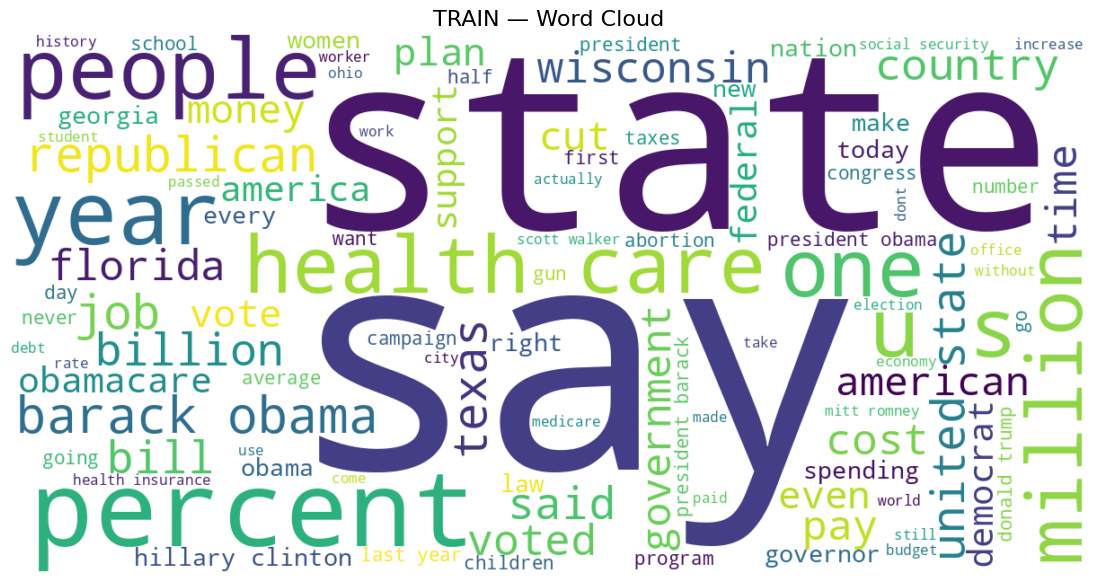

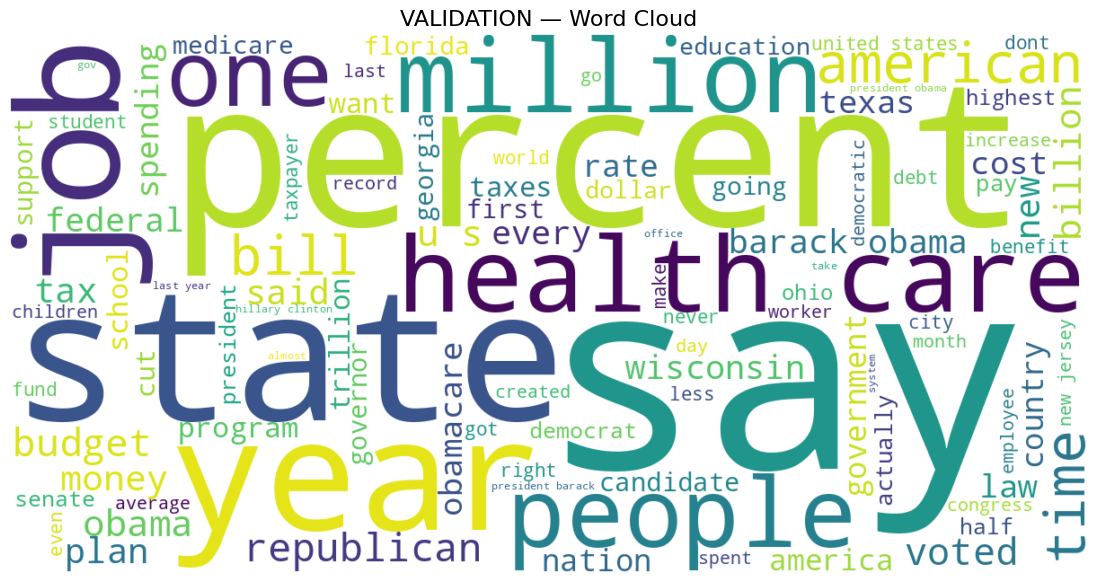

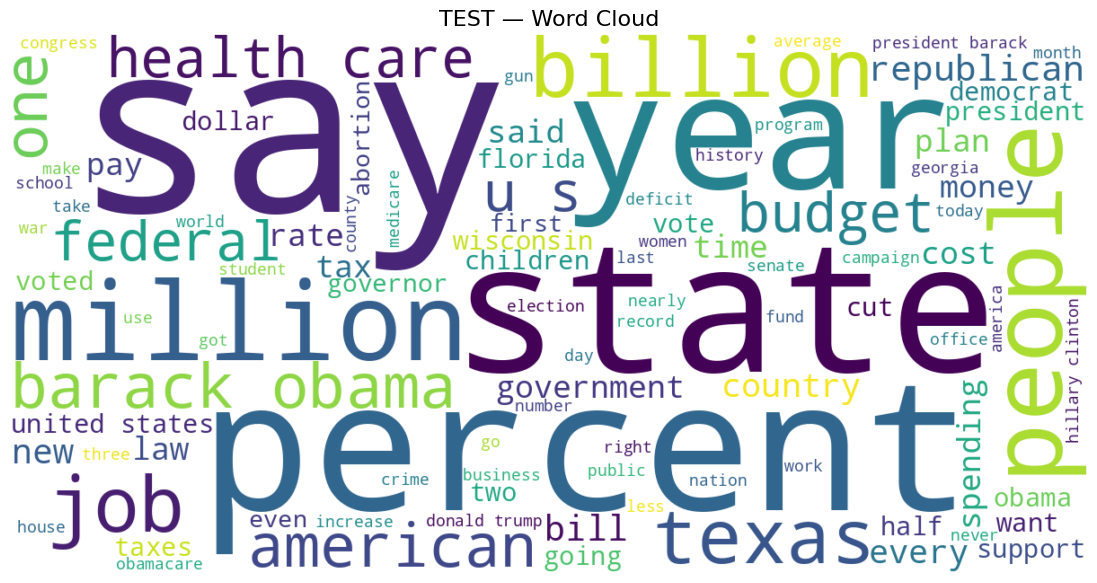

In [ ]:
# 7.3 WORD CLOUD ANALYSIS

#
# Creates a separate word cloud for Train, Validation, and Test.
# Stopwords are excluded for clearer visualization.
# ============================================================

from wordcloud import WordCloud
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Generate word clouds for each dataset split.
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    # Combine cleaned statements.
    combined_text = " ".join(
        dataframe["cleaned_statement"]
        .fillna("")
        .astype(str)
    )

    # Remove English stopwords.
    words = [
        word
        for word in combined_text.split()
        if word not in english_stopwords
    ]

    # Reconstruct stopword-filtered text.
    filtered_text = " ".join(words)

    # Create the word cloud.
    wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        max_words=100
    ).generate(filtered_text)

    # Display the word cloud.
    plt.figure(figsize=(14, 7))

    plt.imshow(
        wordcloud,
        interpolation="bilinear"
    )

    plt.axis("off")

    plt.title(
        f"{split_name} — Word Cloud",
        fontsize=16
    )

    plt.show()

## 7.4 Bigram Analysis

In [ ]:
# 7.4 BIGRAM ANALYSIS
# Top 20 Bigrams — Train / Validation / Test


from collections import Counter
from nltk.util import ngrams


# ------------------------------------------------------------
# Function to calculate bigram frequencies
# ------------------------------------------------------------

def get_bigram_frequencies(dataset_splits, top_n=20):

    bigram_frequency_results = {}

    for split_name, dataframe in dataset_splits.items():

        # Combine cleaned statements.
        combined_text = " ".join(
            dataframe["cleaned_statement"]
            .fillna("")
            .astype(str)
        )

        # Tokenize.
        words = combined_text.split()

        # Remove stopwords.
        meaningful_words = [
            word
            for word in words
            if word not in english_stopwords
        ]

        # Create bigrams.
        bigrams = list(ngrams(meaningful_words, 2))

        # Count bigrams.
        bigram_counts = Counter(bigrams)

        # Get top bigrams.
        most_common_bigrams = bigram_counts.most_common(top_n)

        # Convert tuples into readable phrases.
        frequency_table = pd.DataFrame(
            [
                (" ".join(bigram), count)
                for bigram, count in most_common_bigrams
            ],
            columns=["bigram", "count"]
        )

        bigram_frequency_results[split_name] = frequency_table

        # Display.
        print(
            f"\n{'=' * 70}\n"
            f"{split_name} — TOP {top_n} MOST FREQUENT BIGRAMS\n"
            f"{'=' * 70}"
        )

        display(frequency_table)

    return bigram_frequency_results


# ------------------------------------------------------------
# Run bigram analysis
# ------------------------------------------------------------

bigram_frequency_results = get_bigram_frequencies(
    dataset_splits,
    top_n=20
)


TRAIN — TOP 20 MOST FREQUENT BIGRAMS


,bigram,count
0,health care,342
1,barack obama,254
2,united states,211
3,hillary clinton,157
4,president barack,153
5,. .,129
6,president obama,106
7,donald trump,106
8,mitt romney,90
9,says president,90



VALIDATION — TOP 20 MOST FREQUENT BIGRAMS


,bigram,count
0,health care,66
1,barack obama,27
2,president barack,19
3,social security,15
4,new jersey,15
5,president obama,14
6,united states,14
7,hillary clinton,14
8,says president,13
9,gov. scott,13



TEST — TOP 20 MOST FREQUENT BIGRAMS


,bigram,count
0,health care,44
1,barack obama,37
2,president barack,26
3,united states,24
4,donald trump,17
5,hillary clinton,15
6,0 0,15
7,mitt romney,14
8,says donald,14
9,says president,14


In [ ]:
# 7.5 TRIGRAM ANALYSIS
# Top 20 Trigrams — Train / Validation / Test


from nltk.util import ngrams
from collections import Counter


def get_trigram_frequencies(dataset_splits, top_n=20):

    trigram_frequency_results = {}

    for split_name, dataframe in dataset_splits.items():

        # Combine cleaned statements.
        combined_text = " ".join(
            dataframe["cleaned_statement"]
            .fillna("")
            .astype(str)
        )

        # Tokenize.
        words = combined_text.split()

        # Remove stopwords.
        meaningful_words = [
            word
            for word in words
            if word not in english_stopwords
        ]

        # Create trigrams.
        trigrams = list(ngrams(meaningful_words, 3))

        # Count trigrams.
        trigram_counts = Counter(trigrams)

        # Get top trigrams.
        most_common_trigrams = trigram_counts.most_common(top_n)

        # Convert tuples into readable phrases.
        frequency_table = pd.DataFrame(
            [
                (" ".join(trigram), count)
                for trigram, count in most_common_trigrams
            ],
            columns=["trigram", "count"]
        )

        trigram_frequency_results[split_name] = frequency_table

        # Display results.
        print(
            f"\n{'=' * 70}\n"
            f"{split_name} — TOP {top_n} MOST FREQUENT TRIGRAMS\n"
            f"{'=' * 70}"
        )

        display(frequency_table)

    return trigram_frequency_results


# ------------------------------------------------------------
# Run trigram analysis
# ------------------------------------------------------------

trigram_frequency_results = get_trigram_frequencies(
    dataset_splits,
    top_n=20
)


TRAIN — TOP 20 MOST FREQUENT TRIGRAMS


,trigram,count
0,president barack obama,104
1,says hillary clinton,71
2,. . .,62
3,says donald trump,60
4,says president barack,59
5,says mitt romney,49
6,health care law,46
7,gov. scott walker,44
8,says barack obama,40
9,president barack obamas,35



VALIDATION — TOP 20 MOST FREQUENT TRIGRAMS


,trigram,count
0,health care law,10
1,gov. scott walker,9
2,president barack obamas,9
3,says donald trump,8
4,president barack obama,8
5,says president barack,7
6,says hillary clinton,7
7,health care reform,5
8,health care plan,5
9,. . .,5



TEST — TOP 20 MOST FREQUENT TRIGRAMS


,trigram,count
0,president barack obama,15
1,says donald trump,11
2,says president barack,9
3,president barack obamas,8
4,0 0 0,8
5,0 1 0,7
6,says hillary clinton,6
7,says barack obama,5
8,health care reform,5
9,says mitt romney,4


## 8. FEATURE ENGINEERING

In [ ]:
# 8.1 CAPS RATIO FEATURE


# This section:
# 1. Calculates the proportion of uppercase letters in each statement.
  # Caps ratio=No. of Uppercase alphabetic letters/Total no. of alphabetic letters
# 2. Uses the original statement so capitalization information is preserved.
# 3. Creates the caps_ratio feature for Train, Validation, and Test.
# ============================================================


# ------------------------------------------------------------
# Function to calculate uppercase-letter ratio
# ------------------------------------------------------------

def calculate_caps_ratio(text):

    # Return 0 if the input is not text.
    if not isinstance(text, str):
        return 0.0

    # Extract only alphabetic characters.
    # This prevents numbers, spaces, and punctuation from
    # affecting the capitalization ratio.
    letters = [
        char
        for char in text
        if char.isalpha()
    ]

    # Avoid division by zero when the statement contains
    # no alphabetic characters.
    if len(letters) == 0:
        return 0.0

    # Count the number of uppercase alphabetic characters.
    uppercase_letters = sum(
        char.isupper()
        for char in letters
    )

    # Calculate the proportion of uppercase letters.
    return uppercase_letters / len(letters)


# ------------------------------------------------------------
# Apply feature to Train / Validation / Test
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    # Calculate the capitalization ratio using the original
    # statement so that the original capitalization is preserved.
    dataframe["caps_ratio"] = (
        dataframe["statement"]
        .apply(calculate_caps_ratio)
    )


# ------------------------------------------------------------
# Verify the new feature
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    print(
        f"{split_name}: "
        f"caps_ratio feature created successfully"
    )

TRAIN: caps_ratio feature created successfully
VALIDATION: caps_ratio feature created successfully
TEST: caps_ratio feature created successfully


In [ ]:
# 8.1 CAPS RATIO — SUMMARY


# This section:
# 1. Summarizes the caps_ratio feature.
# 2. Performs the summary separately for Train, Validation, and Test.
# 3. Helps verify the range and distribution of the feature.
# ============================================================


# ------------------------------------------------------------
# Display caps_ratio summary for each dataset split
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    # Display a clear heading for the current split.
    print("=" * 70)
    print(f"{split_name} — CAPS RATIO")
    print("=" * 70)

    # Display descriptive statistics for the caps_ratio feature.
    display(
        dataframe["caps_ratio"].describe()
    )

    print()

TRAIN — CAPS RATIO


,caps_ratio
count,10240.000000
mean,0.046125
std,0.032603
min,0.000000
25%,0.023810
50%,0.039683
75%,0.060000
max,1.000000



VALIDATION — CAPS RATIO


,caps_ratio
count,1284.000000
mean,0.046062
std,0.043708
min,0.000000
25%,0.023256
50%,0.038586
75%,0.057881
max,1.000000



TEST — CAPS RATIO


,caps_ratio
count,1267.000000
mean,0.045942
std,0.031106
min,0.000000
25%,0.023256
50%,0.040000
75%,0.059915
max,0.257143


### 8.1 Caps Ratio — Findings

The capitalization ratio was calculated from the original `statement` column
for Train, Validation, and Test.

### Key Findings

- The mean caps ratio is highly consistent across all three splits:
  - Train: 0.0461
  - Validation: 0.0461
  - Test: 0.0459
- The median caps ratio is also similar across the three splits.
- Most statements contain a relatively small proportion of uppercase
  alphabetic characters.
- Train and Validation contain some statements with a caps ratio of 1.0,
  indicating statements written entirely in uppercase alphabetic characters.
- These observations are retained because a high caps ratio does not
  necessarily indicate an erroneous record.
- Overall, the caps ratio shows consistent behavior across the three
  dataset splits.

In [ ]:
# 8.2 EXCLAMATION COUNT FEATURE


# This section:
# 1. Counts the number of exclamation marks in each statement.
# 2. Uses the original statement so punctuation is preserved.
# 3. Creates the exclamation_count feature for Train, Validation,
#    and Test.
# ============================================================


# ------------------------------------------------------------
# Calculate exclamation count
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    # Count the number of "!" characters in each statement.
    # Missing values are replaced with an empty string first.
    dataframe["exclamation_count"] = (
        dataframe["statement"]
        .fillna("")
        .astype(str)
        .str.count("!")
    )

In [ ]:
# 8.2 EXCLAMATION COUNT — SUMMARY


# This section:
# 1. Summarizes the exclamation_count feature.
# 2. Performs the summary separately for Train, Validation, and Test.
# 3. Helps verify the range and distribution of the feature.
# ============================================================


# ------------------------------------------------------------
# Display exclamation_count summary for each dataset split
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    # Display a clear heading for the current split.
    print("=" * 70)
    print(f"{split_name} — EXCLAMATION COUNT")
    print("=" * 70)

    # Display descriptive statistics for the feature.
    display(
        dataframe["exclamation_count"].describe()
    )

    print()

TRAIN — EXCLAMATION COUNT


,exclamation_count
count,10240.000000
mean,0.007129
std,0.108475
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,5.000000



VALIDATION — EXCLAMATION COUNT


,exclamation_count
count,1284.000000
mean,0.006231
std,0.088065
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,2.000000



TEST — EXCLAMATION COUNT


,exclamation_count
count,1267.000000
mean,0.003946
std,0.062721
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


## 8.2 Exclamation Count — Findings

The exclamation count was calculated from the original `statement` column for
Train, Validation, and Test.

### Key Findings

- The median exclamation count is 0 for all three dataset splits.
- The 75th percentile is also 0 across all three splits, indicating that at
  least 75% of statements contain no exclamation marks.
- The mean exclamation count is very low:
  - Train: 0.0071
  - Validation: 0.0062
  - Test: 0.0039
- The maximum exclamation counts are 5 for Train, 2 for Validation, and 1
  for Test.
- Overall, exclamation marks are rare in the dataset, but the feature is
  retained so that the models can determine whether this signal is useful.

In [ ]:
# 8.3 QUESTION-MARK COUNT FEATURE


# This section:
# 1. Counts the number of question marks in each statement.
# 2. Uses the original statement so punctuation is preserved.
# 3. Creates the question_mark_count feature for Train, Validation,
#    and Test.
# ============================================================


# ------------------------------------------------------------
# Calculate question-mark count
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    # Count the number of "?" characters in each statement.
    # Missing values are replaced with an empty string first.
    dataframe["question_mark_count"] = (
        dataframe["statement"]
        .fillna("")
        .astype(str)
        .str.count(r"\?")
    )

In [ ]:
# 8.3 QUESTION-MARK COUNT — SUMMARY


# This section:
# 1. Summarizes the question_mark_count feature.
# 2. Performs the summary separately for Train, Validation, and Test.
# 3. Helps verify the range and distribution of the feature.
# ============================================================


# ------------------------------------------------------------
# Display question_mark_count summary for each dataset split
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    # Display a clear heading for the current split.
    print("=" * 70)
    print(f"{split_name} — QUESTION-MARK COUNT")
    print("=" * 70)

    # Display descriptive statistics for the feature.
    display(
        dataframe["question_mark_count"].describe()
    )

    print()

TRAIN — QUESTION-MARK COUNT


,question_mark_count
count,10240.000000
mean,0.007324
std,0.089736
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,2.000000



VALIDATION — QUESTION-MARK COUNT


,question_mark_count
count,1284.000000
mean,0.006231
std,0.088065
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,2.000000



TEST — QUESTION-MARK COUNT


,question_mark_count
count,1267.000000
mean,0.011050
std,0.142881
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,4.000000


## 8.3 Question-Mark Count — Findings

The question-mark count was calculated from the original `statement` column
for Train, Validation, and Test.

### Key Findings

- The median question-mark count is 0 across all three dataset splits.
- The 75th percentile is also 0 for Train, Validation, and Test, indicating
  that question marks are uncommon in the statements.
- The mean question-mark count is very low:
  - Train: approximately 0.0073
  - Validation: approximately 0.0062
  - Test: approximately 0.0111
- The Test split has a slightly higher mean question-mark count than Train
  and Validation, but the overall frequency remains low.
- The maximum question-mark counts are 2 for Train, 2 for Validation, and 4
  for Test.
- The feature is retained without removing higher-count observations because
  they may represent legitimate characteristics of individual statements.
  

In [ ]:
# 8.4 ENGINEERED FEATURE FREQUENCY ANALYSIS


# This section:
# 1. Shows the frequency of each exclamation-mark count.
# 2. Shows the frequency of each question-mark count.
# 3. Groups caps_ratio into meaningful ranges and shows
#    the number of statements in each range.
# ============================================================


# ------------------------------------------------------------
# Frequency analysis for each dataset split
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    print("=" * 70)
    print(f"{split_name} — ENGINEERED FEATURE FREQUENCIES")
    print("=" * 70)


    # --------------------------------------------------------
    # Exclamation-count frequencies
    # --------------------------------------------------------

    print("\nExclamation Count Frequency:")

    exclamation_frequency = (
        dataframe["exclamation_count"]
        .value_counts()
        .sort_index()
        .rename_axis("exclamation_count")
        .reset_index(name="statement_count")
    )

    display(exclamation_frequency)


    # --------------------------------------------------------
    # Question-mark-count frequencies
    # --------------------------------------------------------

    print("\nQuestion-Mark Count Frequency:")

    question_frequency = (
        dataframe["question_mark_count"]
        .value_counts()
        .sort_index()
        .rename_axis("question_mark_count")
        .reset_index(name="statement_count")
    )

    display(question_frequency)


    # --------------------------------------------------------
    # Caps-ratio frequency by ranges
    # --------------------------------------------------------

    print("\nCaps Ratio Frequency:")

    caps_bins = [
        -0.001,
        0.00,
        0.05,
        0.10,
        0.20,
        0.50,
        1.00
    ]

    caps_labels = [
        "0",
        "(0, 0.05]",
        "(0.05, 0.10]",
        "(0.10, 0.20]",
        "(0.20, 0.50]",
        "(0.50, 1.00]"
    ]

    caps_frequency = pd.cut(
        dataframe["caps_ratio"],
        bins=caps_bins,
        labels=caps_labels,
        include_lowest=True
    ).value_counts().sort_index()

    caps_frequency = (
        caps_frequency
        .rename_axis("caps_ratio_range")
        .reset_index(name="statement_count")
    )

    display(caps_frequency)

    print()

TRAIN — ENGINEERED FEATURE FREQUENCIES

Exclamation Count Frequency:


,exclamation_count,statement_count
0,0,10180
1,1,54
2,2,2
3,3,2
4,4,1
5,5,1



Question-Mark Count Frequency:


,question_mark_count,statement_count
0,0,10169
1,1,67
2,2,4



Caps Ratio Frequency:


,caps_ratio_range,statement_count
0,0,19
1,"(0, 0.05]",6615
2,"(0.05, 0.10]",3058
3,"(0.10, 0.20]",519
4,"(0.20, 0.50]",28
5,"(0.50, 1.00]",1


... (8 outputs left out)


Question-Mark Count Frequency:


,question_mark_count,statement_count
0,0,1256
1,1,10
2,4,1



Caps Ratio Frequency:


,caps_ratio_range,statement_count
0,0,2
1,"(0, 0.05]",805
2,"(0.05, 0.10]",397
3,"(0.10, 0.20]",59
4,"(0.20, 0.50]",4
5,"(0.50, 1.00]",0


In [ ]:
# 8.4 ENGINEERED FEATURE FREQUENCY ANALYSIS BY LABEL
#
# This section:
# 1. Shows the frequency of each exclamation-mark count
#    separately for REAL and FAKE statements.
# 2. Shows the frequency of each question-mark count
#    separately for REAL and FAKE statements.
# 3. Groups caps_ratio into meaningful ranges and shows
#    REAL and FAKE counts for each range.
# 4. Performs the analysis for Train, Validation, and Test.
# ============================================================


# ------------------------------------------------------------
# Frequency analysis for each dataset split
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    print("=" * 80)
    print(f"{split_name} — ENGINEERED FEATURE FREQUENCIES BY LABEL")
    print("=" * 80)


    # ========================================================
    # 1. EXCLAMATION-COUNT FREQUENCY BY LABEL
    # ========================================================

    print("\nExclamation Count Frequency by Label:")

    exclamation_frequency = (
        dataframe
        .groupby(
            ["exclamation_count", "binary_label"]
        )
        .size()
        .unstack(fill_value=0)
    )

    # Make sure both label columns are present
    if "REAL" not in exclamation_frequency.columns:
        exclamation_frequency["REAL"] = 0

    if "FAKE" not in exclamation_frequency.columns:
        exclamation_frequency["FAKE"] = 0

    # Keep only REAL and FAKE and reset index
    exclamation_frequency = (
        exclamation_frequency[
            ["REAL", "FAKE"]
        ]
        .reset_index()
    )

    # Rename columns explicitly
    exclamation_frequency.columns = [
        "exclamation_count",
        "Real",
        "Fake"
    ]

    # Sort by exclamation count
    exclamation_frequency = (
        exclamation_frequency
        .sort_values("exclamation_count")
        .reset_index(drop=True)
    )

    display(exclamation_frequency)


    # ========================================================
    # 2. QUESTION-MARK COUNT FREQUENCY BY LABEL
    # ========================================================

    print("\nQuestion-Mark Count Frequency by Label:")

    question_frequency = (
        dataframe
        .groupby(
            ["question_mark_count", "binary_label"]
        )
        .size()
        .unstack(fill_value=0)
    )

    # Make sure both label columns are present
    if "REAL" not in question_frequency.columns:
        question_frequency["REAL"] = 0

    if "FAKE" not in question_frequency.columns:
        question_frequency["FAKE"] = 0

    # Keep only REAL and FAKE and reset index
    question_frequency = (
        question_frequency[
            ["REAL", "FAKE"]
        ]
        .reset_index()
    )

    # Rename columns explicitly
    question_frequency.columns = [
        "question_mark_count",
        "Real",
        "Fake"
    ]

    # Sort by question-mark count
    question_frequency = (
        question_frequency
        .sort_values("question_mark_count")
        .reset_index(drop=True)
    )

    display(question_frequency)


    # ========================================================
    # 3. CAPS-RATIO FREQUENCY BY RANGE AND LABEL
    # ========================================================

    print("\nCaps Ratio Frequency by Range and Label:")

    caps_bins = [
        -0.001,
        0.00,
        0.05,
        0.10,
        0.20,
        0.50,
        1.00
    ]

    caps_labels = [
        "0",
        "(0, 0.05]",
        "(0.05, 0.10]",
        "(0.10, 0.20]",
        "(0.20, 0.50]",
        "(0.50, 1.00]"
    ]

    # Create caps-ratio ranges
    caps_ratio_range = pd.cut(
        dataframe["caps_ratio"],
        bins=caps_bins,
        labels=caps_labels,
        include_lowest=True
    )

    # Count each caps-ratio range by label
    caps_frequency = (
        dataframe
        .assign(
            caps_ratio_range=caps_ratio_range
        )
        .groupby(
            ["caps_ratio_range", "binary_label"],
            observed=False
        )
        .size()
        .unstack(fill_value=0)
    )

    # Make sure both label columns are present
    if "REAL" not in caps_frequency.columns:
        caps_frequency["REAL"] = 0

    if "FAKE" not in caps_frequency.columns:
        caps_frequency["FAKE"] = 0

    # Keep REAL and FAKE and reset index
    caps_frequency = (
        caps_frequency[
            ["REAL", "FAKE"]
        ]
        .reset_index()
    )

    # Rename columns explicitly
    caps_frequency.columns = [
        "caps_ratio_range",
        "Real",
        "Fake"
    ]

    # Preserve the intended caps-ratio order
    caps_frequency["caps_ratio_range"] = pd.Categorical(
        caps_frequency["caps_ratio_range"],
        categories=caps_labels,
        ordered=True
    )

    caps_frequency = (
        caps_frequency
        .sort_values("caps_ratio_range")
        .reset_index(drop=True)
    )

    display(caps_frequency)

    print()

TRAIN — ENGINEERED FEATURE FREQUENCIES BY LABEL

Exclamation Count Frequency by Label:


,exclamation_count,Real,Fake
0,0,5728,4452
1,1,22,32
2,2,1,1
3,3,0,2
4,4,1,0
5,5,0,1



Question-Mark Count Frequency by Label:


,question_mark_count,Real,Fake
0,0,5716,4453
1,1,33,34
2,2,3,1



Caps Ratio Frequency by Range and Label:


,caps_ratio_range,Real,Fake
0,0,12,7
1,"(0, 0.05]",3919,2696
2,"(0.05, 0.10]",1594,1464
3,"(0.10, 0.20]",209,310
4,"(0.20, 0.50]",17,11
5,"(0.50, 1.00]",1,0


... (8 outputs left out)


Question-Mark Count Frequency by Label:


,question_mark_count,Real,Fake
0,0,711,545
1,1,2,8
2,4,1,0



Caps Ratio Frequency by Range and Label:


,caps_ratio_range,Real,Fake
0,0,2,0
1,"(0, 0.05]",482,323
2,"(0.05, 0.10]",206,191
3,"(0.10, 0.20]",23,36
4,"(0.20, 0.50]",1,3
5,"(0.50, 1.00]",0,0


TRAIN — ENGINEERED FEATURE VISUALIZATION


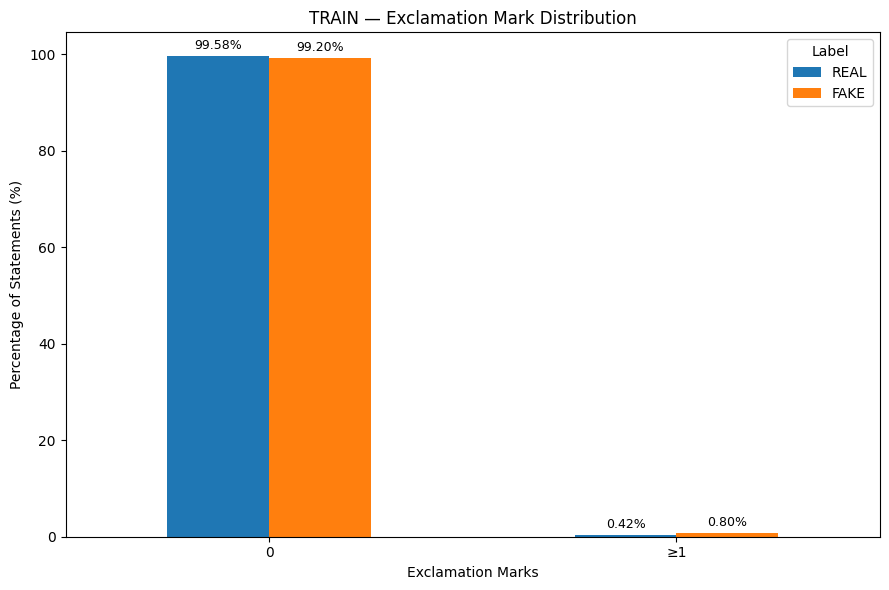

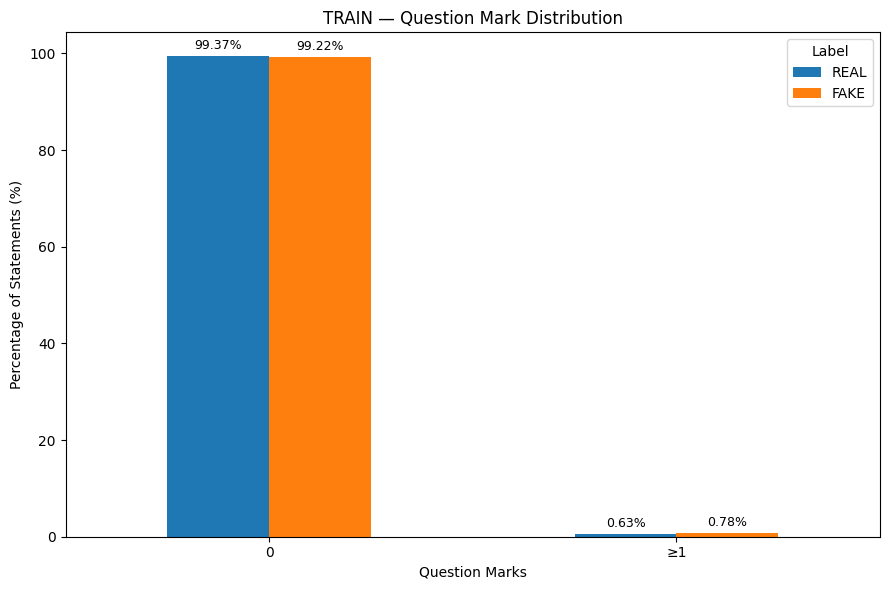

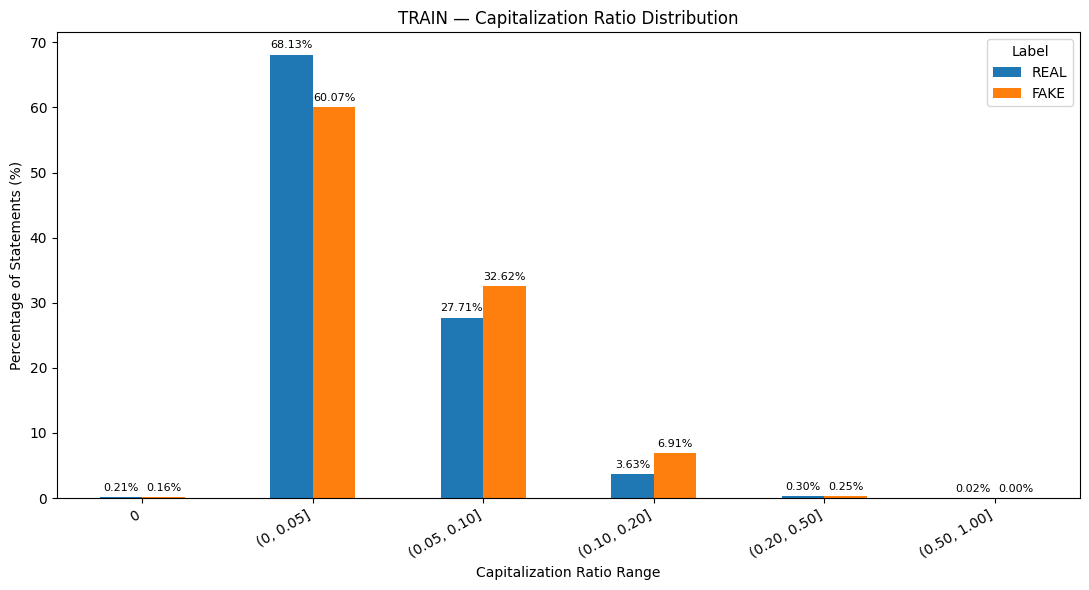

VALIDATION — ENGINEERED FEATURE VISUALIZATION


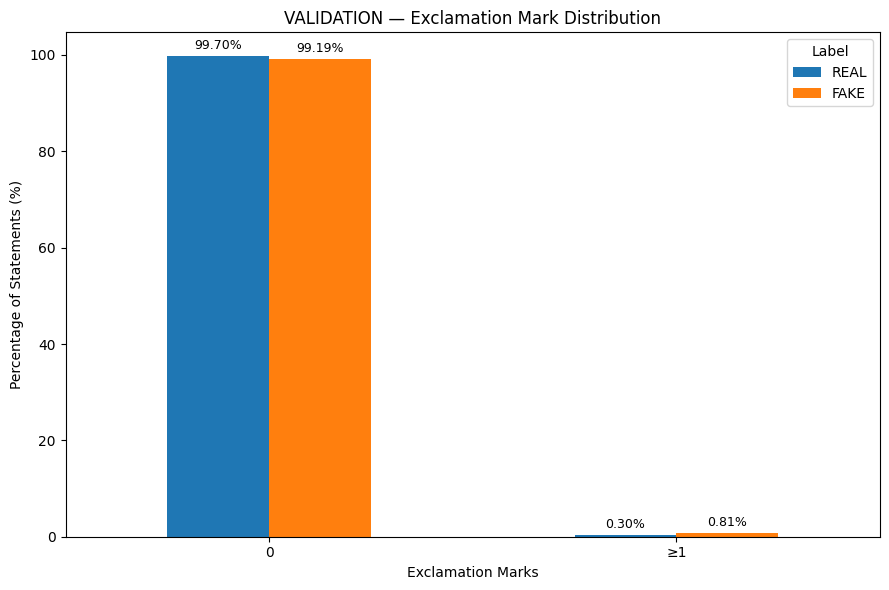

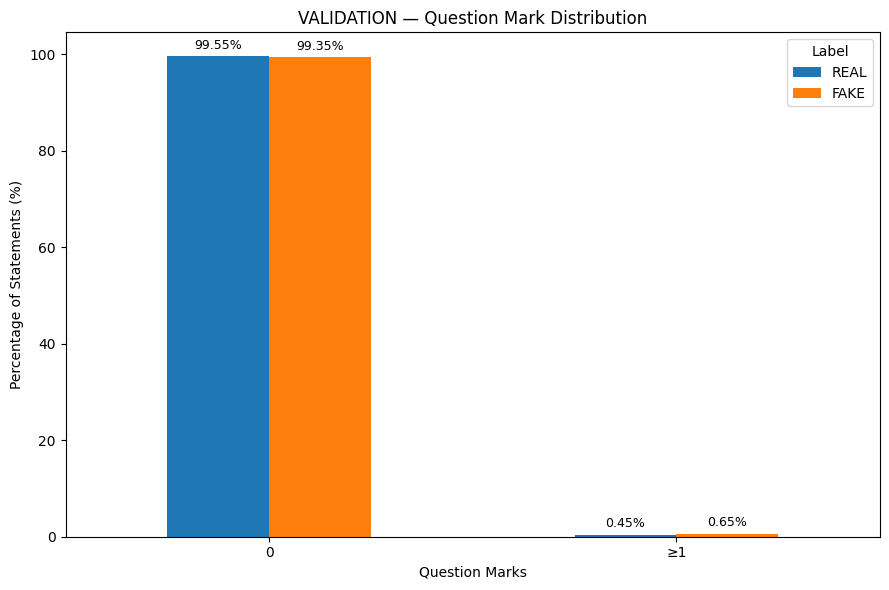

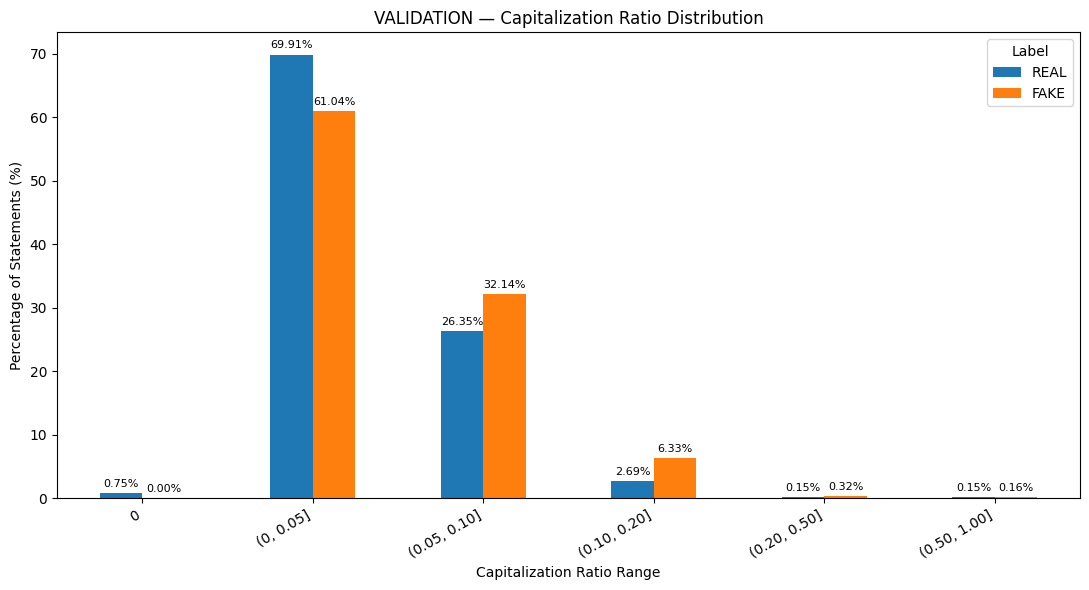

TEST — ENGINEERED FEATURE VISUALIZATION


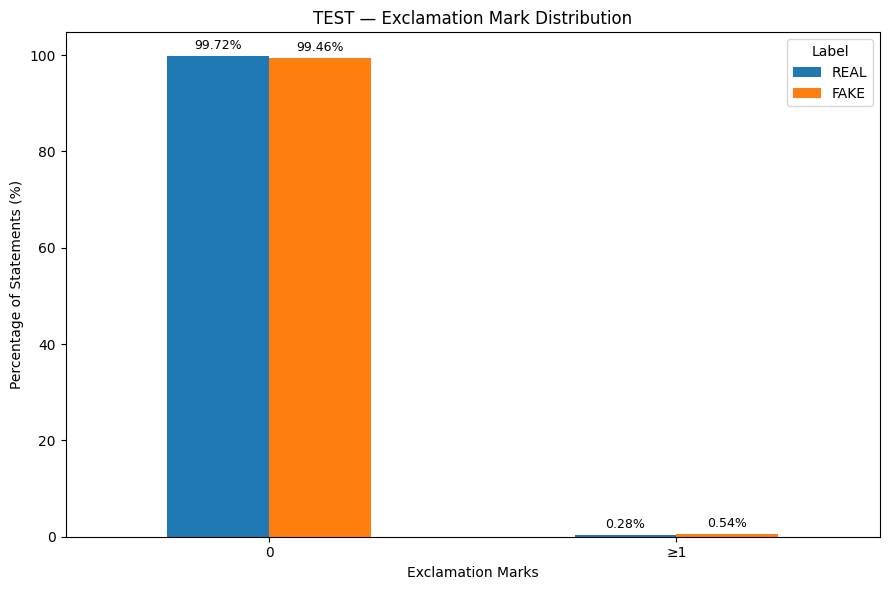

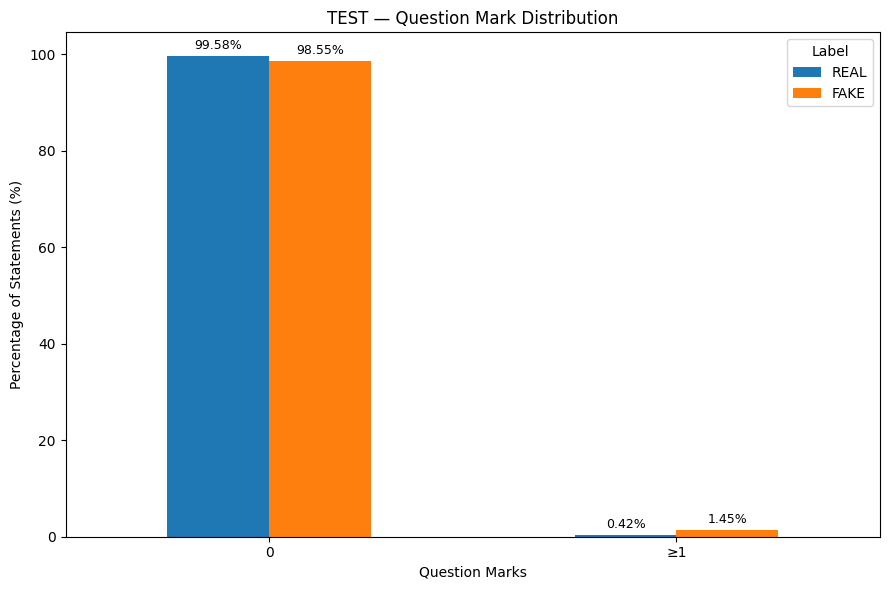

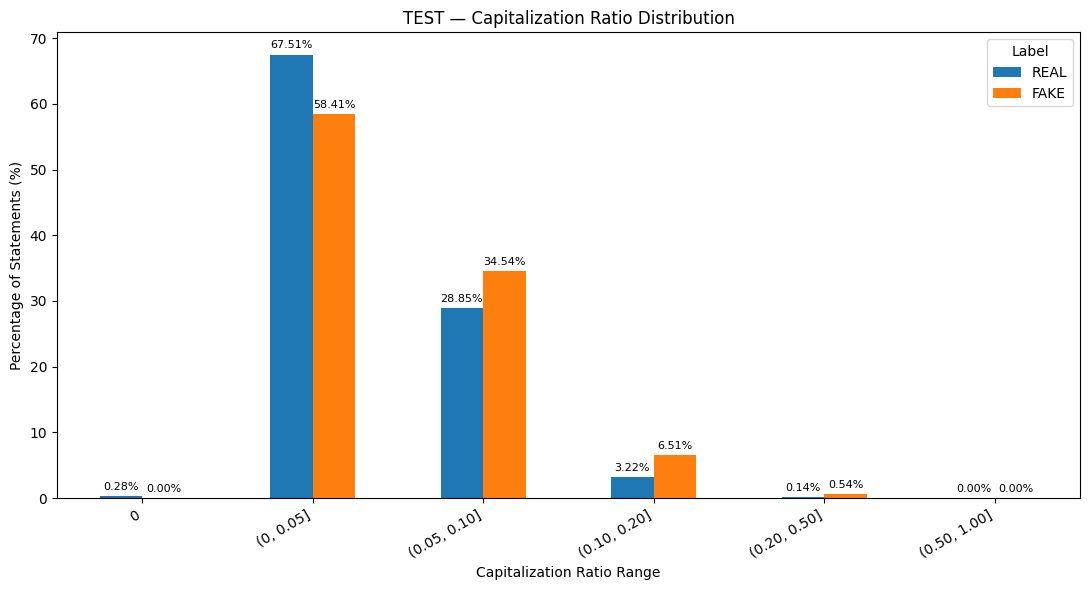

In [ ]:
# 8.5 ENGINEERED FEATURE VISUALIZATION
#
# Visualization strategy:
#
# 1. Exclamation count:
#       0 vs 1 or more
#
# 2. Question-mark count:
#       0 vs 1 or more
#
# 3. Caps ratio:
#       Meaningful capitalization ranges
#
# Percentages are calculated separately within REAL and FAKE.
# This makes the two labels directly comparable even though
# their sample sizes are different.
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd


for split_name, dataframe in dataset_splits.items():

    print("=" * 80)
    print(f"{split_name} — ENGINEERED FEATURE VISUALIZATION")
    print("=" * 80)


    # ========================================================
    # 1. EXCLAMATION MARKS
    # ========================================================
    #
    # Group:
    # 0 = No exclamation marks
    # >=1 = One or more exclamation marks
    # ========================================================

    exclamation_data = dataframe.copy()

    exclamation_data["exclamation_group"] = (
        exclamation_data["exclamation_count"]
        .apply(
            lambda x: "0" if x == 0 else "≥1"
        )
    )

    exclamation_counts = (
        exclamation_data
        .groupby(
            ["exclamation_group", "binary_label"]
        )
        .size()
        .unstack(fill_value=0)
    )

    # Ensure both labels exist
    if "REAL" not in exclamation_counts.columns:
        exclamation_counts["REAL"] = 0

    if "FAKE" not in exclamation_counts.columns:
        exclamation_counts["FAKE"] = 0

    exclamation_counts = exclamation_counts[
        ["REAL", "FAKE"]
    ]

    # Preserve order
    exclamation_counts = exclamation_counts.reindex(
        ["0", "≥1"]
    )

    # Convert to percentage within each label
    exclamation_percentage = (
        exclamation_counts
        .div(
            exclamation_counts.sum(axis=0),
            axis=1
        )
        * 100
    )

    ax = exclamation_percentage.plot(
        kind="bar",
        figsize=(9, 6)
    )

    ax.set_title(
        f"{split_name} — Exclamation Mark Distribution"
    )
    ax.set_xlabel(
        "Exclamation Marks"
    )
    ax.set_ylabel(
        "Percentage of Statements (%)"
    )

    ax.legend(
        title="Label"
    )

    plt.xticks(rotation=0)

    # Add percentage labels above bars
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f%%",
            padding=3,
            fontsize=9
        )

    plt.ylim(
        0,
        max(exclamation_percentage.max()) + 5
    )

    plt.tight_layout()
    plt.show()


    # ========================================================
    # 2. QUESTION MARKS
    # ========================================================
    #
    # Group:
    # 0 = No question marks
    # >=1 = One or more question marks
    # ========================================================

    question_data = dataframe.copy()

    question_data["question_group"] = (
        question_data["question_mark_count"]
        .apply(
            lambda x: "0" if x == 0 else "≥1"
        )
    )

    question_counts = (
        question_data
        .groupby(
            ["question_group", "binary_label"]
        )
        .size()
        .unstack(fill_value=0)
    )

    # Ensure both labels exist
    if "REAL" not in question_counts.columns:
        question_counts["REAL"] = 0

    if "FAKE" not in question_counts.columns:
        question_counts["FAKE"] = 0

    question_counts = question_counts[
        ["REAL", "FAKE"]
    ]

    # Preserve order
    question_counts = question_counts.reindex(
        ["0", "≥1"]
    )

    # Convert to percentage within each label
    question_percentage = (
        question_counts
        .div(
            question_counts.sum(axis=0),
            axis=1
        )
        * 100
    )

    ax = question_percentage.plot(
        kind="bar",
        figsize=(9, 6)
    )

    ax.set_title(
        f"{split_name} — Question Mark Distribution"
    )
    ax.set_xlabel(
        "Question Marks"
    )
    ax.set_ylabel(
        "Percentage of Statements (%)"
    )

    ax.legend(
        title="Label"
    )

    plt.xticks(rotation=0)

    # Add percentage labels
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f%%",
            padding=3,
            fontsize=9
        )

    plt.ylim(
        0,
        max(question_percentage.max()) + 5
    )

    plt.tight_layout()
    plt.show()


    # ========================================================
    # 3. CAPS RATIO
    # ========================================================

    caps_bins = [
        -0.001,
        0.00,
        0.05,
        0.10,
        0.20,
        0.50,
        1.00
    ]

    caps_labels = [
        "0",
        "(0, 0.05]",
        "(0.05, 0.10]",
        "(0.10, 0.20]",
        "(0.20, 0.50]",
        "(0.50, 1.00]"
    ]

    caps_ratio_range = pd.cut(
        dataframe["caps_ratio"],
        bins=caps_bins,
        labels=caps_labels,
        include_lowest=True
    )

    caps_counts = (
        dataframe
        .assign(
            caps_ratio_range=caps_ratio_range
        )
        .groupby(
            ["caps_ratio_range", "binary_label"],
            observed=False
        )
        .size()
        .unstack(fill_value=0)
    )

    # Ensure both labels exist
    if "REAL" not in caps_counts.columns:
        caps_counts["REAL"] = 0

    if "FAKE" not in caps_counts.columns:
        caps_counts["FAKE"] = 0

    caps_counts = caps_counts[
        ["REAL", "FAKE"]
    ]

    # Preserve range order
    caps_counts = caps_counts.reindex(
        caps_labels
    )

    # Convert to percentage within each label
    caps_percentage = (
        caps_counts
        .div(
            caps_counts.sum(axis=0),
            axis=1
        )
        * 100
    )

    ax = caps_percentage.plot(
        kind="bar",
        figsize=(11, 6)
    )

    ax.set_title(
        f"{split_name} — Capitalization Ratio Distribution"
    )
    ax.set_xlabel(
        "Capitalization Ratio Range"
    )
    ax.set_ylabel(
        "Percentage of Statements (%)"
    )

    ax.legend(
        title="Label"
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    # Add percentage labels
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f%%",
            padding=3,
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

## Conclusion — Engineered Feature Analysis

- The engineered features **`exclamation_count`**, **`question_mark_count`**, and **`caps_ratio`** were analyzed separately for REAL and FAKE statements.
- Exclamation marks and question marks were **rare across both classes**, with the majority of statements containing no such punctuation.
- The capitalization-ratio analysis showed that most statements had **low capitalization ratios**, while only a small proportion contained higher levels of capitalization.
- The percentage-based visualizations enabled a direct comparison of feature distributions between REAL and FAKE statements without being affected by the difference in class sizes.
- Similar distributions were examined across the **TRAIN, VALIDATION, and TEST** datasets.
- These engineered features provide additional numerical information that can be incorporated into the subsequent **text-feature modeling pipeline**.
- Their actual contribution to Fake News classification will be evaluated during the **model training and evaluation stages**.

## 9. SAVE PROCESSED DATA

In [ ]:
# 9.1 FINAL PROCESSED DATASET VERIFICATION


# This section:
# 1. Verifies the final dataset structure.
# 2. Checks that all required columns are present.
# 3. Checks for missing values in the required columns.
# 4. Displays the complete column list.
# ============================================================


# ------------------------------------------------------------
# Define required columns
# ------------------------------------------------------------

required_columns = [
    "statement",
    "cleaned_statement",
    "binary_label",
    "caps_ratio",
    "exclamation_count",
    "question_mark_count"
]


# ------------------------------------------------------------
# Verify each dataset split
# ------------------------------------------------------------

for split_name, dataframe in dataset_splits.items():

    print("=" * 80)
    print(f"{split_name} — FINAL PROCESSED DATASET CHECK")
    print("=" * 80)


    # --------------------------------------------------------
    # Dataset shape
    # --------------------------------------------------------

    # Display the number of rows and columns.
    print(f"Shape: {dataframe.shape}")


    # --------------------------------------------------------
    # Check required columns
    # --------------------------------------------------------

    # Identify any required columns that are missing.
    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]


    # Report whether all required columns are available.
    if len(missing_columns) == 0:

        print("Required columns: PASS")

    else:

        print("Required columns: FAIL")
        print("Missing columns:", missing_columns)


    # --------------------------------------------------------
    # Check missing values in required columns
    # --------------------------------------------------------

    # Count missing values in each required column.
    missing_values = (
        dataframe[required_columns]
        .isnull()
        .sum()
    )

    print("\nMissing values:")
    display(missing_values)


    # --------------------------------------------------------
    # Display column names
    # --------------------------------------------------------

    print("\nColumns:")
    print(dataframe.columns.tolist())

    print()

TRAIN — FINAL PROCESSED DATASET CHECK
Shape: (10240, 19)
Required columns: PASS

Missing values:


,0
statement,0
cleaned_statement,0
binary_label,0
caps_ratio,0
exclamation_count,0
question_mark_count,0



Columns:
['id', 'label', 'statement', 'subject', 'speaker', 'job', 'state', 'party', 'barely_true_ct', 'false_ct', 'half_true_ct', 'mostly_true_ct', 'pants_fire_ct', 'context', 'binary_label', 'cleaned_statement', 'caps_ratio', 'exclamation_count', 'question_mark_count']

VALIDATION — FINAL PROCESSED DATASET CHECK
Shape: (1284, 19)
Required columns: PASS

Missing values:


,0
statement,0
cleaned_statement,0
binary_label,0
caps_ratio,0
exclamation_count,0
question_mark_count,0



Columns:
['id', 'label', 'statement', 'subject', 'speaker', 'job', 'state', 'party', 'barely_true_ct', 'false_ct', 'half_true_ct', 'mostly_true_ct', 'pants_fire_ct', 'context', 'binary_label', 'cleaned_statement', 'caps_ratio', 'exclamation_count', 'question_mark_count']

TEST — FINAL PROCESSED DATASET CHECK
Shape: (1267, 19)
Required columns: PASS

Missing values:


,0
statement,0
cleaned_statement,0
binary_label,0
caps_ratio,0
exclamation_count,0
question_mark_count,0



Columns:
['id', 'label', 'statement', 'subject', 'speaker', 'job', 'state', 'party', 'barely_true_ct', 'false_ct', 'half_true_ct', 'mostly_true_ct', 'pants_fire_ct', 'context', 'binary_label', 'cleaned_statement', 'caps_ratio', 'exclamation_count', 'question_mark_count']



## 9.1 Final Processed Dataset Verification — Findings

The final processed datasets were verified before saving.

### Verification Results

- Train contains 10,240 records and 19 columns.
- Validation contains 1,284 records and 19 columns.
- Test contains 1,267 records and 19 columns.
- All required columns are present in each split.
- No missing values were introduced in the required processed columns.
- The original `statement` column is preserved.
- The `cleaned_statement` column is present.
- The `binary_label` target is present.
- All three engineered features are present:
  - `caps_ratio`
  - `exclamation_count`
  - `question_mark_count`
- Train, Validation, and Test remain separate.

The processed datasets passed the final structural verification and are ready
to be saved.

In [ ]:
# 9.2 SAVE PROCESSED DATA TO GOOGLE DRIVE


# This section:
# 1. Defines permanent paths for the processed datasets.
# 2. Saves Train, Validation, and Test separately.
# 3. Verifies that all three files exist.
# ============================================================


# ------------------------------------------------------------
# Import required library
# ------------------------------------------------------------

import os


# ------------------------------------------------------------
# Define permanent processed-data paths
# ------------------------------------------------------------

# Define the file path for the processed training dataset.
TRAIN_PROCESSED_PATH = os.path.join(
    str(PROCESSED_DATA_DIR),
    "train_processed.csv"
)

# Define the file path for the processed validation dataset.
VALIDATION_PROCESSED_PATH = os.path.join(
    str(PROCESSED_DATA_DIR),
    "validation_processed.csv"
)

# Define the file path for the processed test dataset.
TEST_PROCESSED_PATH = os.path.join(
    str(PROCESSED_DATA_DIR),
    "test_processed.csv"
)


# ------------------------------------------------------------
# Save processed datasets
# ------------------------------------------------------------

# Save the processed training dataset.
dataset_splits["TRAIN"].to_csv(
    TRAIN_PROCESSED_PATH,
    index=False
)

# Save the processed validation dataset.
dataset_splits["VALIDATION"].to_csv(
    VALIDATION_PROCESSED_PATH,
    index=False
)

# Save the processed test dataset.
dataset_splits["TEST"].to_csv(
    TEST_PROCESSED_PATH,
    index=False
)


# ------------------------------------------------------------
# Verify saved files
# ------------------------------------------------------------

print("=" * 70)
print("PROCESSED DATASETS SAVED")
print("=" * 70)

# Display the saved file paths.
print("Train      :", TRAIN_PROCESSED_PATH)
print("Validation :", VALIDATION_PROCESSED_PATH)
print("Test       :", TEST_PROCESSED_PATH)

print("\nFile verification:")

# Verify that the training file exists.
print(
    "Train exists      :",
    os.path.exists(TRAIN_PROCESSED_PATH)
)

# Verify that the validation file exists.
print(
    "Validation exists :",
    os.path.exists(VALIDATION_PROCESSED_PATH)
)

# Verify that the test file exists.
print(
    "Test exists       :",
    os.path.exists(TEST_PROCESSED_PATH)
)

PROCESSED DATASETS SAVED
Train      : /content/drive/MyDrive/Ai_project/P22/data/processed/train_processed.csv
Validation : /content/drive/MyDrive/Ai_project/P22/data/processed/validation_processed.csv
Test       : /content/drive/MyDrive/Ai_project/P22/data/processed/test_processed.csv

File verification:
Train exists      : True
Validation exists : True
Test exists       : True


In [ ]:
# 9.3 RELOAD AND VERIFY SAVED PROCESSED DATA


# This section:
# 1. Reloads the saved Train, Validation, and Test datasets.
# 2. Stores them in a new dictionary for verification.
# 3. Checks that all required processed columns are present.
# 4. Checks for missing values in the required columns.
# ============================================================


# ------------------------------------------------------------
# Reload the saved datasets
# ------------------------------------------------------------

# Reload the processed training dataset.
reloaded_train = pd.read_csv(
    TRAIN_PROCESSED_PATH
)

# Reload the processed validation dataset.
reloaded_validation = pd.read_csv(
    VALIDATION_PROCESSED_PATH
)

# Reload the processed test dataset.
reloaded_test = pd.read_csv(
    TEST_PROCESSED_PATH
)


# ------------------------------------------------------------
# Store reloaded datasets
# ------------------------------------------------------------

reloaded_dataset_splits = {
    "TRAIN": reloaded_train,
    "VALIDATION": reloaded_validation,
    "TEST": reloaded_test
}


# ------------------------------------------------------------
# Define required processed columns
# ------------------------------------------------------------

required_processed_columns = [
    "statement",
    "cleaned_statement",
    "binary_label",
    "caps_ratio",
    "exclamation_count",
    "question_mark_count"
]


# ------------------------------------------------------------
# Verify each saved dataset
# ------------------------------------------------------------

for split_name, dataframe in reloaded_dataset_splits.items():

    print("=" * 80)
    print(f"{split_name} — RELOADED DATASET VERIFICATION")
    print("=" * 80)


    # --------------------------------------------------------
    # Dataset shape
    # --------------------------------------------------------

    print(f"Shape: {dataframe.shape}")


    # --------------------------------------------------------
    # Check required columns
    # --------------------------------------------------------

    # Identify any required columns that are missing.
    missing_columns = [
        column
        for column in required_processed_columns
        if column not in dataframe.columns
    ]


    if len(missing_columns) == 0:

        print("Required columns: PASS")

    else:

        print("Required columns: FAIL")
        print("Missing columns:", missing_columns)


    # --------------------------------------------------------
    # Check missing values
    # --------------------------------------------------------

    # Count missing values in the required processed columns.
    missing_values = (
        dataframe[required_processed_columns]
        .isnull()
        .sum()
    )

    print("\nMissing values:")
    display(missing_values)

    print()

TRAIN — RELOADED DATASET VERIFICATION
Shape: (10240, 19)
Required columns: PASS

Missing values:


,0
statement,0
cleaned_statement,0
binary_label,0
caps_ratio,0
exclamation_count,0
question_mark_count,0



VALIDATION — RELOADED DATASET VERIFICATION
Shape: (1284, 19)
Required columns: PASS

Missing values:


,0
statement,0
cleaned_statement,0
binary_label,0
caps_ratio,0
exclamation_count,0
question_mark_count,0



TEST — RELOADED DATASET VERIFICATION
Shape: (1267, 19)
Required columns: PASS

Missing values:


,0
statement,0
cleaned_statement,0
binary_label,0
caps_ratio,0
exclamation_count,0
question_mark_count,0


In [ ]:
# reloaded_train.head()

## 10. MODEL PREPARATION — TF-IDF
### 10.1 Prepare Text and Targets

In [ ]:
# 10.1.1 LOAD PROCESSED DATA FOR TF-IDF


# This section:
# 1. Loads the saved processed Train, Validation, and Test datasets.
# 2. Creates TF-IDF-specific DataFrames.
# 3. Verifies their shapes before model-specific preprocessing.
# ============================================================


# ------------------------------------------------------------
# Load processed datasets
# ------------------------------------------------------------

# Load the processed training dataset.
tfidf_train_df = pd.read_csv(
    TRAIN_PROCESSED_PATH
)

# Load the processed validation dataset.
tfidf_validation_df = pd.read_csv(
    VALIDATION_PROCESSED_PATH
)

# Load the processed test dataset.
tfidf_test_df = pd.read_csv(
    TEST_PROCESSED_PATH
)


# ------------------------------------------------------------
# Display dataset shapes
# ------------------------------------------------------------

print("TRAIN:", tfidf_train_df.shape)
print("VALIDATION:", tfidf_validation_df.shape)
print("TEST:", tfidf_test_df.shape)

TRAIN: (10240, 19)
VALIDATION: (1284, 19)
TEST: (1267, 19)


In [ ]:
# 10.1.2 SEPARATE TF-IDF TEXT AND TARGET


# This section:
# 1. Separates the cleaned text that will be used as model input.
# 2. Separates the binary REAL/FAKE target.
# 3. Keeps Train, Validation, and Test completely separate.
# ============================================================


# ------------------------------------------------------------
# Separate text input
# ------------------------------------------------------------

# Use the cleaned statement as the text input for TF-IDF.
tfidf_train_text = tfidf_train_df["cleaned_statement"]

tfidf_validation_text = (tfidf_validation_df["cleaned_statement"])

tfidf_test_text = (tfidf_test_df["cleaned_statement"])


# ------------------------------------------------------------
# Separate binary target
# ------------------------------------------------------------

# Use the binary label as the classification target.
tfidf_train_target = tfidf_train_df["binary_label"]

tfidf_validation_target = (tfidf_validation_df["binary_label"])

tfidf_test_target = (tfidf_test_df["binary_label"])


# ------------------------------------------------------------
# Verify dimensions
# ------------------------------------------------------------

# Display the number of text samples in each split.
print("Train text:", tfidf_train_text.shape)
print("Validation text:", tfidf_validation_text.shape)
print("Test text:", tfidf_test_text.shape)

print()

# Display the number of target values in each split.
print("Train target:", tfidf_train_target.shape)
print("Validation target:", tfidf_validation_target.shape)
print("Test target:", tfidf_test_target.shape)

Train text: (10240,)
Validation text: (1284,)
Test text: (1267,)

Train target: (10240,)
Validation target: (1284,)
Test target: (1267,)


In [ ]:
# 10.2 TF-IDF VECTORIZATION


# This section:
# 1. Creates the TF-IDF vectorizer.
# 2. Fits TF-IDF only on the training text.
# 3. Transforms Validation and Test using the same vocabulary.
# 4. Converts text into numerical TF-IDF features.
# ============================================================


# Import TF-IDF vectorizer.
from sklearn.feature_extraction.text import TfidfVectorizer


# ------------------------------------------------------------
# Create TF-IDF vectorizer
# ------------------------------------------------------------

# Create the TF-IDF vectorizer with unigram and bigram features.
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000, # Maximum number of TF-IDF features to keep.
    ngram_range=(1, 2), # Use unigrams and bigrams.
    min_df=2, # Ignore terms appearing in fewer than 2 documents.
    max_df=0.95 # Ignore terms appearing in more than 95% of documents.
)


# ------------------------------------------------------------
# Fit ONLY on training data
# ------------------------------------------------------------

# Learn the vocabulary and IDF values from training text
# and convert the training text into numerical features.
tfidf_train_features = tfidf_vectorizer.fit_transform(
    tfidf_train_text
)


# ------------------------------------------------------------
# Transform Validation and Test
# ------------------------------------------------------------

# Convert validation text using the vocabulary learned
# from the training data.
tfidf_validation_features = tfidf_vectorizer.transform(
    tfidf_validation_text
)

# Convert test text using the same training vocabulary.
tfidf_test_features = tfidf_vectorizer.transform(
    tfidf_test_text
)


# ------------------------------------------------------------
# Display resulting shapes
# ------------------------------------------------------------

print("TF-IDF feature shapes:")

print("Train      :", tfidf_train_features.shape)

print("Validation :", tfidf_validation_features.shape)

print("Test       :", tfidf_test_features.shape)

TF-IDF feature shapes:
Train      : (10240, 10000)
Validation : (1284, 10000)
Test       : (1267, 10000)


In [ ]:
# 10.3 TF-IDF VOCABULARY INSPECTION


# This section:
# 1. Extracts the vocabulary learned by the TF-IDF vectorizer.
# 2. Displays the total number of learned features.
# 3. Displays the first 50 features for verification.
# ============================================================


# Get the feature names learned by the fitted TF-IDF vectorizer.
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()


# ------------------------------------------------------------
# Display vocabulary information
# ------------------------------------------------------------

print("=" * 70)
print("TF-IDF VOCABULARY")
print("=" * 70)


# Display the total number of TF-IDF features.
print("Total TF-IDF features:", len(tfidf_feature_names))


# Display the first 50 learned features.
print("\nFirst 50 learned features:")

for feature in tfidf_feature_names[:50]:

    print(feature)

TF-IDF VOCABULARY
Total TF-IDF features: 10000

First 50 learned features:
000
000 000
000 americans
000 and
000 children
000 fewer
000 for
000 from
000 in
000 jobs
000 more
000 new
000 of
000 on
000 or
000 oregonians
000 people
000 per
000 students
000 tax
000 teachers
000 to
000 troops
000 year
10
10 000
10 10
10 billion
10 days
10 in
10 million
10 of
10 percent
10 year
10 years
100
100 000
100 and
100 billion
100 days
100 million
100 percent
100 years
10th
11
11 percent
110
115
12
12 000


## 10.3 TF-IDF Vocabulary — Findings

The fitted TF-IDF vectorizer learned **10,000 features**, which is the maximum
specified by `max_features=10000`.

The vocabulary contains both:

- **Unigrams** — individual words such as `10`, `100`, `education`
- **Bigrams** — two-word combinations such as `000 americans`, `10 billion`,
  and `100 years`

This confirms that `ngram_range=(1, 2)` is working as expected.

Numeric tokens such as `10`, `100`, and `000` are present because the text
cleaning step allows numbers to be retained.

The TF-IDF vocabulary was learned using the **training dataset only** and is
used unchanged for Validation and Test data to avoid data leakage.

In [ ]:
# 10.4 UNIGRAM VS BIGRAM COUNT


# This section:
# 1. Counts the number of unigram features.
# 2. Counts the number of bigram features.
# 3. Verifies that both together equal the total TF-IDF features.
# ============================================================


# Count features containing no space.
# These are unigram features containing a single token.
tfidf_unigram_count = sum(
    1
    for feature in tfidf_feature_names
    if " " not in feature
)


# Count features containing a space.
# These are bigram features containing two tokens.
tfidf_bigram_count = sum(
    1
    for feature in tfidf_feature_names
    if " " in feature
)


# ------------------------------------------------------------
# Display feature distribution
# ------------------------------------------------------------

print("=" * 70)
print("TF-IDF FEATURE TYPE DISTRIBUTION")
print("=" * 70)


# Display the number of unigram features.
print("Unigrams :", tfidf_unigram_count)

# Display the number of bigram features.
print("Bigrams  :", tfidf_bigram_count)

# Display the total number of TF-IDF features.
print("Total    :", len(tfidf_feature_names))

TF-IDF FEATURE TYPE DISTRIBUTION
Unigrams : 3901
Bigrams  : 6099
Total    : 10000


## 10.3 TF-IDF Vocabulary Inspection — Findings

The TF-IDF vectorizer successfully learned a vocabulary of 10,000 features
from the Training dataset.

### Feature Composition

- Unigrams: 3,906
- Bigrams: 6,094
- Total features: 10,000

The vocabulary contains both individual words and two-word phrases, allowing
the models to capture both isolated terms and short contextual patterns.

Several numerical terms and numerical phrases are also present. These are
retained because numerical claims are common in political fact-checking
statements and may provide useful predictive information.

The TF-IDF vocabulary was learned only from the Training dataset, while
Validation and Test were transformed using the same fitted vectorizer.

## 10.4 Combine TF-IDF + Engineered Features

                    TRAIN
                      │
          ┌───────────┴───────────┐
          ↓                       ↓
   Cleaned Statement        Engineered Features
          │                       │
          ↓                       ↓
       TF-IDF              ┌───────────────┐
          │                │ caps_ratio    │
          │                │ ! count       │
          │                │ ? count       │
          │                └───────────────┘
          │                       │
          └───────────┬───────────┘
                      ↓
              Combined Features
                      │
                      ↓
                 ML Classifier

In [ ]:
# 10.4 COMBINE TF-IDF + ENGINEERED FEATURES


# This section:
# 1. Extracts the three engineered features.
# 2. Converts them into sparse matrices.
# 3. Combines them with the TF-IDF features.
# 4. Creates the final input for the basic models.
# ============================================================


# Import tools for working with sparse matrices.
from scipy.sparse import csr_matrix, hstack


# ------------------------------------------------------------
# Extract engineered features
# ------------------------------------------------------------

# Select the three engineered features from Train
# and convert them into a sparse matrix.
tfidf_train_engineered = csr_matrix(
    tfidf_train_df[
        [
            "caps_ratio",
            "exclamation_count",
            "question_mark_count"
        ]
    ].values
)


# Select the three engineered features from Validation.
tfidf_validation_engineered = csr_matrix(
    tfidf_validation_df[
        [
            "caps_ratio",
            "exclamation_count",
            "question_mark_count"
        ]
    ].values
)


# Select the three engineered features from Test.
tfidf_test_engineered = csr_matrix(
    tfidf_test_df[
        [
            "caps_ratio",
            "exclamation_count",
            "question_mark_count"
        ]
    ].values
)


# ------------------------------------------------------------
# Combine TF-IDF and engineered features
# ------------------------------------------------------------

# Add the three engineered features to the TF-IDF
# features for the training data.
tfidf_train_combined = hstack(
    [
        tfidf_train_features,
        tfidf_train_engineered
    ]
).tocsr()


# Add the same three features to Validation.
tfidf_validation_combined = hstack(
    [
        tfidf_validation_features,
        tfidf_validation_engineered
    ]
).tocsr()


# Add the same three features to Test.
tfidf_test_combined = hstack(
    [
        tfidf_test_features,
        tfidf_test_engineered
    ]
).tocsr()


# ------------------------------------------------------------
# Display final feature shapes
# ------------------------------------------------------------

print("=" * 70)
print("COMBINED FEATURE SHAPES")
print("=" * 70)

print("Train      :", tfidf_train_combined.shape)
print("Validation :", tfidf_validation_combined.shape)
print("Test       :", tfidf_test_combined.shape)

COMBINED FEATURE SHAPES
Train      : (10240, 10003)
Validation : (1284, 10003)
Test       : (1267, 10003)


## 9.4 TF-IDF + Engineered Features — Findings

The TF-IDF representation was successfully combined with the three engineered
numerical features.

### Final Feature Dimensions

- Train: 10,240 samples × 10,003 features
- Validation: 1,284 samples × 10,003 features
- Test: 1,267 samples × 10,003 features

The final feature representation consists of:

- 10,000 TF-IDF features
  - 3,906 unigrams
  - 6,094 bigrams
- 3 engineered numerical features:
  - `caps_ratio`
  - `exclamation_count`
  - `question_mark_count`

The same feature structure is maintained across Train, Validation, and Test.

## 10.5 Prepare Targets for Modeling

In [ ]:
# 10.5 PREPARE TARGET ARRAYS


# This section:
# 1. Converts the Train, Validation, and Test targets
#    from pandas Series into NumPy arrays.
# 2. Keeps the REAL/FAKE target values unchanged.
# ============================================================


# Convert the training target to a NumPy array.
tfidf_train_y = tfidf_train_target.to_numpy()

# Convert the validation target to a NumPy array.
tfidf_validation_y = tfidf_validation_target.to_numpy()

# Convert the test target to a NumPy array.
tfidf_test_y = tfidf_test_target.to_numpy()


# ------------------------------------------------------------
# Display target shapes
# ------------------------------------------------------------

print("=" * 70)
print("TARGET SHAPES")
print("=" * 70)

print("Train      :", tfidf_train_y.shape)
print("Validation :", tfidf_validation_y.shape)
print("Test       :", tfidf_test_y.shape)

TARGET SHAPES
Train      : (10240,)
Validation : (1284,)
Test       : (1267,)


# 11. Model Building

In [ ]:
# 11.1 CHECK TARGET LABELS


# This section:
# 1. Checks the unique target labels in each dataset split.
# 2. Confirms that both REAL and FAKE classes are present.
# ============================================================


# Display the unique labels in the training target.
print("Train labels:", np.unique(tfidf_train_y))

# Display the unique labels in the validation target.
print("Validation labels:", np.unique(tfidf_validation_y))

# Display the unique labels in the test target.
print("Test labels:", np.unique(tfidf_test_y))

Train labels: ['FAKE' 'REAL']
Validation labels: ['FAKE' 'REAL']
Test labels: ['FAKE' 'REAL']


In [ ]:
# 11.2 MODEL BUILDING — IMPORTS AND CONFIGURATION


# This section:
# 1. Imports the models required for the basic-model stage.
# 2. Imports GridSearchCV for hyperparameter tuning.
# 3. Imports evaluation metrics.
# 4. Defines reproducibility and cross-validation settings.
# ============================================================


# ------------------------------------------------------------
# General libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Model selection and models
# ------------------------------------------------------------

# Used for hyperparameter tuning with cross-validation.
from sklearn.model_selection import GridSearchCV

# Logistic Regression classifier.
from sklearn.linear_model import LogisticRegression

# Linear Support Vector Machine classifier.
from sklearn.svm import LinearSVC


# ------------------------------------------------------------
# Evaluation metrics
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

# Set a fixed random state for reproducible model results.
MODEL_RANDOM_STATE = 42


# ------------------------------------------------------------
# Cross-validation configuration
# ------------------------------------------------------------

# Use 5-fold cross-validation for model selection.
MODEL_CV_FOLDS = 5


# ------------------------------------------------------------
# Primary model-selection metric
# ------------------------------------------------------------

# Use macro F1-score to give equal importance to both classes.
MODEL_SELECTION_SCORING = "f1_macro"


# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 80)
print("MODEL BUILDING CONFIGURATION")
print("=" * 80)

print("Cross-validation folds :", MODEL_CV_FOLDS)
print("Primary scoring metric :", MODEL_SELECTION_SCORING)
print("Random state           :", MODEL_RANDOM_STATE)

MODEL BUILDING CONFIGURATION
Cross-validation folds : 5
Primary scoring metric : f1_macro
Random state           : 42


## Why F1-Macro Is Used for Model Selection

The dataset has some class imbalance between **REAL** and **FAKE**.
Therefore, accuracy alone may not fully represent the model's performance
on both classes.

### Precision

Precision measures how many statements predicted as a particular class
are actually that class.

**Precision = TP / (TP + FP)**

- **TP (True Positive):** Correctly predicted positive class.
- **FP (False Positive):** Incorrectly predicted as positive.

### Recall

Recall measures how many of the actual statements belonging to a class
are correctly identified.

**Recall = TP / (TP + FN)**

- **TP (True Positive):** Correctly predicted positive class.
- **FN (False Negative):** Actual positive class predicted as negative.

### F1-Score

F1-score combines Precision and Recall using their harmonic mean.

**F1 = 2 × (Precision × Recall) / (Precision + Recall)**

### Macro F1

F1 is calculated separately for **REAL** and **FAKE**, and then their
scores are averaged equally.

**F1-macro = (F1-REAL + F1-FAKE) / 2**

### Why We Use F1-Macro

For this project, **F1-macro is used as the primary model-selection
metric** because it considers both Precision and Recall and gives equal
importance to the REAL and FAKE classes.

```python
MODEL_SELECTION_SCORING = "f1_macro"

In [ ]:
# 11.3 MODELS AND HYPERPARAMETER SEARCH SPACES


# This section:
# 1. Defines the Logistic Regression model.
# 2. Defines the Linear SVM model.
# 3. Defines the hyperparameter values that will be tested.
# 4. Uses GridSearchCV later to find the best combination.
# ============================================================


# ------------------------------------------------------------
# Logistic Regression
# ------------------------------------------------------------

# Create the Logistic Regression model.
logreg_model = LogisticRegression(

    # Maximum number of iterations allowed for model convergence.
    max_iter=2000,

    # Fixed random state for reproducible results.
    random_state=MODEL_RANDOM_STATE
)


# Define the hyperparameter search space.
logreg_param_grid = {

    # C controls the strength of regularization.

    # Regularization is a technique used to prevent a machine-learning model
    # from becoming too complex and overfitting the training data.

    # Regularization tells the model:
    # "Don't rely too heavily on individual features.
    # Keep the model simpler unless the feature provides enough evidence."

    # Smaller C  -> stronger regularization.
    # Larger C   -> weaker regularization.

    # 0.01 = very strong regularization
    # 0.1  = strong regularization
    # 1.0  = moderate/default-level regularization
    # 10.0 = weaker regularization

    # 0.001 Very strong Can make the model too constrained

    # GridSearchCV will test all four values.

    "C": [0.01, 0.1, 1.0, 10.0],

    # class_weight controls the relative importance
    # given to different classes during training.

    # None:
    # Treats all classes equally without applying
    # additional class weighting.

    # "balanced":
    # Automatically gives greater weight to the
     # minority class and lower weight to the majority
    # class based on their frequencies.


    "class_weight": [None, "balanced"]
}


# ------------------------------------------------------------
# Linear SVM
# ------------------------------------------------------------

# Create the Linear SVM model.
linear_svm_model = LinearSVC(

    # Maximum number of iterations allowed for convergence.
    max_iter=5000,

    # Fixed random state for reproducibility.
    random_state=MODEL_RANDOM_STATE
)


# Define the hyperparameter search space.
linear_svm_param_grid = {

    "C": [0.01, 0.1, 1.0, 10.0],

    # Compare:
    # None     -> no additional class weighting.
    # balanced -> automatically compensate for class imbalance.
    "class_weight": [None, "balanced"]
}

# For each model:

# 4 values of C × 2 values of class_weight = 8 combinations

# With 5-fold cross-validation, GridSearchCV evaluates each combination across 5 folds.

# So each model involves:

# 8 × 5 = 40 model fits

# And because we have two models:

# 40 + 40 = 80 total fits.

# ------------------------------------------------------------
# Display search spaces
# ------------------------------------------------------------

print("=" * 80)
print("MODEL SEARCH SPACES")
print("=" * 80)


print("\nLogistic Regression:")
print(logreg_param_grid)


print("\nLinear SVM:")
print(linear_svm_param_grid)

MODEL SEARCH SPACES

Logistic Regression:
{'C': [0.01, 0.1, 1.0, 10.0], 'class_weight': [None, 'balanced']}

Linear SVM:
{'C': [0.01, 0.1, 1.0, 10.0], 'class_weight': [None, 'balanced']}


In [ ]:
# 11.4 REUSABLE HYPERPARAMETER TUNING FUNCTION


# This function:
# 1. Receives a model and its hyperparameter search space.
# 2. Performs 5-fold cross-validation on the Training dataset.
# 3. Tests all specified hyperparameter combinations.
# 4. Uses macro F1 to select the best combination.
# 5. Refits the best model using the complete Training dataset.
# 6. Returns the fitted GridSearchCV object.
# ============================================================


def tune_classification_model(
    model,
    parameter_grid,
    training_features,
    training_targets,
    experiment_name
):
    """
    Perform cross-validated hyperparameter tuning for a
    classification model using the Training dataset only.
    """

    # --------------------------------------------------------
    # Display tuning information
    # --------------------------------------------------------

    print("=" * 80)
    print(f"HYPERPARAMETER TUNING — {experiment_name}")
    print("=" * 80)


    # --------------------------------------------------------
    # Create GridSearchCV
    # --------------------------------------------------------

    grid_search = GridSearchCV(

        # Model that will be tuned.
        estimator=model,

        # Hyperparameter combinations to test.
        param_grid=parameter_grid,

        # Macro F1 is used to select the best model.
        scoring=MODEL_SELECTION_SCORING,

        # Use the configured number of cross-validation folds.
        cv=MODEL_CV_FOLDS,

        # Use all available CPU cores.
        n_jobs=-1,

        # Automatically refit the best model on the complete
        # training dataset after cross-validation.
        refit=True,

        # Display progress during the search.
        verbose=1
    )


    # --------------------------------------------------------
    # Perform hyperparameter tuning
    # --------------------------------------------------------

    # IMPORTANT:
    # Only the Training features and Training targets are used.
    # Validation and Test data are not used during tuning.
    grid_search.fit(
        training_features,
        training_targets
    )


    # --------------------------------------------------------
    # Display best results
    # --------------------------------------------------------

    # Display the hyperparameter combination that achieved
    # the highest cross-validated macro F1-score.
    print("\nBest parameters:")
    print(grid_search.best_params_)


    # Display the best mean cross-validation score.
    print(
        f"\nBest cross-validation "
        f"{MODEL_SELECTION_SCORING}: "
        f"{grid_search.best_score_:.4f}"
    )


    # Display the fitted best model.
    print("\nBest model:")
    print(grid_search.best_estimator_)


    # Return the complete GridSearchCV object.
    return grid_search

In [ ]:
# 11.5 EXPERIMENT 1
# LOGISTIC REGRESSION + TF-IDF ONLY


# This experiment:
# 1. Uses Logistic Regression as the classifier.
# 2. Uses only TF-IDF features as model input.
# 3. Tests the Logistic Regression hyperparameter combinations.
# 4. Uses 5-fold cross-validation on the Training dataset.
# 5. Selects the best combination using macro F1.
# ============================================================


# Run hyperparameter tuning for Logistic Regression.
tfidf_logreg_grid_search = tune_classification_model(

    # Logistic Regression model defined earlier.
    model=logreg_model,

    # Logistic Regression hyperparameter search space.
    parameter_grid=logreg_param_grid,

    # IMPORTANT:
    # This experiment uses TF-IDF features ONLY.
    # The 3 engineered features are not included here.
    training_features=tfidf_train_features,

    # Training target labels.
    training_targets=tfidf_train_y,

    # Name used to identify this experiment in the output.
    experiment_name="LOGISTIC REGRESSION + TF-IDF ONLY"
)


HYPERPARAMETER TUNING — LOGISTIC REGRESSION + TF-IDF ONLY
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters:
{'C': 1.0, 'class_weight': 'balanced'}

Best cross-validation f1_macro: 0.6104

Best model:
LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)


LOGISTIC REGRESSION + TF-IDF ONLY — VALIDATION PERFORMANCE
Accuracy       : 0.6145
Precision FAKE : 0.5965
Recall FAKE    : 0.6071
F1 FAKE        : 0.6018
F1 Macro       : 0.6141

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.60      0.61      0.60       616
        REAL       0.63      0.62      0.63       668

    accuracy                           0.61      1284
   macro avg       0.61      0.61      0.61      1284
weighted avg       0.61      0.61      0.61      1284



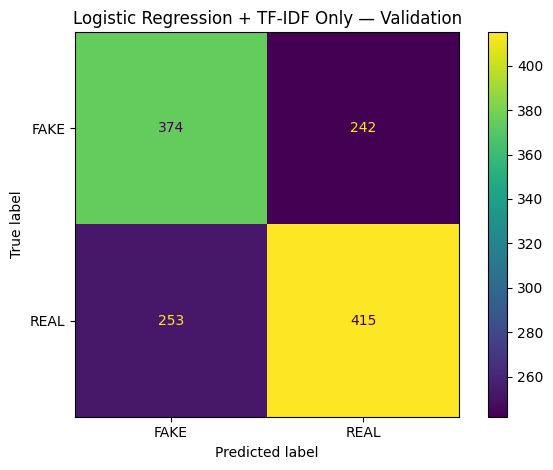

In [ ]:
# 11.6 LOGISTIC REGRESSION + TF-IDF ONLY
# VALIDATION EVALUATION


# This section:
# 1. Uses the best Logistic Regression model selected by GridSearchCV.
# 2. Generates predictions on the Validation dataset.
# 3. Calculates Accuracy, Precision, Recall, F1, and Macro F1.
# 4. Displays a complete classification report.
# ============================================================


# ------------------------------------------------------------
# Generate Validation predictions
# ------------------------------------------------------------

# Use the best model selected during hyperparameter tuning.
# The Validation features contain TF-IDF features only.
tfidf_logreg_validation_predictions = (
    tfidf_logreg_grid_search.best_estimator_.predict(
        tfidf_validation_features
    )
)


# ------------------------------------------------------------
# Calculate Validation metrics
# ------------------------------------------------------------

# Calculate overall classification accuracy.
tfidf_logreg_validation_accuracy = accuracy_score(
    tfidf_validation_y,
    tfidf_logreg_validation_predictions
)


# Calculate Precision for the FAKE class.
#
# Of all statements predicted as FAKE,
# how many were actually FAKE?
tfidf_logreg_validation_precision = precision_score(
    tfidf_validation_y,
    tfidf_logreg_validation_predictions,
    pos_label="FAKE"
)


# Calculate Recall for the FAKE class.
#
# Of all actually FAKE statements,
# how many were correctly identified as FAKE?
tfidf_logreg_validation_recall = recall_score(
    tfidf_validation_y,
    tfidf_logreg_validation_predictions,
    pos_label="FAKE"
)


# Calculate F1-score for the FAKE class.
tfidf_logreg_validation_f1 = f1_score(
    tfidf_validation_y,
    tfidf_logreg_validation_predictions,
    pos_label="FAKE"
)


# Calculate Macro F1.
#
# This calculates F1 separately for REAL and FAKE
# and then gives both classes equal importance.
tfidf_logreg_validation_f1_macro = f1_score(
    tfidf_validation_y,
    tfidf_logreg_validation_predictions,
    average="macro"
)


# ------------------------------------------------------------
# Display Validation results
# ------------------------------------------------------------

print("=" * 80)
print("LOGISTIC REGRESSION + TF-IDF ONLY — VALIDATION PERFORMANCE")
print("=" * 80)

print(
    f"Accuracy       : "
    f"{tfidf_logreg_validation_accuracy:.4f}"
)

print(
    f"Precision FAKE : "
    f"{tfidf_logreg_validation_precision:.4f}"
)

print(
    f"Recall FAKE    : "
    f"{tfidf_logreg_validation_recall:.4f}"
)

print(
    f"F1 FAKE        : "
    f"{tfidf_logreg_validation_f1:.4f}"
)

print(
    f"F1 Macro       : "
    f"{tfidf_logreg_validation_f1_macro:.4f}"
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)


# Display Precision, Recall, F1-score, and support
# separately for REAL and FAKE.
print(
    classification_report(
        tfidf_validation_y,
        tfidf_logreg_validation_predictions
    )
)

# ============================================================
# DISPLAY CONFUSION MATRIX
# ============================================================

tfidf_logreg_confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        tfidf_validation_y,
        tfidf_logreg_validation_predictions,
        labels=["FAKE", "REAL"]
    ),
    display_labels=[
        "FAKE",
        "REAL"
    ]
)


tfidf_logreg_confusion_display.plot()

plt.title(
    "Logistic Regression + TF-IDF Only — Validation"
)

plt.tight_layout()

plt.show()

In [ ]:
# 11.7 EXPERIMENT 2
# LOGISTIC REGRESSION + TF-IDF + ENGINEERED FEATURES

# This experiment:
# 1. Uses Logistic Regression as the classifier.
# 2. Uses 10,000 TF-IDF features.
# 3. Adds 3 engineered features:
#       - caps_ratio
#       - exclamation_count
#       - question_mark_count
# 4. Uses the same hyperparameter search space as Experiment 1.
# 5. Uses 5-fold cross-validation on the Training dataset.
# 6. Uses Macro F1 for model selection.
# 7. Keeps Validation and Test data separate from hyperparameter tuning.
# ============================================================

tfidf_engineered_logreg_grid_search = tune_classification_model(
    model=logreg_model,
    parameter_grid=logreg_param_grid,
    training_features=tfidf_train_combined,
    training_targets=tfidf_train_y,
    experiment_name="LOGISTIC REGRESSION + TF-IDF + ENGINEERED FEATURES"
)

HYPERPARAMETER TUNING — LOGISTIC REGRESSION + TF-IDF + ENGINEERED FEATURES
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters:
{'C': 0.1, 'class_weight': 'balanced'}

Best cross-validation f1_macro: 0.6101

Best model:
LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000,
                   random_state=42)


LOGISTIC REGRESSION + TF-IDF + ENGINEERED FEATURES
VALIDATION PERFORMANCE
Accuracy       : 0.6262
Precision FAKE : 0.6040
Recall FAKE    : 0.6412
F1 FAKE        : 0.6220
F1 Macro       : 0.6261

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.60      0.64      0.62       616
        REAL       0.65      0.61      0.63       668

    accuracy                           0.63      1284
   macro avg       0.63      0.63      0.63      1284
weighted avg       0.63      0.63      0.63      1284



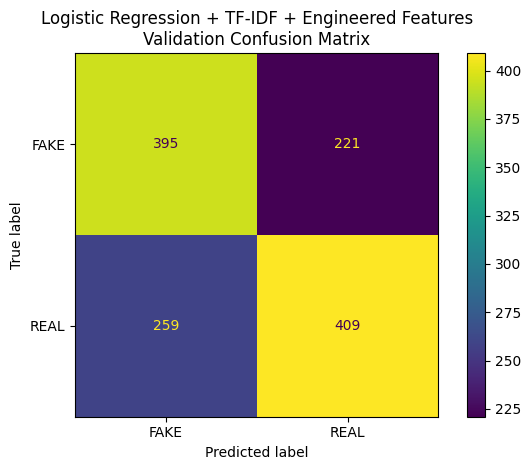

In [ ]:
# 11.8 LOGISTIC REGRESSION + TF-IDF + ENGINEERED FEATURES
# VALIDATION EVALUATION


# This section:
# 1. Uses the best Logistic Regression model selected by GridSearchCV.
# 2. Generates predictions on the Validation dataset.
# 3. Calculates Accuracy, Precision, Recall, F1, and Macro F1.
# 4. Displays the classification report.
# 5. Displays the Validation confusion matrix.
# ============================================================


# ------------------------------------------------------------
# Generate Validation predictions
# ------------------------------------------------------------

tfidf_engineered_logreg_validation_predictions = (
    tfidf_engineered_logreg_grid_search.best_estimator_.predict(
        tfidf_validation_combined
    )
)


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

# Overall classification accuracy.
tfidf_engineered_logreg_validation_accuracy = accuracy_score(
    tfidf_validation_y,
    tfidf_engineered_logreg_validation_predictions
)


# Precision for the FAKE class.
tfidf_engineered_logreg_validation_precision = precision_score(
    tfidf_validation_y,
    tfidf_engineered_logreg_validation_predictions,
    pos_label="FAKE"
)


# Recall for the FAKE class.
tfidf_engineered_logreg_validation_recall = recall_score(
    tfidf_validation_y,
    tfidf_engineered_logreg_validation_predictions,
    pos_label="FAKE"
)


# F1-score for the FAKE class.
tfidf_engineered_logreg_validation_f1 = f1_score(
    tfidf_validation_y,
    tfidf_engineered_logreg_validation_predictions,
    pos_label="FAKE"
)


# Macro F1 gives equal importance to REAL and FAKE.
tfidf_engineered_logreg_validation_f1_macro = f1_score(
    tfidf_validation_y,
    tfidf_engineered_logreg_validation_predictions,
    average="macro"
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 80)
print("LOGISTIC REGRESSION + TF-IDF + ENGINEERED FEATURES")
print("VALIDATION PERFORMANCE")
print("=" * 80)

print(
    f"Accuracy       : "
    f"{tfidf_engineered_logreg_validation_accuracy:.4f}"
)

print(
    f"Precision FAKE : "
    f"{tfidf_engineered_logreg_validation_precision:.4f}"
)

print(
    f"Recall FAKE    : "
    f"{tfidf_engineered_logreg_validation_recall:.4f}"
)

print(
    f"F1 FAKE        : "
    f"{tfidf_engineered_logreg_validation_f1:.4f}"
)

print(
    f"F1 Macro       : "
    f"{tfidf_engineered_logreg_validation_f1_macro:.4f}"
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        tfidf_validation_y,
        tfidf_engineered_logreg_validation_predictions
    )
)


# ============================================================
# DISPLAY CONFUSION MATRIX
# ============================================================

tfidf_engineered_logreg_confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        tfidf_validation_y,
        tfidf_engineered_logreg_validation_predictions,
        labels=["FAKE", "REAL"]
    ),
    display_labels=[
        "FAKE",
        "REAL"
    ]
)


tfidf_engineered_logreg_confusion_display.plot()

plt.title(
    "Logistic Regression + TF-IDF + Engineered Features\n"
    "Validation Confusion Matrix"
)

plt.tight_layout()

plt.show()

In [ ]:
# 11.9 EXPERIMENT 3
# LINEAR SVM + TF-IDF ONLY


# This experiment:
# 1. Uses Linear SVM as the classifier.
# 2. Uses only the 10,000 TF-IDF features.
# 3. Does not include the 3 engineered features.
# 4. Tests the Linear SVM hyperparameter combinations.
# 5. Uses 5-fold cross-validation on the Training dataset.
# 6. Uses Macro F1 for model selection.
# ============================================================


tfidf_svm_grid_search = tune_classification_model(

    # Linear SVM model defined earlier.
    model=linear_svm_model,

    # Linear SVM hyperparameter search space.
    parameter_grid=linear_svm_param_grid,

    # TF-IDF features only.
    training_features=tfidf_train_features,

    # Training target labels.
    training_targets=tfidf_train_y,

    # Name used to identify this experiment.
    experiment_name="LINEAR SVM + TF-IDF ONLY"
)

HYPERPARAMETER TUNING — LINEAR SVM + TF-IDF ONLY
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters:
{'C': 0.1, 'class_weight': 'balanced'}

Best cross-validation f1_macro: 0.6127

Best model:
LinearSVC(C=0.1, class_weight='balanced', max_iter=5000, random_state=42)


LINEAR SVM + TF-IDF ONLY — VALIDATION PERFORMANCE
Accuracy       : 0.6192
Precision FAKE : 0.6013
Recall FAKE    : 0.6120
F1 FAKE        : 0.6066
F1 Macro       : 0.6188

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.60      0.61      0.61       616
        REAL       0.64      0.63      0.63       668

    accuracy                           0.62      1284
   macro avg       0.62      0.62      0.62      1284
weighted avg       0.62      0.62      0.62      1284



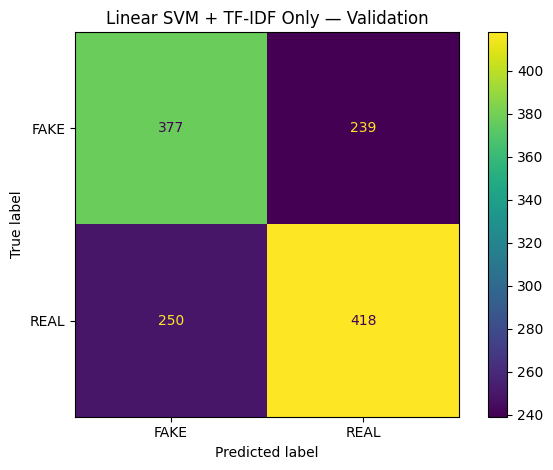

In [ ]:
# 11.10 LINEAR SVM + TF-IDF ONLY
# VALIDATION EVALUATION


# This section:
# 1. Uses the best Linear SVM model selected by GridSearchCV.
# 2. Generates predictions on the Validation dataset.
# 3. Calculates Accuracy, Precision, Recall, F1, and Macro F1.
# 4. Displays the classification report.
# 5. Displays the Validation confusion matrix.
# ============================================================


# ------------------------------------------------------------
# Generate Validation predictions
# ------------------------------------------------------------

tfidf_svm_validation_predictions = (
    tfidf_svm_grid_search.best_estimator_.predict(
        tfidf_validation_features
    )
)


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

# Overall classification accuracy.
tfidf_svm_validation_accuracy = accuracy_score(
    tfidf_validation_y,
    tfidf_svm_validation_predictions
)


# Precision for the FAKE class.
tfidf_svm_validation_precision = precision_score(
    tfidf_validation_y,
    tfidf_svm_validation_predictions,
    pos_label="FAKE"
)


# Recall for the FAKE class.
tfidf_svm_validation_recall = recall_score(
    tfidf_validation_y,
    tfidf_svm_validation_predictions,
    pos_label="FAKE"
)


# F1-score for the FAKE class.
tfidf_svm_validation_f1 = f1_score(
    tfidf_validation_y,
    tfidf_svm_validation_predictions,
    pos_label="FAKE"
)


# Macro F1 gives equal importance to REAL and FAKE.
tfidf_svm_validation_f1_macro = f1_score(
    tfidf_validation_y,
    tfidf_svm_validation_predictions,
    average="macro"
)


# ------------------------------------------------------------
# Display Validation results
# ------------------------------------------------------------

print("=" * 80)
print("LINEAR SVM + TF-IDF ONLY — VALIDATION PERFORMANCE")
print("=" * 80)

print(
    f"Accuracy       : "
    f"{tfidf_svm_validation_accuracy:.4f}"
)

print(
    f"Precision FAKE : "
    f"{tfidf_svm_validation_precision:.4f}"
)

print(
    f"Recall FAKE    : "
    f"{tfidf_svm_validation_recall:.4f}"
)

print(
    f"F1 FAKE        : "
    f"{tfidf_svm_validation_f1:.4f}"
)

print(
    f"F1 Macro       : "
    f"{tfidf_svm_validation_f1_macro:.4f}"
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        tfidf_validation_y,
        tfidf_svm_validation_predictions
    )
)


# ============================================================
# DISPLAY CONFUSION MATRIX
# ============================================================

tfidf_svm_confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        tfidf_validation_y,
        tfidf_svm_validation_predictions,
        labels=["FAKE", "REAL"]
    ),
    display_labels=[
        "FAKE",
        "REAL"
    ]
)


tfidf_svm_confusion_display.plot()

plt.title(
    "Linear SVM + TF-IDF Only — Validation"
)

plt.tight_layout()

plt.show()

In [ ]:
# 11.11 EXPERIMENT 4
# LINEAR SVM + TF-IDF + ENGINEERED FEATURES


# This experiment:
# 1. Uses Linear SVM as the classifier.
# 2. Uses 10,000 TF-IDF features.
# 3. Adds 3 engineered features:
#       - caps_ratio
#       - exclamation_count
#       - question_mark_count
# 4. Tests the Linear SVM hyperparameter combinations.
# 5. Uses 5-fold cross-validation on the Training dataset.
# 6. Uses Macro F1 for model selection.
# ============================================================


tfidf_engineered_svm_grid_search = tune_classification_model(

    # Linear SVM model defined earlier.
    model=linear_svm_model,

    # Linear SVM hyperparameter search space.
    parameter_grid=linear_svm_param_grid,

    # Combined TF-IDF + engineered features.
    training_features=tfidf_train_combined,

    # Training target labels.
    training_targets=tfidf_train_y,

    # Name used to identify this experiment.
    experiment_name=(
        "LINEAR SVM + "
        "TF-IDF + ENGINEERED FEATURES"
    )
)

HYPERPARAMETER TUNING — LINEAR SVM + TF-IDF + ENGINEERED FEATURES
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters:
{'C': 0.1, 'class_weight': 'balanced'}

Best cross-validation f1_macro: 0.6103

Best model:
LinearSVC(C=0.1, class_weight='balanced', max_iter=5000, random_state=42)


LINEAR SVM + TF-IDF + ENGINEERED FEATURES
VALIDATION PERFORMANCE
Accuracy       : 0.6207
Precision FAKE : 0.6035
Recall FAKE    : 0.6104
F1 FAKE        : 0.6069
F1 Macro       : 0.6203

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.60      0.61      0.61       616
        REAL       0.64      0.63      0.63       668

    accuracy                           0.62      1284
   macro avg       0.62      0.62      0.62      1284
weighted avg       0.62      0.62      0.62      1284



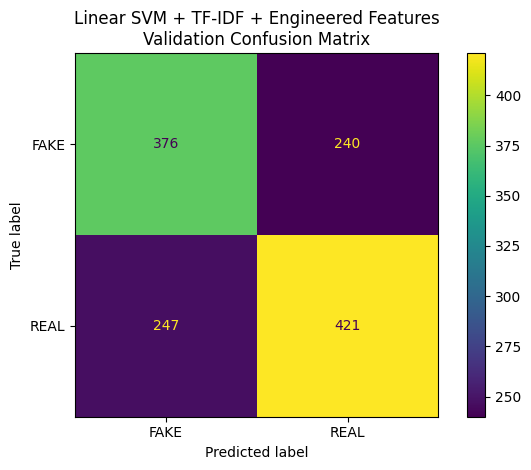

In [ ]:
# 11.12 LINEAR SVM + TF-IDF + ENGINEERED FEATURES
# VALIDATION EVALUATION


# This section:
# 1. Uses the best Linear SVM model selected by GridSearchCV.
# 2. Generates predictions on the Validation dataset.
# 3. Calculates Accuracy, Precision, Recall, F1, and Macro F1.
# 4. Displays the classification report.
# 5. Displays the Validation confusion matrix.
# ============================================================


# ------------------------------------------------------------
# Generate Validation predictions
# ------------------------------------------------------------

tfidf_engineered_svm_validation_predictions = (
    tfidf_engineered_svm_grid_search.best_estimator_.predict(
        tfidf_validation_combined
    )
)


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

# Overall classification accuracy.
tfidf_engineered_svm_validation_accuracy = accuracy_score(
    tfidf_validation_y,
    tfidf_engineered_svm_validation_predictions
)


# Precision for the FAKE class.
tfidf_engineered_svm_validation_precision = precision_score(
    tfidf_validation_y,
    tfidf_engineered_svm_validation_predictions,
    pos_label="FAKE"
)


# Recall for the FAKE class.
tfidf_engineered_svm_validation_recall = recall_score(
    tfidf_validation_y,
    tfidf_engineered_svm_validation_predictions,
    pos_label="FAKE"
)


# F1-score for the FAKE class.
tfidf_engineered_svm_validation_f1 = f1_score(
    tfidf_validation_y,
    tfidf_engineered_svm_validation_predictions,
    pos_label="FAKE"
)


# Macro F1 gives equal importance to REAL and FAKE.
tfidf_engineered_svm_validation_f1_macro = f1_score(
    tfidf_validation_y,
    tfidf_engineered_svm_validation_predictions,
    average="macro"
)


# ------------------------------------------------------------
# Display Validation results
# ------------------------------------------------------------

print("=" * 80)
print("LINEAR SVM + TF-IDF + ENGINEERED FEATURES")
print("VALIDATION PERFORMANCE")
print("=" * 80)

print(
    f"Accuracy       : "
    f"{tfidf_engineered_svm_validation_accuracy:.4f}"
)

print(
    f"Precision FAKE : "
    f"{tfidf_engineered_svm_validation_precision:.4f}"
)

print(
    f"Recall FAKE    : "
    f"{tfidf_engineered_svm_validation_recall:.4f}"
)

print(
    f"F1 FAKE        : "
    f"{tfidf_engineered_svm_validation_f1:.4f}"
)

print(
    f"F1 Macro       : "
    f"{tfidf_engineered_svm_validation_f1_macro:.4f}"
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        tfidf_validation_y,
        tfidf_engineered_svm_validation_predictions
    )
)


# ------------------------------------------------------------
# DISPLAY CONFUSION MATRIX
# ------------------------------------------------------------

tfidf_engineered_svm_confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        tfidf_validation_y,
        tfidf_engineered_svm_validation_predictions,
        labels=["FAKE", "REAL"]
    ),
    display_labels=[
        "FAKE",
        "REAL"
    ]
)


tfidf_engineered_svm_confusion_display.plot()

plt.title(
    "Linear SVM + TF-IDF + Engineered Features\n"
    "Validation Confusion Matrix"
)

plt.tight_layout()

plt.show()

AUTOMATIC CLASSICAL ML MODEL LEADERBOARD


,rank,model,features,best_parameters,cv_f1_macro,validation_accuracy,validation_precision_fake,validation_recall_fake,validation_f1_fake,validation_f1_macro
0,1,Logistic Regression,TF-IDF + Engineered Features,"{'C': 0.1, 'class_weight': 'balanced'}",0.610129,0.626168,0.603976,0.641234,0.622047,0.626124
1,2,Linear SVM,TF-IDF + Engineered Features,"{'C': 0.1, 'class_weight': 'balanced'}",0.610291,0.620717,0.603531,0.610390,0.606941,0.620250
2,3,Linear SVM,TF-IDF Only,"{'C': 0.1, 'class_weight': 'balanced'}",0.612748,0.619159,0.601276,0.612013,0.606597,0.618770
3,4,Logistic Regression,TF-IDF Only,"{'C': 1.0, 'class_weight': 'balanced'}",0.610393,0.614486,0.596491,0.607143,0.601770,0.614093



🏆 BEST CLASSICAL ML MODEL
Model               : Logistic Regression
Features             : TF-IDF + Engineered Features
Best Parameters      : {'C': 0.1, 'class_weight': 'balanced'}
CV F1 Macro          : 0.6101
Validation F1 Macro  : 0.6261

BEST MODEL — VALIDATION PERFORMANCE
Accuracy       : 0.6262
Precision FAKE : 0.6040
Recall FAKE    : 0.6412
F1 FAKE        : 0.6220
F1 Macro       : 0.6261

BEST MODEL — CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.60      0.64      0.62       616
        REAL       0.65      0.61      0.63       668

    accuracy                           0.63      1284
   macro avg       0.63      0.63      0.63      1284
weighted avg       0.63      0.63      0.63      1284


BEST MODEL — CONFUSION MATRIX
[[395 221]
 [259 409]]


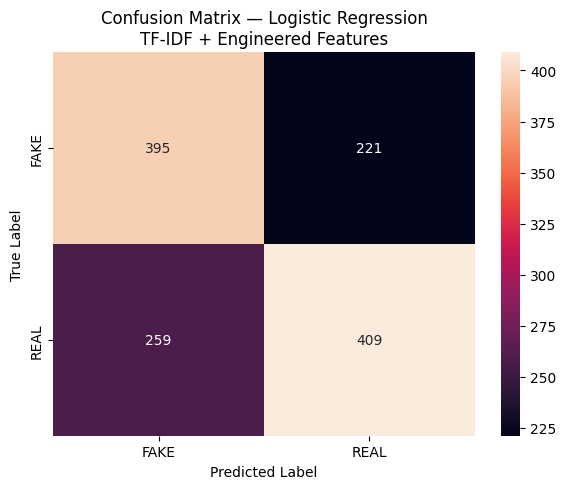

In [ ]:
# AUTOMATIC MODEL COMPARISON — CLASSICAL ML


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 1. COLLECT ALL CLASSICAL ML EXPERIMENTS
# ============================================================

all_model_results = [

    {
        "model": "Logistic Regression",
        "features": "TF-IDF Only",
        "grid_search": tfidf_logreg_grid_search,
        "validation_predictions": tfidf_logreg_validation_predictions
    },

    {
        "model": "Logistic Regression",
        "features": "TF-IDF + Engineered Features",
        "grid_search": tfidf_engineered_logreg_grid_search,
        "validation_predictions": tfidf_engineered_logreg_validation_predictions
    },

    {
        "model": "Linear SVM",
        "features": "TF-IDF Only",
        "grid_search": tfidf_svm_grid_search,
        "validation_predictions": tfidf_svm_validation_predictions
    },

    {
        "model": "Linear SVM",
        "features": "TF-IDF + Engineered Features",
        "grid_search": tfidf_engineered_svm_grid_search,
        "validation_predictions": tfidf_engineered_svm_validation_predictions
    }
]


# ============================================================
# 2. AUTOMATICALLY CALCULATE VALIDATION METRICS
# ============================================================

for experiment in all_model_results:

    y_true = tfidf_validation_y
    y_pred = experiment["validation_predictions"]

    # Validation metrics
    experiment["validation_accuracy"] = accuracy_score(
        y_true,
        y_pred
    )

    experiment["validation_precision_fake"] = precision_score(
        y_true,
        y_pred,
        pos_label="FAKE"
    )

    experiment["validation_recall_fake"] = recall_score(
        y_true,
        y_pred,
        pos_label="FAKE"
    )

    experiment["validation_f1_fake"] = f1_score(
        y_true,
        y_pred,
        pos_label="FAKE"
    )

    experiment["validation_f1_macro"] = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    # Hyperparameter tuning results
    experiment["cv_f1_macro"] = (
        experiment["grid_search"].best_score_
    )

    experiment["best_parameters"] = (
        experiment["grid_search"].best_params_
    )

    # Actual trained best estimator
    experiment["best_estimator"] = (
        experiment["grid_search"].best_estimator_
    )


# ============================================================
# 3. CREATE AUTOMATIC COMPARISON TABLE
# ============================================================

model_comparison_df = pd.DataFrame([

    {
        "model": experiment["model"],
        "features": experiment["features"],
        "best_parameters": experiment["best_parameters"],
        "cv_f1_macro": experiment["cv_f1_macro"],
        "validation_accuracy": experiment["validation_accuracy"],
        "validation_precision_fake": experiment["validation_precision_fake"],
        "validation_recall_fake": experiment["validation_recall_fake"],
        "validation_f1_fake": experiment["validation_f1_fake"],
        "validation_f1_macro": experiment["validation_f1_macro"]
    }

    for experiment in all_model_results
])


# ============================================================
# 4. AUTOMATICALLY SORT BY VALIDATION F1 MACRO
# ============================================================

model_comparison_df = (
    model_comparison_df
    .sort_values(
        by="validation_f1_macro",
        ascending=False
    )
    .reset_index(drop=True)
)


# Add ranking

model_comparison_df.insert(
    0,
    "rank",
    range(1, len(model_comparison_df) + 1)
)


# ============================================================
# 5. DISPLAY CLASSICAL ML LEADERBOARD
# ============================================================

print("=" * 110)
print("AUTOMATIC CLASSICAL ML MODEL LEADERBOARD")
print("=" * 110)

display(model_comparison_df)


# ============================================================
# 6. AUTOMATICALLY FIND BEST EXPERIMENT
# ============================================================

best_model_result = max(
    all_model_results,
    key=lambda experiment: experiment["validation_f1_macro"]
)


# ============================================================
# 7. EXTRACT EVERYTHING FROM THE SAME BEST EXPERIMENT
# ============================================================

best_model_name = best_model_result["model"]

best_model_features = best_model_result["features"]

best_model_parameters = best_model_result["best_parameters"]

best_model_cv_f1_macro = best_model_result["cv_f1_macro"]

best_model_estimator = best_model_result["best_estimator"]

best_model_predictions = best_model_result[
    "validation_predictions"
]

best_model_accuracy = best_model_result[
    "validation_accuracy"
]

best_model_precision_fake = best_model_result[
    "validation_precision_fake"
]

best_model_recall_fake = best_model_result[
    "validation_recall_fake"
]

best_model_f1_fake = best_model_result[
    "validation_f1_fake"
]

best_model_f1_macro = best_model_result[
    "validation_f1_macro"
]


# ============================================================
# 8. BEST CLASSICAL ML MODEL
# ============================================================

print("\n" + "=" * 110)
print("🏆 BEST CLASSICAL ML MODEL")
print("=" * 110)

print(f"Model               : {best_model_name}")
print(f"Features             : {best_model_features}")
print(f"Best Parameters      : {best_model_parameters}")
print(f"CV F1 Macro          : {best_model_cv_f1_macro:.4f}")
print(f"Validation F1 Macro  : {best_model_f1_macro:.4f}")


# ============================================================
# 9. BEST MODEL — VALIDATION PERFORMANCE
# ============================================================

print("\n" + "=" * 110)
print("BEST MODEL — VALIDATION PERFORMANCE")
print("=" * 110)

print(f"Accuracy       : {best_model_accuracy:.4f}")
print(f"Precision FAKE : {best_model_precision_fake:.4f}")
print(f"Recall FAKE    : {best_model_recall_fake:.4f}")
print(f"F1 FAKE        : {best_model_f1_fake:.4f}")
print(f"F1 Macro       : {best_model_f1_macro:.4f}")


# ============================================================
# 10. BEST MODEL — CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 110)
print("BEST MODEL — CLASSIFICATION REPORT")
print("=" * 110)

print(
    classification_report(
        tfidf_validation_y,
        best_model_predictions
    )
)


# ============================================================
# 11. BEST MODEL — CONFUSION MATRIX
# ============================================================

best_model_confusion_matrix = confusion_matrix(
    tfidf_validation_y,
    best_model_predictions,
    labels=["FAKE", "REAL"]
)


print("\n" + "=" * 110)
print("BEST MODEL — CONFUSION MATRIX")
print("=" * 110)

print(best_model_confusion_matrix)


# ============================================================
# 12. PLOT BEST MODEL CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    best_model_confusion_matrix,
    annot=True,
    fmt="d",
    xticklabels=["FAKE", "REAL"],
    yticklabels=["FAKE", "REAL"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    f"Confusion Matrix — {best_model_name}\n"
    f"{best_model_features}"
)

plt.tight_layout()
plt.show()

## Conclusion — Classical ML Models

The best-performing classical ML model is **Logistic Regression with TF-IDF + Engineered Features**, using **C = 0.1** and **balanced class weights**.

It achieved a **Validation F1 Macro of 0.6291** and **Validation Accuracy of 0.6262**, which was the highest Validation Macro F1 among the four tested classical ML configurations.

Adding engineered features improved the performance of both Logistic Regression and Linear SVM compared with TF-IDF alone.

This model will serve as the **classical ML benchmark** for comparison with the upcoming deep-learning models.

### Confusion Matrix

The model correctly classified:

- **395 FAKE** statements as FAKE.
- **409 REAL** statements as REAL.

It misclassified:

- **221 FAKE** statements as REAL.
- **259 REAL** statements as FAKE.


**🏆 Current Benchmark:** Logistic Regression + TF-IDF + Engineered Features — **F1 Macro: 0.6292**

# 12. Deep Learning

## BiLSTM

In [ ]:
# 12.1 DEEP LEARNING — IMPORTS AND CONFIGURATION


# Import required libraries.
import os
import random
import numpy as np
import pandas as pd
import torch

# Import PyTorch dataset and dataloader utilities.
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# REPRODUCIBILITY


# Fixed random seed for reproducible results.
DEEP_LEARNING_RANDOM_STATE = 42

random.seed(DEEP_LEARNING_RANDOM_STATE)
np.random.seed(DEEP_LEARNING_RANDOM_STATE)
torch.manual_seed(DEEP_LEARNING_RANDOM_STATE)

# Set the same seed for all CUDA devices if a GPU is available.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(
        DEEP_LEARNING_RANDOM_STATE
    )


# ------------------------------------------------------------
# DEVICE CONFIGURATION


# Use GPU when available; otherwise use CPU.
DEEP_LEARNING_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ------------------------------------------------------------
# DISPLAY CONFIGURATION


print("=" * 80)
print("DEEP LEARNING CONFIGURATION")
print("=" * 80)

print(
    "Random state :",
    DEEP_LEARNING_RANDOM_STATE
)

print(
    "Device       :",
    DEEP_LEARNING_DEVICE
)

DEEP LEARNING CONFIGURATION
Random state : 42
Device       : cuda


"government announces new policy"
              ↓
       Word tokenization
              ↓
       [25, 417, 83, 192]
              ↓
          Embedding
              ↓
   128-dimensional vectors
              ↓
        Bidirectional
           LSTM
       ↙           ↘
   Forward       Backward
       ↘           ↙
        256 features
              ↓
        Multi-Head
          Attention
              ↓
    Focus on useful contextual
         information
              ↓
       Context vector
              ↓
          Dropout
              ↓
       Linear classifier
              ↓
           Logit
              ↓
        FAKE / REAL

In [ ]:

# ============================================================
# 12.2 LOAD PROCESSED DATA FOR DEEP LEARNING
# ============================================================

# Load the processed training dataset.
bilstm_train_df = pd.read_csv(
    TRAIN_PROCESSED_PATH
)

# Load the processed validation dataset.
bilstm_validation_df = pd.read_csv(
    VALIDATION_PROCESSED_PATH
)

# Load the processed test dataset.
bilstm_test_df = pd.read_csv(
    TEST_PROCESSED_PATH
)


# ============================================================
# DISPLAY DATASET SHAPES
# ============================================================

print("=" * 80)
print("DEEP LEARNING DATASETS")
print("=" * 80)

# Display the number of rows and columns in each split.
print("Train      :", bilstm_train_df.shape)
print("Validation :", bilstm_validation_df.shape)
print("Test       :", bilstm_test_df.shape)

DEEP LEARNING DATASETS
Train      : (10240, 19)
Validation : (1284, 19)
Test       : (1267, 19)


In [ ]:
# ============================================================
# 12.3 PREPARE TEXT AND TARGETS FOR BiLSTM
# ============================================================

# This section:
# 1. Extracts cleaned statements as the text input for the BiLSTM.
# 2. Extracts binary labels as the prediction targets.
# 3. Keeps Train, Validation, and Test data completely separate.
# 4. Verifies the number of text samples and targets in each split.


# ------------------------------------------------------------
# Text inputs
# ------------------------------------------------------------

# Extract cleaned training statements.
bilstm_train_text = bilstm_train_df["cleaned_statement"]

# Extract cleaned validation statements.
bilstm_validation_text = bilstm_validation_df["cleaned_statement"]

# Extract cleaned test statements.
bilstm_test_text = bilstm_test_df["cleaned_statement"]


# ------------------------------------------------------------
# Target labels
# ------------------------------------------------------------

# Extract training labels.
bilstm_train_y = bilstm_train_df["binary_label"]

# Extract validation labels.
bilstm_validation_y = bilstm_validation_df["binary_label"]

# Extract test labels.
bilstm_test_y = bilstm_test_df["binary_label"]


# ------------------------------------------------------------
# Verify dimensions
# ------------------------------------------------------------

print("=" * 80)
print("BiLSTM TEXT AND TARGET DIMENSIONS")
print("=" * 80)

print("Train text      :", bilstm_train_text.shape)
print("Validation text :", bilstm_validation_text.shape)
print("Test text       :", bilstm_test_text.shape)

print()

print("Train target      :", bilstm_train_y.shape)
print("Validation target :", bilstm_validation_y.shape)
print("Test target       :", bilstm_test_y.shape)

BiLSTM TEXT AND TARGET DIMENSIONS
Train text      : (10240,)
Validation text : (1284,)
Test text       : (1267,)

Train target      : (10240,)
Validation target : (1284,)
Test target       : (1267,)


In [ ]:
# ============================================================
# 12.4 BUILD BiLSTM VOCABULARY AND TOKENIZE TEXT
# ============================================================

# This section:
# 1. Builds the vocabulary using the Training text only.
# 2. Reserves index 0 for padding.
# 3. Reserves index 1 for unknown words.
# 4. Converts Train, Validation, and Test text into integer sequences.
# 5. Uses the same Training vocabulary for Validation and Test data.
# 6. Prevents information from Validation or Test from entering the vocabulary.

# Example
# "government announces new policy"

# "government changes policy"

# "new policy improves economy"

# Word	          Number
# <PAD>	            0
# <UNK>            	1
# government	      2
# policy          	3
# new	              4
# announces       	5
# changes	          6
# economy	          7
# improves        	8

# This is called our vocabulary.


from collections import Counter


# ------------------------------------------------------------
# BiLSTM vocabulary configuration
# ------------------------------------------------------------

# Index 0 is reserved for padding sequences.
BILSTM_PAD_TOKEN = "<PAD>"
# Example
# government changes policy -            3 words [2, 6, 3, 0, 0]
# government announces new policy today- 5 words  [2, 5, 4, 3, 9]

# Index 1 represents words not found in the Training vocabulary.
BILSTM_UNK_TOKEN = "<UNK>"
# Example
# Train-      government policy economy   [2, 3, 7]
# validation- government inflation policy [2, 1, 3]

# Maximum vocabulary size used by the BiLSTM.
BILSTM_MAX_VOCAB_SIZE = 30000


# ------------------------------------------------------------
# Build vocabulary from Training text only
# ------------------------------------------------------------

# Count how many times each word appears in the Training statements.
bilstm_word_counts = Counter(
    word
    for statement in bilstm_train_text
    for word in str(statement).split()
)


# Keep the most frequent words up to the configured vocabulary size.
bilstm_most_common_words = (
    bilstm_word_counts
    .most_common(BILSTM_MAX_VOCAB_SIZE - 2) # 2 are reserved for PAD and UNK, 29,998 actual words
)


# Create the word-to-index mapping. start dictionary with 0,1
bilstm_word_to_index = {
    BILSTM_PAD_TOKEN: 0,
    BILSTM_UNK_TOKEN: 1
}

# then it will loop through

# Assign a unique integer index to each vocabulary word.
for index, (word, count) in enumerate(
    bilstm_most_common_words,
    start=2
):
    bilstm_word_to_index[word] = index


# ------------------------------------------------------------
# Create reverse index mapping
# ------------------------------------------------------------

# Create an index-to-word mapping for interpreting predictions later.
bilstm_index_to_word = {
    index: word
    for word, index in bilstm_word_to_index.items()
}


# ------------------------------------------------------------
# Convert text into integer sequences
# Now convert sentences to numbers
# ------------------------------------------------------------

def bilstm_text_to_sequence(text):
    """
    Convert a text statement into a sequence of vocabulary indices.
    """

    # Split the statement into individual words.
    words = str(text).split()

    # Convert each word into its vocabulary index.
    # Unknown words receive the <UNK> index.
    sequence = [
        bilstm_word_to_index.get(
            word,
            bilstm_word_to_index[BILSTM_UNK_TOKEN]
        )
        for word in words
    ]

    return sequence

# use only Training vocabulary for all three datasets
# Convert Training statements into integer sequences.
bilstm_train_sequences = [
    bilstm_text_to_sequence(text)
    for text in bilstm_train_text
]


# Convert Validation statements using the Training vocabulary.
bilstm_validation_sequences = [
    bilstm_text_to_sequence(text)
    for text in bilstm_validation_text
]


# Convert Test statements using the Training vocabulary.
bilstm_test_sequences = [
    bilstm_text_to_sequence(text)
    for text in bilstm_test_text
]

# creates a vocabulary from the training text and converts every statement
# into a sequence of integer IDs that the neural network can process.

# ------------------------------------------------------------
# Display vocabulary information
# ------------------------------------------------------------

print("=" * 80)
print("BiLSTM VOCABULARY")
print("=" * 80)

print("Vocabulary size :", len(bilstm_word_to_index))
print("PAD index       :", bilstm_word_to_index[BILSTM_PAD_TOKEN])
print("UNK index       :", bilstm_word_to_index[BILSTM_UNK_TOKEN])

print()

print("Training sequences   :", len(bilstm_train_sequences))
print("Validation sequences :", len(bilstm_validation_sequences))
print("Test sequences       :", len(bilstm_test_sequences))

BiLSTM VOCABULARY
Vocabulary size : 18199
PAD index       : 0
UNK index       : 1

Training sequences   : 10240
Validation sequences : 1284
Test sequences       : 1267


In [ ]:
# ============================================================
# 12.5 PAD BiLSTM SEQUENCES
# ============================================================

# This section:
# 1. Finds a suitable maximum sequence length from the Training data.
# 2. Pads shorter sequences with the <PAD> value (0).
# 3. Truncates sequences longer than the selected maximum length.
# 4. Applies the same maximum length to Train, Validation, and Test.
# 5. Converts all text sequences into equal-length numerical arrays.


from tensorflow.keras.preprocessing.sequence import pad_sequences


# ------------------------------------------------------------
# Determine maximum sequence length
# ------------------------------------------------------------

# Calculate the length of every Training sequence.
bilstm_train_sequence_lengths = [
    len(sequence)
    for sequence in bilstm_train_sequences
]

# Use the 95th percentile to avoid very long outlier statements
# The 95th percentile is approximately the sequence length
  # below which 95% of the training samples fall.
# determining an unnecessarily large sequence length.

# 95% of statements → ≤ 80 words
# 4% of statements  → 81–150 words
# 1% of statements → 500 words

# Statement with 50 words
# → padded to 80

# Statement with 80 words
# → stays at 80

# Statement with 120 words
# → truncated to 80


bilstm_max_sequence_length = int(
    np.percentile(
        bilstm_train_sequence_lengths,
        95
    )
)

print("=" * 80)
print("BiLSTM SEQUENCE LENGTH")
print("=" * 80)

print(
    "95th percentile length :",
    bilstm_max_sequence_length
)


# ------------------------------------------------------------
# Pad Training sequences
# ------------------------------------------------------------

# Pad or truncate Training sequences to the same length.
bilstm_train_padded = pad_sequences(
    bilstm_train_sequences,
    maxlen=bilstm_max_sequence_length,
    padding="post", # paddding will be done after the sequence
    truncating="post", # remove the end words
    value=0 # use 0 as padding
)


# ------------------------------------------------------------
# Pad Validation sequences
# ------------------------------------------------------------

# Use the SAME maximum length determined from Training data.
bilstm_validation_padded = pad_sequences(
    bilstm_validation_sequences,
    maxlen=bilstm_max_sequence_length,
    padding="post",
    truncating="post",
    value=0
)


# ------------------------------------------------------------
# Pad Test sequences
# ------------------------------------------------------------

# Use the SAME maximum length for the Test data.
bilstm_test_padded = pad_sequences(
    bilstm_test_sequences,
    maxlen=bilstm_max_sequence_length,
    padding="post",
    truncating="post",
    value=0
)


# ------------------------------------------------------------
# Display resulting shapes
# ------------------------------------------------------------

print("\nPadded sequence shapes:")

print(
    "Train      :",
    bilstm_train_padded.shape
)

print(
    "Validation :",
    bilstm_validation_padded.shape
)

print(
    "Test       :",
    bilstm_test_padded.shape
)

BiLSTM SEQUENCE LENGTH
95th percentile length : 33

Padded sequence shapes:
Train      : (10240, 33)
Validation : (1284, 33)
Test       : (1267, 33)


In [ ]:
# ============================================================
# 12.6 PREPARE BiLSTM TARGET LABELS
# ============================================================

# This section:
# 1. Converts FAKE and REAL labels into numerical values.
# 2. Uses the same label mapping for Train, Validation, and Test.
# 3. Converts the Pandas Series into NumPy arrays.
# 4. Verifies the resulting target labels and their shapes.


# ------------------------------------------------------------
# Define label mapping
# ------------------------------------------------------------

# Convert FAKE into 0 and REAL into 1 for binary classification.
BILSTM_LABEL_MAPPING = {
    "FAKE": 0,
    "REAL": 1
}


# ------------------------------------------------------------
# Convert labels to numerical values
# ------------------------------------------------------------

# Convert Training labels using the same mapping.
bilstm_train_y_numeric = (
    bilstm_train_y
    .map(BILSTM_LABEL_MAPPING)
    .to_numpy()
)

# Convert Validation labels using the same mapping.
bilstm_validation_y_numeric = (
    bilstm_validation_y
    .map(BILSTM_LABEL_MAPPING)
    .to_numpy()
)

# Convert Test labels using the same mapping.
bilstm_test_y_numeric = (
    bilstm_test_y
    .map(BILSTM_LABEL_MAPPING)
    .to_numpy()
)


# ------------------------------------------------------------
# Verify target labels
# ------------------------------------------------------------

print("=" * 80)
print("BiLSTM TARGET LABEL VERIFICATION")
print("=" * 80)

# Display the unique numerical labels present in each split.
print(
    "Train labels      :",
    np.unique(bilstm_train_y_numeric)
)

print(
    "Validation labels :",
    np.unique(bilstm_validation_y_numeric)
)

print(
    "Test labels       :",
    np.unique(bilstm_test_y_numeric)
)


# ------------------------------------------------------------
# Verify target shapes
# ------------------------------------------------------------

print("\nTarget shapes:")

print(
    "Train      :",
    bilstm_train_y_numeric.shape
)

print(
    "Validation :",
    bilstm_validation_y_numeric.shape
)

print(
    "Test       :",
    bilstm_test_y_numeric.shape
)

BiLSTM TARGET LABEL VERIFICATION
Train labels      : [0 1]
Validation labels : [0 1]
Test labels       : [0 1]

Target shapes:
Train      : (10240,)
Validation : (1284,)
Test       : (1267,)


In [ ]:
# ============================================================
# 12.7 CREATE PyTorch DATASET AND DATALOADERS
# ============================================================

# This section:
# 1. Creates a custom PyTorch Dataset for the BiLSTM data.
# 2. Stores the padded text sequences and numerical targets together.
# 3. Creates separate datasets for Train, Validation, and Test.
# 4. Creates DataLoaders to provide the data in batches.
# 5. Shuffles only the Training data.
# 6. Keeps Validation and Test data in their original order.


from torch.utils.data import Dataset, DataLoader


# ============================================================
# DEFINE CUSTOM DATASET
# ============================================================

class BiLSTMTextDataset(Dataset):

    # Initialize the dataset with input sequences and targets.
    def __init__(self, sequences, targets):

        # Convert input sequences into PyTorch integer tensors.
        self.sequences = torch.tensor(
            sequences,
            dtype=torch.long
        )

        # Convert targets into PyTorch floating-point tensors.
        self.targets = torch.tensor(
            targets,
            dtype=torch.float32
        )

    # Return the total number of samples in the dataset.
    def __len__(self):
        return len(self.targets)

    # Return one input sequence and its corresponding target.
    def __getitem__(self, index):
        return (
            self.sequences[index],
            self.targets[index]
        )


# ============================================================
# CREATE DATASETS
# ============================================================

# Create the Training Dataset from padded sequences and labels.
bilstm_train_dataset = BiLSTMTextDataset(
    bilstm_train_padded,
    bilstm_train_y_numeric
)

# Create the Validation Dataset.
bilstm_validation_dataset = BiLSTMTextDataset(
    bilstm_validation_padded,
    bilstm_validation_y_numeric
)

# Create the Test Dataset.
bilstm_test_dataset = BiLSTMTextDataset(
    bilstm_test_padded,
    bilstm_test_y_numeric
)


# ============================================================
# DATALOADER CONFIGURATION
# ============================================================

# Number of samples processed together during one training step.
BILSTM_BATCH_SIZE = 64


# Create the Training DataLoader.
# shuffle=True randomly changes the order of training samples each epoch.
bilstm_train_loader = DataLoader(
    bilstm_train_dataset,
    batch_size=BILSTM_BATCH_SIZE,
    shuffle=True
)

# Create the Validation DataLoader.
# shuffle=False keeps validation samples in a fixed order.
bilstm_validation_loader = DataLoader(
    bilstm_validation_dataset,
    batch_size=BILSTM_BATCH_SIZE,
    shuffle=False
)

# Create the Test DataLoader.
# shuffle=False keeps test samples in a fixed order.
bilstm_test_loader = DataLoader(
    bilstm_test_dataset,
    batch_size=BILSTM_BATCH_SIZE,
    shuffle=False
)


# ============================================================
# VERIFY DATALOADERS
# ============================================================

print("=" * 80)
print("BiLSTM DATASET AND DATALOADER VERIFICATION")
print("=" * 80)

print("Training samples   :", len(bilstm_train_dataset))
print("Validation samples :", len(bilstm_validation_dataset))
print("Test samples       :", len(bilstm_test_dataset))

print()

print("Batch size         :", BILSTM_BATCH_SIZE)
print("Training batches   :", len(bilstm_train_loader))
print("Validation batches :", len(bilstm_validation_loader))
print("Test batches       :", len(bilstm_test_loader))

BiLSTM DATASET AND DATALOADER VERIFICATION
Training samples   : 10240
Validation samples : 1284
Test samples       : 1267

Batch size         : 64
Training batches   : 160
Validation batches : 21
Test batches       : 20


In [ ]:
# ============================================================
# 12.8 BUILD BiLSTM + ATTENTION MODEL
# ============================================================

# This section:
# 1. Creates an Embedding layer to convert word IDs into dense vectors.
# 2. Uses a Bidirectional LSTM to learn information from both directions.
# 3. Applies self-attention to identify important parts of the statement.
# 4. Combines the attention output into a single representation.
# 5. Applies Dropout to reduce overfitting.
# 6. Uses a final Dense layer for binary FAKE/REAL classification.

# The Embedding layer converts each ID into a vector

# Attention basically asks:
# "Which parts of the sequence should
  #I pay more attention to when making the prediction?"

  # Example:
  # The government announced a completely false economic report
  # For the FAKE/REAL decision, the word: "false" might carry useful information


import torch
import torch.nn as nn


# ============================================================
# MODEL CONFIGURATION
# ============================================================

# Number of words available in the BiLSTM vocabulary (converted into no.).
BILSTM_VOCAB_SIZE = len(bilstm_word_to_index)

# The numbers themselves don't have useful meaning to the neural network.
# So we pass them through several stages

# Size of the vector representation created for each word.
BILSTM_EMBEDDING_DIM = 128 # means each word gets represented by a 128-dimensional vector.

# Number of hidden units in each LSTM direction.
BILSTM_HIDDEN_DIM = 128

# Number of attention heads.
BILSTM_ATTENTION_HEADS = 4
# You can think of the four heads as four different ways of
  # examining relationships within the sentence

  # Sentence
 #┌───────────────┐
 #│ Attention 1   │ → looks at one type of relationship
 #│ Attention 2   │ → another type
 #│ Attention 3   │ → another type
 #│ Attention 4   │ → another type
 #└───────────────┘
  # Combined information

# Dropout probability used to reduce overfitting.
BILSTM_DROPOUT = 0.30


# ============================================================
# BiLSTM + ATTENTION MODEL
# ============================================================

class BiLSTMAttentionClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        attention_heads,
        dropout
    ):

        super().__init__()

        # Convert each word ID into a dense embedding vector.
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        # Bidirectional LSTM reads the sequence from both directions.
        self.bilstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        # Self-attention allows the model to identify important tokens.
        self.attention = nn.MultiheadAttention(
            embed_dim=hidden_dim * 2, #128 forward and backward
            num_heads=attention_heads,
            dropout=dropout,
            batch_first=True
        )

        # Why does Attention come after BiLSTM?

          # This is a very useful way to think about our architecture:

          # BiLSTM:

          # "Understand the context of every word."

          # Attention:

          # "Now decide which contextual information is most useful."


        # Dropout helps reduce overfitting.
        self.dropout = nn.Dropout(dropout)

        # Final layer converts the attention representation into one
        # value representing the binary classification output.
        self.classifier = nn.Linear(
            hidden_dim * 2,
            1   # logit , later converted into probability and then into REAL or FAKE
        )


    def forward(self, input_ids):

        # Convert token IDs into embedding vectors.
        embedded = self.embedding(input_ids)

        # Pass embeddings through the Bidirectional LSTM.
        lstm_output, _ = self.bilstm(embedded)

        # Use the LSTM output as Query, Key, and Value for self-attention.
        attention_output, _ = self.attention(
            lstm_output,
            lstm_output,
            lstm_output
        )

        # Conceptually:

         # We're asking the attention mechanism to examine the BiLSTM's sequence
           # representations and determine how the different positions relate to each other.

        # Average the attention representations across the sequence.
        # Attention produces information for every position in the sentence.
        context_vector = attention_output.mean(dim=1)

        # Apply dropout before classification.
        context_vector = self.dropout(context_vector)

        # Produce the final binary classification logit.
        output = self.classifier(
            context_vector
        )

        # Remove the final dimension so output shape becomes (batch_size,).
        return output.squeeze(1)


# ============================================================
# CREATE MODEL
# ============================================================

# Create the BiLSTM + Attention model with the configured parameters.
bilstm_attention_model = BiLSTMAttentionClassifier(
    vocab_size=BILSTM_VOCAB_SIZE,
    embedding_dim=BILSTM_EMBEDDING_DIM,
    hidden_dim=BILSTM_HIDDEN_DIM,
    attention_heads=BILSTM_ATTENTION_HEADS,
    dropout=BILSTM_DROPOUT
)


# Move the model to GPU if available, otherwise use CPU.
bilstm_attention_model = bilstm_attention_model.to(
    DEEP_LEARNING_DEVICE
)


# ============================================================
# DISPLAY MODEL
# ============================================================

print("=" * 80)
print("BiLSTM + ATTENTION MODEL")
print("=" * 80)

print(bilstm_attention_model)

BiLSTM + ATTENTION MODEL
BiLSTMAttentionClassifier(
  (embedding): Embedding(18199, 128, padding_idx=0)
  (bilstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=1, bias=True)
)


                 LSTM
                   │
       ┌───────────┼───────────┐
       ↓           ↓           ↓
    Forget       Input       Output
     Gate         Gate         Gate
       │           │           │
    Sigmoid      Sigmoid     Sigmoid
                   │
                 Tanh

In [ ]:
# ============================================================
# 12.9 CONFIGURE BiLSTM TRAINING
# ============================================================

# This section:
# 1. Defines the loss function for binary classification.
# 2. Defines the optimizer that updates the model weights.
# 3. Sets the learning rate.
# 4. Sets the number of training epochs.
# 5. Displays the training configuration.


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

# Binary classification loss.
# This loss compares the model's predicted logit with the
# actual FAKE/REAL target.
bilstm_loss_function = nn.BCEWithLogitsLoss()


# Adam optimizer updates the model's weights during training.
bilstm_optimizer = torch.optim.Adam(
    bilstm_attention_model.parameters(),
    lr=0.001
)


# Number of complete passes through the Training dataset.
BILSTM_EPOCHS = 20


# ------------------------------------------------------------
# Display training configuration
# ------------------------------------------------------------

print("=" * 80)
print("BiLSTM TRAINING CONFIGURATION")
print("=" * 80)

print("Loss function :", bilstm_loss_function)
print("Optimizer     :", bilstm_optimizer.__class__.__name__)
print("Learning rate : 0.001")
print("Epochs        :", BILSTM_EPOCHS)
print("Batch size    :", BILSTM_BATCH_SIZE)
print("Device        :", DEEP_LEARNING_DEVICE)

BiLSTM TRAINING CONFIGURATION
Loss function : BCEWithLogitsLoss()
Optimizer     : Adam
Learning rate : 0.001
Epochs        : 20
Batch size    : 64
Device        : cuda


In [ ]:
# ============================================================
# 12.10 BiLSTM TRAINING + VALIDATION LOOP
# ============================================================

# This section:
# 1. Trains the BiLSTM + Attention model using the Training data.
# 2. Calculates training loss for every epoch.
# 3. Evaluates the model on Validation data after each epoch.
# 4. Calculates validation loss and classification metrics.
# 5. Stores the results in a history dictionary.
# 6. Keeps the best model weights based on Validation F1 Macro.


# ============================================================
# INITIALIZE TRAINING HISTORY
# ============================================================

# Store training and validation results for every epoch.
bilstm_training_history = {
    "train_loss": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "validation_f1_macro": []
}


# Store the best Validation F1 Macro seen during training.
bilstm_best_validation_f1 = -float("inf")

# Store the epoch number corresponding to the best validation score.
bilstm_best_epoch = 0

# Store a copy of the best model weights.
bilstm_best_state_dict = None


# ============================================================
# TRAINING LOOP
# ============================================================

for bilstm_epoch in range(BILSTM_EPOCHS):

    # --------------------------------------------------------
    # TRAINING MODE
    # --------------------------------------------------------

    # Put the model into training mode.
    bilstm_attention_model.train()

    # Reset the total training loss for this epoch.
    bilstm_epoch_train_loss = 0.0


    # --------------------------------------------------------
    # PROCESS TRAINING BATCHES
    # --------------------------------------------------------

    for bilstm_batch_inputs, bilstm_batch_targets in bilstm_train_loader:

        # Move the input batch to the selected device.
        bilstm_batch_inputs = bilstm_batch_inputs.to(
            DEEP_LEARNING_DEVICE
        )

        # Move the target batch to the selected device.
        bilstm_batch_targets = bilstm_batch_targets.to(
            DEEP_LEARNING_DEVICE
        )

        # Clear gradients from the previous batch.
        bilstm_optimizer.zero_grad()

        # Generate predictions from the model.
        # forward propogation
        bilstm_batch_outputs = bilstm_attention_model(
            bilstm_batch_inputs
        )

        # Calculate the classification loss.
        bilstm_batch_loss = bilstm_loss_function(
            bilstm_batch_outputs,
            bilstm_batch_targets
        )

        # Calculate gradients through backpropagation.
        bilstm_batch_loss.backward()

        # Update the model weights.
        bilstm_optimizer.step()

        # Add this batch's loss to the epoch loss.
        bilstm_epoch_train_loss += (
            bilstm_batch_loss.item()
        )


    # Calculate average training loss for the epoch.
    bilstm_epoch_train_loss /= len(
        bilstm_train_loader
    )


    # ========================================================
    # VALIDATION MODE
    # ========================================================

    # Put the model into evaluation mode.
    bilstm_attention_model.eval()

    # Reset validation loss.
    bilstm_epoch_validation_loss = 0.0

    # Store validation predictions and targets.
    bilstm_validation_predictions_epoch = []
    bilstm_validation_targets_epoch = []


    # Disable gradient calculation during validation.
    with torch.no_grad():

        for (
            bilstm_batch_inputs,
            bilstm_batch_targets
        ) in bilstm_validation_loader:

            # Move inputs to the selected device.
            bilstm_batch_inputs = bilstm_batch_inputs.to(
                DEEP_LEARNING_DEVICE
            )

            # Move targets to the selected device.
            bilstm_batch_targets = bilstm_batch_targets.to(
                DEEP_LEARNING_DEVICE
            )

            # Generate validation predictions.
            # Forward pass
            bilstm_batch_outputs = bilstm_attention_model(
                bilstm_batch_inputs
            )

            # Calculate validation loss.
            bilstm_batch_loss = bilstm_loss_function(
                bilstm_batch_outputs,
                bilstm_batch_targets
            )

            # Add batch loss to validation loss.
            bilstm_epoch_validation_loss += (
                bilstm_batch_loss.item()
            )

            # Convert logits into probabilities.
            bilstm_batch_probabilities = torch.sigmoid(
                bilstm_batch_outputs
            )

            # Convert probabilities into binary predictions.
            bilstm_batch_predictions = (
                bilstm_batch_probabilities >= 0.5
            ).long()

            # Store predictions.
            bilstm_validation_predictions_epoch.extend(
                bilstm_batch_predictions.cpu().numpy()
            )

            # Store actual targets.
            bilstm_validation_targets_epoch.extend(
                bilstm_batch_targets.cpu().numpy()
            )


    # Calculate average validation loss.
    bilstm_epoch_validation_loss /= len(
        bilstm_validation_loader
    )


    # ========================================================
    # VALIDATION METRICS
    # ========================================================

    # Calculate Validation Accuracy.
    bilstm_epoch_validation_accuracy = accuracy_score(
        bilstm_validation_targets_epoch,
        bilstm_validation_predictions_epoch
    )

    # Calculate Validation Macro F1.
    bilstm_epoch_validation_f1_macro = f1_score(
        bilstm_validation_targets_epoch,
        bilstm_validation_predictions_epoch,
        average="macro"
    )


    # ========================================================
    # SAVE EPOCH RESULTS
    # ========================================================

    # Save training loss.
    bilstm_training_history["train_loss"].append(
        bilstm_epoch_train_loss
    )

    # Save validation loss.
    bilstm_training_history["validation_loss"].append(
        bilstm_epoch_validation_loss
    )

    # Save validation accuracy.
    bilstm_training_history["validation_accuracy"].append(
        bilstm_epoch_validation_accuracy
    )

    # Save validation F1 Macro.
    bilstm_training_history["validation_f1_macro"].append(
        bilstm_epoch_validation_f1_macro
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    # Check whether this epoch produced the best Validation F1 Macro.
    if bilstm_epoch_validation_f1_macro > bilstm_best_validation_f1:

        # Update the best Validation F1 Macro.
        bilstm_best_validation_f1 = (
            bilstm_epoch_validation_f1_macro
        )

        # Store the best epoch number.
        bilstm_best_epoch = bilstm_epoch + 1

        # Save a copy of the best model weights.
        bilstm_best_state_dict = {
            key: value.detach().cpu().clone()
            for key, value
            in bilstm_attention_model.state_dict().items()
        }


    # ========================================================
    # DISPLAY EPOCH RESULTS
    # ========================================================

    print(
        f"Epoch {bilstm_epoch + 1:02d}/{BILSTM_EPOCHS} | "
        f"Train Loss: {bilstm_epoch_train_loss:.4f} | "
        f"Val Loss: {bilstm_epoch_validation_loss:.4f} | "
        f"Val Accuracy: {bilstm_epoch_validation_accuracy:.4f} | "
        f"Val F1 Macro: {bilstm_epoch_validation_f1_macro:.4f}"
    )


# ============================================================
# RESTORE BEST MODEL
# ============================================================

# Load the weights from the epoch with the best Validation F1 Macro.
bilstm_attention_model.load_state_dict(
    bilstm_best_state_dict
)


# ============================================================
# FINAL TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("BiLSTM TRAINING COMPLETE")
print("=" * 80)

print(
    f"Best Epoch           : {bilstm_best_epoch}"
)

print(
    f"Best Validation F1   : "
    f"{bilstm_best_validation_f1:.4f}"
)

Epoch 01/20 | Train Loss: 0.6729 | Val Loss: 0.6668 | Val Accuracy: 0.5919 | Val F1 Macro: 0.5518
Epoch 02/20 | Train Loss: 0.6373 | Val Loss: 0.6536 | Val Accuracy: 0.6176 | Val F1 Macro: 0.6168
Epoch 03/20 | Train Loss: 0.5782 | Val Loss: 0.6784 | Val Accuracy: 0.6129 | Val F1 Macro: 0.6112
Epoch 04/20 | Train Loss: 0.4731 | Val Loss: 0.7246 | Val Accuracy: 0.5919 | Val F1 Macro: 0.5918
Epoch 05/20 | Train Loss: 0.3220 | Val Loss: 0.9157 | Val Accuracy: 0.5662 | Val F1 Macro: 0.5658
Epoch 06/20 | Train Loss: 0.1642 | Val Loss: 1.6002 | Val Accuracy: 0.5662 | Val F1 Macro: 0.5622
Epoch 07/20 | Train Loss: 0.0756 | Val Loss: 2.1677 | Val Accuracy: 0.5849 | Val F1 Macro: 0.5798
Epoch 08/20 | Train Loss: 0.0402 | Val Loss: 2.8368 | Val Accuracy: 0.5732 | Val F1 Macro: 0.5725
Epoch 09/20 | Train Loss: 0.0307 | Val Loss: 2.9528 | Val Accuracy: 0.5771 | Val F1 Macro: 0.5719
Epoch 10/20 | Train Loss: 0.0227 | Val Loss: 3.9135 | Val Accuracy: 0.5802 | Val F1 Macro: 0.5766
Epoch 11/20 | Train 

In [ ]:
# ============================================================
# 12.11 BiLSTM — VALIDATION EVALUATION
# ============================================================

# This section:
# 1. Uses the best BiLSTM model weights selected during training.
# 2. Generates predictions on the Validation dataset.
# 3. Calculates Accuracy, Precision, Recall, F1, and Macro F1.
# 4. Displays the classification report.
# 5. Creates the Validation confusion matrix.


# ============================================================
# EVALUATION MODE
# ============================================================

# Put the model into evaluation mode.
bilstm_attention_model.eval()


# Lists to store Validation predictions and actual labels.
bilstm_validation_predictions = []
bilstm_validation_targets = []


# Disable gradient calculation because we are only evaluating.
with torch.no_grad():

    for bilstm_batch_inputs, bilstm_batch_targets in bilstm_validation_loader:

        # Move the input batch to the selected device.
        bilstm_batch_inputs = bilstm_batch_inputs.to(
            DEEP_LEARNING_DEVICE
        )

        # Generate model predictions.
        bilstm_batch_outputs = bilstm_attention_model(
            bilstm_batch_inputs
        )

        # Convert logits into probabilities between 0 and 1.
        bilstm_batch_probabilities = torch.sigmoid(
            bilstm_batch_outputs
        )

        # Convert probabilities into binary predictions.
        # Probability >= 0.5 → REAL (1)
        # Probability < 0.5  → FAKE (0)
        bilstm_batch_predictions = (
            bilstm_batch_probabilities >= 0.5
        ).long()

        # Store predictions.
        bilstm_validation_predictions.extend(
            bilstm_batch_predictions.cpu().numpy()
        )

        # Store actual labels.
        bilstm_validation_targets.extend(
            bilstm_batch_targets.cpu().numpy()
        )


# ============================================================
# VALIDATION METRICS
# ============================================================

# Calculate Validation Accuracy.
bilstm_validation_accuracy = accuracy_score(
    bilstm_validation_targets,
    bilstm_validation_predictions
)

# Calculate Precision for the FAKE class.
bilstm_validation_precision = precision_score(
    bilstm_validation_targets,
    bilstm_validation_predictions,
    pos_label=0
)

# Calculate Recall for the FAKE class.
bilstm_validation_recall = recall_score(
    bilstm_validation_targets,
    bilstm_validation_predictions,
    pos_label=0
)

# Calculate F1 for the FAKE class.
bilstm_validation_f1 = f1_score(
    bilstm_validation_targets,
    bilstm_validation_predictions,
    pos_label=0
)

# Calculate Macro F1 across both FAKE and REAL classes.
bilstm_validation_f1_macro = f1_score(
    bilstm_validation_targets,
    bilstm_validation_predictions,
    average="macro"
)


# ============================================================
# DISPLAY VALIDATION PERFORMANCE
# ============================================================

print("=" * 80)
print("BiLSTM + ATTENTION — VALIDATION PERFORMANCE")
print("=" * 80)

print(
    f"Accuracy       : "
    f"{bilstm_validation_accuracy:.4f}"
)

print(
    f"Precision FAKE : "
    f"{bilstm_validation_precision:.4f}"
)

print(
    f"Recall FAKE    : "
    f"{bilstm_validation_recall:.4f}"
)

print(
    f"F1 FAKE        : "
    f"{bilstm_validation_f1:.4f}"
)

print(
    f"F1 Macro       : "
    f"{bilstm_validation_f1_macro:.4f}"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        bilstm_validation_targets,
        bilstm_validation_predictions,
        target_names=["FAKE", "REAL"]
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

bilstm_validation_confusion_matrix = confusion_matrix(
    bilstm_validation_targets,
    bilstm_validation_predictions,
    labels=[0, 1]
)


print("\n" + "=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

print(
    bilstm_validation_confusion_matrix
)

BiLSTM + ATTENTION — VALIDATION PERFORMANCE
Accuracy       : 0.6176
Precision FAKE : 0.6023
Recall FAKE    : 0.5974
F1 FAKE        : 0.5998
F1 Macro       : 0.6168

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.60      0.60      0.60       616
        REAL       0.63      0.64      0.63       668

    accuracy                           0.62      1284
   macro avg       0.62      0.62      0.62      1284
weighted avg       0.62      0.62      0.62      1284


CONFUSION MATRIX
[[368 248]
 [243 425]]


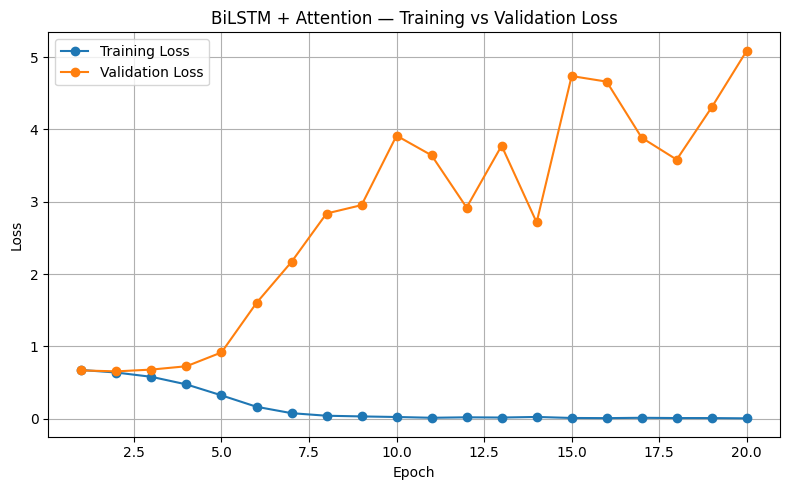

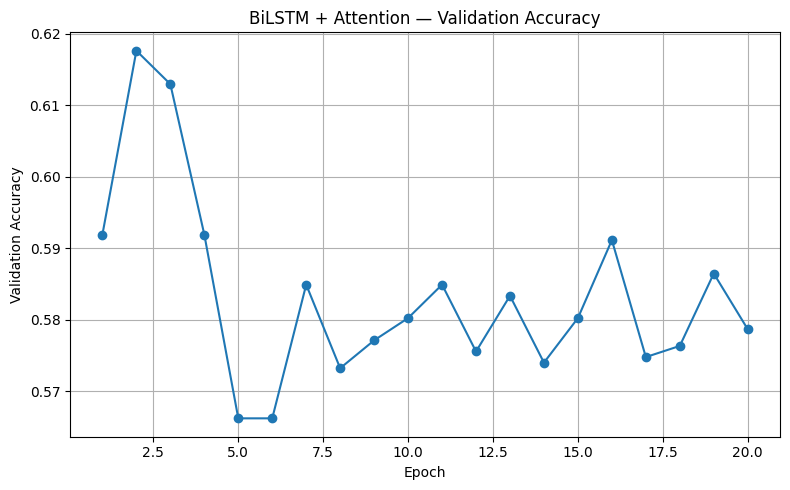

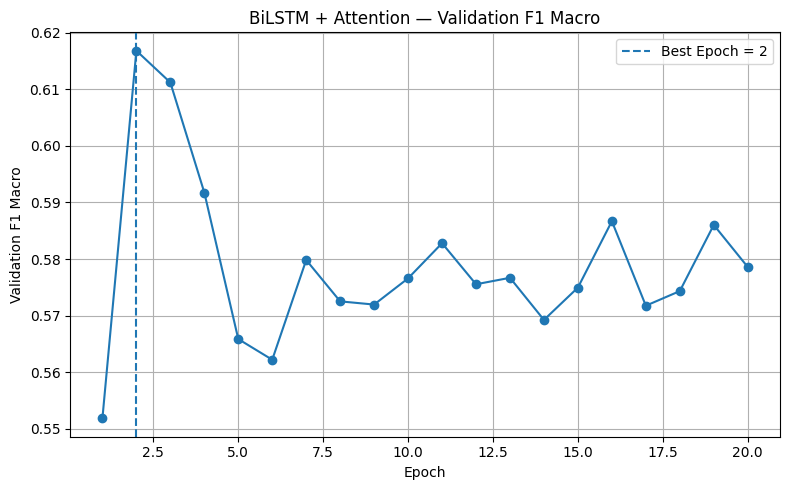

In [ ]:
# ============================================================
# 12.12 BiLSTM — LEARNING CURVES
# ============================================================

# This section:
# 1. Plots Training Loss against Validation Loss.
# 2. Plots Validation Accuracy across epochs.
# 3. Plots Validation F1 Macro across epochs.
# 4. Helps identify overfitting and the best training epoch.


# ============================================================
# PREPARE EPOCH NUMBERS
# ============================================================

# Create epoch numbers for the x-axis.
bilstm_epoch_numbers = range(
    1,
    len(bilstm_training_history["train_loss"]) + 1
)


# ============================================================
# 1. TRAINING LOSS VS VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    bilstm_epoch_numbers,
    bilstm_training_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    bilstm_epoch_numbers,
    bilstm_training_history["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "BiLSTM + Attention — Training vs Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 2. VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    bilstm_epoch_numbers,
    bilstm_training_history["validation_accuracy"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.title(
    "BiLSTM + Attention — Validation Accuracy"
)

plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 3. VALIDATION F1 MACRO
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    bilstm_epoch_numbers,
    bilstm_training_history["validation_f1_macro"],
    marker="o"
)

# Mark the best Validation F1 Macro epoch.
plt.axvline(
    bilstm_best_epoch,
    linestyle="--",
    label=f"Best Epoch = {bilstm_best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Validation F1 Macro")

plt.title(
    "BiLSTM + Attention — Validation F1 Macro"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 12.13 SAVE BiLSTM TRAINING RESULTS
# ============================================================

# This section:
# 1. Saves the BiLSTM training history.
# 2. Saves the best epoch information.
# 3. Saves the best Validation F1 Macro.
# 4. Saves the Validation evaluation results.
# 5. Keeps the results available for final model comparison.

import pickle


# ------------------------------------------------------------
# Save training history
# ------------------------------------------------------------

bilstm_history_path = "bilstm_attention_training_history.pkl"

with open(
    bilstm_history_path,
    "wb"
) as bilstm_history_file:

    pickle.dump(
        bilstm_training_history,
        bilstm_history_file
    )


# ------------------------------------------------------------
# Save BiLSTM evaluation results
# ------------------------------------------------------------

bilstm_results = {
    "model": "BiLSTM + Attention",
    "best_epoch": bilstm_best_epoch,
    "best_validation_f1_macro": bilstm_best_validation_f1,
    "validation_accuracy": bilstm_validation_accuracy,
    "validation_precision_fake": bilstm_validation_precision,
    "validation_recall_fake": bilstm_validation_recall,
    "validation_f1_fake": bilstm_validation_f1,
    "validation_f1_macro": bilstm_validation_f1_macro
}


bilstm_results_path = "bilstm_attention_validation_results.pkl"

with open(
    bilstm_results_path,
    "wb"
) as bilstm_results_file:

    pickle.dump(
        bilstm_results,
        bilstm_results_file
    )


# ------------------------------------------------------------
# Display saved information
# ------------------------------------------------------------

print("=" * 80)
print("BiLSTM RESULTS SAVED")
print("=" * 80)

print(
    "Training history :",
    bilstm_history_path
)

print(
    "Validation results:",
    bilstm_results_path
)

print(
    f"Best epoch        : {bilstm_best_epoch}"
)

print(
    f"Best Validation F1: "
    f"{bilstm_best_validation_f1:.4f}"
)

BiLSTM RESULTS SAVED
Training history : bilstm_attention_training_history.pkl
Validation results: bilstm_attention_validation_results.pkl
Best epoch        : 2
Best Validation F1: 0.6168


## 13. BERT

                 P22 — BERT FAKE NEWS CLASSIFICATION
                 ===================================

                         NEWS STATEMENT
                              │
                              ▼
                ┌─────────────────────────┐
                │       TOKENIZER         │
                │  bert-base-uncased     │
                └────────────┬────────────┘
                             │
                             ▼
                   Convert text to IDs
                             │
                             ▼
             ┌──────────────────────────────┐
             │       MAX LENGTH = 128       │
             │                              │
             │  Token 1                     │
             │  Token 2                     │
             │  Token 3                     │
             │      ...                     │
             │  Token 128                   │
             └──────────────┬───────────────┘
                            │
                 Padding / Truncation
                            │
                            ▼
                    128 TOKEN POSITIONS
                            │
                            ▼
             ┌──────────────────────────────┐
             │       BERT MODEL             │
             │                              │
             │  Each token → 768 numbers   │
             │                              │
             │  128 × 768 representation   │
             └──────────────┬───────────────┘
                            │
                            ▼
             ┌──────────────────────────────┐
             │   12 TRANSFORMER LAYERS      │
             │                              │
             │   Self-Attention             │
             │        ↓                     │
             │   Feed Forward               │
             │        ↓                     │
             │   Layer Normalization        │
             │        ↓                     │
             │   ...                         │
             └──────────────┬───────────────┘
                            │
                            ▼
                 CONTEXTUAL BERT OUTPUT
                            │
                      768-dimensional
                      representation
                            │
                            ▼
             ┌──────────────────────────────┐
             │       CLASSIFIER             │
             │                              │
             │      768  →  2               │
             └──────────────┬───────────────┘
                            │
                       2 output values
                       /           \
                      ▼             ▼
                   REAL            FAKE

In [ ]:
# ============================================================
# 13.1 BERT — IMPORTS AND CONFIGURATION
# ============================================================

# This section:
# 1. Imports the libraries required for BERT.
# 2. Loads the BERT tokenizer.
# 3. Defines the maximum sequence length.
# 4. Defines the BERT model name.
# 5. Displays the BERT configuration.


import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)


# ------------------------------------------------------------
# BERT configuration
# ------------------------------------------------------------

# Pre-trained BERT model that will be used for classification.
BERT_MODEL_NAME = "bert-base-uncased"


# Maximum number of tokens allowed for each statement.
BERT_MAX_LENGTH = 128


# Number of output classes.
# 0 = FAKE
# 1 = REAL
BERT_NUM_LABELS = 2


# ------------------------------------------------------------
# Load BERT tokenizer
# ------------------------------------------------------------

# The tokenizer converts raw text into BERT token IDs.
bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_MODEL_NAME
)


# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 80)
print("BERT CONFIGURATION")
print("=" * 80)

print(
    "Model name      :",
    BERT_MODEL_NAME
)

print(
    "Maximum length  :",
    BERT_MAX_LENGTH
)

print(
    "Number of labels:",
    BERT_NUM_LABELS
)

print(
    "Tokenizer       :",
    bert_tokenizer.__class__.__name__
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT CONFIGURATION
Model name      : bert-base-uncased
Maximum length  : 128
Number of labels: 2
Tokenizer       : BertTokenizer


In [ ]:
# ============================================================
# 13.2 BERT — TOKENIZATION
# ============================================================

# This section:
# 1. Takes the original statements from the Train, Validation,
#    and Test DataFrames.
# 2. Uses the pre-trained BERT tokenizer.
# 3. Converts statements into BERT input IDs.
# 4. Creates attention masks.
# 5. Pads each statement to 128 tokens.
# 6. Truncates statements longer than 128 tokens.
# 7. Displays the resulting shapes and one example.


# ------------------------------------------------------------
# Extract original statements
# ------------------------------------------------------------


# Load the processed training dataset.
bert_train_df = pd.read_csv(
    TRAIN_PROCESSED_PATH
)

# Load the processed validation dataset.
bert_validation_df = pd.read_csv(
    VALIDATION_PROCESSED_PATH
)

# Load the processed test dataset.
bert_test_df = pd.read_csv(
    TEST_PROCESSED_PATH
)


# Use the original statement column.
# BERT performs its own tokenization.
bert_train_text = (
    bert_train_df["statement"]
    .astype(str)
    .tolist()
)

bert_validation_text = (
    bert_validation_df["statement"]
    .astype(str)
    .tolist()
)

bert_test_text = (
    bert_test_df["statement"]
    .astype(str)
    .tolist()
)


# ------------------------------------------------------------
# Tokenize Training statements
# ------------------------------------------------------------

# input_ids      = numerical IDs representing BERT tokens
# attention_mask = 1 for real tokens and 0 for padding
bert_train_tokens = bert_tokenizer(
    bert_train_text,
    padding="max_length",
    truncation=True,
    max_length=BERT_MAX_LENGTH,
    return_tensors="pt"
)


# ------------------------------------------------------------
# Tokenize Validation statements
# ------------------------------------------------------------

bert_validation_tokens = bert_tokenizer(
    bert_validation_text,
    padding="max_length",
    truncation=True,
    max_length=BERT_MAX_LENGTH,
    return_tensors="pt"
)


# ------------------------------------------------------------
# Tokenize Test statements
# ------------------------------------------------------------

bert_test_tokens = bert_tokenizer(
    bert_test_text,
    padding="max_length",
    truncation=True,
    max_length=BERT_MAX_LENGTH,
    return_tensors="pt"
)


# ------------------------------------------------------------
# Display tokenization shapes
# ------------------------------------------------------------

print("=" * 80)
print("BERT TOKENIZATION")
print("=" * 80)

print(
    "Train input_ids shape      :",
    bert_train_tokens["input_ids"].shape
)

print(
    "Validation input_ids shape :",
    bert_validation_tokens["input_ids"].shape
)

print(
    "Test input_ids shape       :",
    bert_test_tokens["input_ids"].shape
)

print(
    "Train attention_mask shape :",
    bert_train_tokens["attention_mask"].shape
)


# ------------------------------------------------------------
# Display one tokenization example
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BERT TOKENIZATION EXAMPLE")
print("=" * 80)

print("Original statement:")
print(bert_train_text[0])

print("\nToken IDs:")
print(bert_train_tokens["input_ids"][0])

print("\nAttention mask:")
print(bert_train_tokens["attention_mask"][0])

BERT TOKENIZATION
Train input_ids shape      : torch.Size([10240, 128])
Validation input_ids shape : torch.Size([1284, 128])
Test input_ids shape       : torch.Size([1267, 128])
Train attention_mask shape : torch.Size([10240, 128])

BERT TOKENIZATION EXAMPLE
Original statement:
Says the Annies List political group supports third-trimester abortions on demand.

Token IDs:
tensor([  101,  2758,  1996,  8194,  2015,  2862,  2576,  2177,  6753,  2353,
         1011, 12241, 20367, 11324,  2015,  2006,  5157,  1012,   102,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
  

In [ ]:
# ============================================================
# P22 BERT VOCABULARY USAGE ANALYSIS
# ============================================================

print("=" * 80)
print("P22 BERT VOCABULARY USAGE")
print("=" * 80)


# ------------------------------------------------------------
# Get pretrained BERT vocabulary
# ------------------------------------------------------------

bert_vocabulary = bert_tokenizer.get_vocab()

bert_vocabulary_size = len(bert_vocabulary)

print(
    f"\nPretrained BERT vocabulary size: "
    f"{bert_vocabulary_size:,}"
)


# ------------------------------------------------------------
# Function to calculate vocabulary usage
# ------------------------------------------------------------

def calculate_bert_vocab_usage(text_list):

    tokenized_output = bert_tokenizer(
        text_list,
        add_special_tokens=False,
        truncation=False
    )

    unique_token_ids = set()

    for token_ids in tokenized_output["input_ids"]:
        unique_token_ids.update(token_ids)

    unique_tokens_used = len(unique_token_ids)

    coverage_percent = (
        unique_tokens_used /
        bert_vocabulary_size
    ) * 100

    return unique_tokens_used, coverage_percent


# ------------------------------------------------------------
# Calculate usage for each P22 split
# ------------------------------------------------------------

bert_vocab_results = []


for split_name, text_data in [
    ("TRAIN", bert_train_text),
    ("VALIDATION", bert_validation_text),
    ("TEST", bert_test_text)
]:

    unique_tokens_used, coverage_percent = (
        calculate_bert_vocab_usage(text_data)
    )

    bert_vocab_results.append({
        "dataset_split": split_name,
        "pretrained_vocab_size": bert_vocabulary_size,
        "unique_tokens_used": unique_tokens_used,
        "vocabulary_coverage_percent": coverage_percent
    })


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

bert_vocab_usage_df = pd.DataFrame(
    bert_vocab_results
)

display(bert_vocab_usage_df)


# ------------------------------------------------------------
# Explanation
# ------------------------------------------------------------

print("\nInterpretation:")
print(
    "The pretrained bert-base-uncased vocabulary contains "
    f"{bert_vocabulary_size:,} tokens."
)

print(
    "The unique_tokens_used value shows how many of those "
    "pretrained BERT tokens occur in each P22 dataset split."
)

print(
    "Vocabulary coverage represents the percentage of the "
    "pretrained BERT vocabulary used by each split."
)

P22 BERT VOCABULARY USAGE

Pretrained BERT vocabulary size: 30,522


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (712 > 512). Running this sequence through the model will result in indexing errors


,dataset_split,pretrained_vocab_size,unique_tokens_used,vocabulary_coverage_percent
0,TRAIN,30522,11172,36.603106
1,VALIDATION,30522,4571,14.976083
2,TEST,30522,4587,15.028504



Interpretation:
The pretrained bert-base-uncased vocabulary contains 30,522 tokens.
The unique_tokens_used value shows how many of those pretrained BERT tokens occur in each P22 dataset split.
Vocabulary coverage represents the percentage of the pretrained BERT vocabulary used by each split.


In [ ]:
# ============================================================
# 13.3 BERT — LABELS AND PYTORCH DATALOADERS
# ============================================================

# This section:
# 1. Extracts the FAKE/REAL labels for Train, Validation, and Test.
# 2. Converts labels into PyTorch tensors.
# 3. Combines input_ids, attention_mask, and labels into datasets.
# 4. Creates DataLoaders for batch-based BERT training.
# 5. Verifies the number of samples and batches.


from torch.utils.data import TensorDataset, DataLoader


# ------------------------------------------------------------
# Extract and encode labels
# ------------------------------------------------------------

# BERT requires numerical class labels.
# FAKE = 0
# REAL = 1
bert_label_mapping = {
    "FAKE": 0,
    "REAL": 1
}


# Convert Training labels from text to integers.
bert_train_labels = torch.tensor(
    bert_train_df["binary_label"]
    .map(bert_label_mapping)
    .values,
    dtype=torch.long
)


# Convert Validation labels from text to integers.
bert_validation_labels = torch.tensor(
    bert_validation_df["binary_label"]
    .map(bert_label_mapping)
    .values,
    dtype=torch.long
)


# Convert Test labels from text to integers.
bert_test_labels = torch.tensor(
    bert_test_df["binary_label"]
    .map(bert_label_mapping)
    .values,
    dtype=torch.long
)

# ------------------------------------------------------------
# Create PyTorch datasets
# ------------------------------------------------------------

# Each sample contains:
# input_ids + attention_mask + label
bert_train_dataset = TensorDataset(
    bert_train_tokens["input_ids"],
    bert_train_tokens["attention_mask"],
    bert_train_labels
)

bert_validation_dataset = TensorDataset(
    bert_validation_tokens["input_ids"],
    bert_validation_tokens["attention_mask"],
    bert_validation_labels
)

bert_test_dataset = TensorDataset(
    bert_test_tokens["input_ids"],
    bert_test_tokens["attention_mask"],
    bert_test_labels
)


# ------------------------------------------------------------
# BERT batch size
# ------------------------------------------------------------

# BERT requires more memory than our classical ML models,
# so we use a manageable batch size.
BERT_BATCH_SIZE = 16


# ------------------------------------------------------------
# Create DataLoaders
# ------------------------------------------------------------

# shuffle=True means the training samples are shuffled
# between epochs.
bert_train_loader = DataLoader(
    bert_train_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=True
)

# Validation and Test data do not need to be shuffled.
bert_validation_loader = DataLoader(
    bert_validation_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)

bert_test_loader = DataLoader(
    bert_test_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)


# ------------------------------------------------------------
# Display dataset information
# ------------------------------------------------------------

print("=" * 80)
print("BERT DATASET AND DATALOADER VERIFICATION")
print("=" * 80)

print(
    "Training samples   :",
    len(bert_train_dataset)
)

print(
    "Validation samples :",
    len(bert_validation_dataset)
)

print(
    "Test samples       :",
    len(bert_test_dataset)
)

print(
    "Batch size         :",
    BERT_BATCH_SIZE
)

print(
    "Training batches   :",
    len(bert_train_loader)
)

print(
    "Validation batches :",
    len(bert_validation_loader)
)

print(
    "Test batches       :",
    len(bert_test_loader)
)


# ------------------------------------------------------------
# Verify one training batch
# ------------------------------------------------------------

bert_sample_input_ids, bert_sample_attention_mask, bert_sample_labels = next(
    iter(bert_train_loader)
)

print("\n" + "=" * 80)
print("BERT BATCH VERIFICATION")
print("=" * 80)

print(
    "Input IDs shape      :",
    bert_sample_input_ids.shape
)

print(
    "Attention mask shape :",
    bert_sample_attention_mask.shape
)

print(
    "Labels shape         :",
    bert_sample_labels.shape
)

BERT DATASET AND DATALOADER VERIFICATION
Training samples   : 10240
Validation samples : 1284
Test samples       : 1267
Batch size         : 16
Training batches   : 640
Validation batches : 81
Test batches       : 80

BERT BATCH VERIFICATION
Input IDs shape      : torch.Size([16, 128])
Attention mask shape : torch.Size([16, 128])
Labels shape         : torch.Size([16])


In [ ]:
# ============================================================
# 13.4 BERT — LOAD PRE-TRAINED MODEL
# ============================================================

# This section:
# 1. Loads the pre-trained bert-base-uncased model.
# 2. Adds a classification layer for our FAKE/REAL task.
# 3. Configures BERT to output two classes.
# 4. Moves the model to the available device (CPU/GPU).
# 5. Verifies the model configuration.


# ------------------------------------------------------------
# Select computation device
# ------------------------------------------------------------

# Use GPU if CUDA is available; otherwise use CPU.
bert_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ------------------------------------------------------------
# Load pre-trained BERT for classification
# ------------------------------------------------------------

# bert-base-uncased is already pre-trained on large amounts
# of text. We add a classification head for our two classes.
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=BERT_NUM_LABELS
)


# ------------------------------------------------------------
# Move model to selected device
# ------------------------------------------------------------

bert_model = bert_model.to(
    bert_device
)


# ------------------------------------------------------------
# Display model configuration
# ------------------------------------------------------------

print("=" * 80)
print("BERT MODEL CONFIGURATION")
print("=" * 80)

print(
    "Model name       :",
    BERT_MODEL_NAME
)

print(
    "Number of labels :",
    BERT_NUM_LABELS
)

print(
    "Device            :",
    bert_device
)

print("\nModel:")
print(bert_model)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT MODEL CONFIGURATION
Model name       : bert-base-uncased
Number of labels : 2
Device            : cuda

Model:
BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (

In [ ]:
# ============================================================
# 13.5 BERT — OPTIMIZER AND LINEAR WARMUP SCHEDULER
# ============================================================

# This section:
# 1. Defines the BERT training epochs.
# 2. Defines the learning rate.
# 3. Creates the AdamW optimizer.
# 4. Calculates the total number of training steps.
# 5. Creates a linear warmup learning-rate scheduler.
# 6. Displays the training configuration.


from transformers import get_linear_schedule_with_warmup


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

# Number of complete passes through the training dataset.
BERT_EPOCHS = 5

# Small learning rate commonly used when fine-tuning BERT.
BERT_LEARNING_RATE = 2e-5


# ------------------------------------------------------------
# Create AdamW optimizer
# ------------------------------------------------------------

# AdamW updates the trainable BERT parameters during fine-tuning.
bert_optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=BERT_LEARNING_RATE
)


# ------------------------------------------------------------
# Calculate training steps
# ------------------------------------------------------------

# One training step occurs after processing one batch.
bert_total_training_steps = (
    len(bert_train_loader) * BERT_EPOCHS  #Total training steps: 640 × 5 = 3200
)


# ------------------------------------------------------------
# Calculate warmup steps
# ------------------------------------------------------------

# Use 10% of the total training steps for learning-rate warmup.
bert_warmup_steps = int(
    0.1 * bert_total_training_steps
)


# ------------------------------------------------------------
# Create linear warmup scheduler
# ------------------------------------------------------------

# Learning rate:
# 1. Starts low.
# 2. Gradually increases during warmup.
# 3. Then gradually decreases toward the end of training.
bert_scheduler = get_linear_schedule_with_warmup(
    bert_optimizer,
    num_warmup_steps=bert_warmup_steps,
    num_training_steps=bert_total_training_steps
)


# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 80)
print("BERT TRAINING CONFIGURATION")
print("=" * 80)

print(
    "Epochs              :",
    BERT_EPOCHS
)

print(
    "Batch size          :",
    BERT_BATCH_SIZE
)

print(
    "Learning rate       :",
    BERT_LEARNING_RATE
)

print(
    "Total training steps:",
    bert_total_training_steps
)

print(
    "Warmup steps        :",
    bert_warmup_steps
)

print(
    "Optimizer           :",
    type(bert_optimizer).__name__
)

print(
    "Scheduler           :",
    "Linear Warmup + Linear Decay"
)

print(
    "Device              :",
    bert_device
)

BERT TRAINING CONFIGURATION
Epochs              : 5
Batch size          : 16
Learning rate       : 2e-05
Total training steps: 3200
Warmup steps        : 320
Optimizer           : AdamW
Scheduler           : Linear Warmup + Linear Decay
Device              : cuda


In [ ]:
# ============================================================
# 13.6 BERT — FINE-TUNING TRAINING LOOP
# ============================================================

# This section:
# 1. Trains BERT for the configured number of epochs.
# 2. Performs forward propagation on each training batch.
# 3. Calculates the classification loss.
# 4. Performs backpropagation.
# 5. Updates BERT weights using AdamW.
# 6. Updates the learning rate using the linear scheduler.
# 7. Evaluates BERT on the Validation dataset after each epoch.
# 8. Tracks Validation F1 Macro.
# 9. Saves the model whenever it achieves a new best Validation F1.
# 10. Keeps the best BERT model for later evaluation and deployment.


from sklearn.metrics import accuracy_score, f1_score
import copy
import os


# ------------------------------------------------------------
# Best-model tracking
# ------------------------------------------------------------

# Store the best validation F1 achieved during training.
bert_best_validation_f1 = 0.0

# Store the epoch that produced the best validation F1.
bert_best_epoch = 0

# Keep a copy of the best model weights.
bert_best_model_state = None


# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

# Store training and validation results for every epoch.
bert_training_history = []


# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------

for bert_epoch in range(BERT_EPOCHS):

    # Put BERT into training mode.
    bert_model.train()

    # Track total training loss for this epoch.
    bert_epoch_training_loss = 0.0


    # --------------------------------------------------------
    # Training batches
    # --------------------------------------------------------

    for (
        bert_batch_input_ids,
        bert_batch_attention_mask,
        bert_batch_labels
    ) in bert_train_loader:

        # Move the current batch to the GPU/CPU.
        bert_batch_input_ids = bert_batch_input_ids.to(
            bert_device
        )

        bert_batch_attention_mask = bert_batch_attention_mask.to(
            bert_device
        )

        bert_batch_labels = bert_batch_labels.to(
            bert_device
        )


        # Clear gradients from the previous batch.
        bert_optimizer.zero_grad()


        # Forward pass through BERT.
        bert_outputs = bert_model(
            input_ids=bert_batch_input_ids,
            attention_mask=bert_batch_attention_mask,
            labels=bert_batch_labels
        )


        # Get the classification loss calculated by BERT.
        bert_loss = bert_outputs.loss


        # Backpropagation.
        bert_loss.backward()


        # Update BERT parameters.
        bert_optimizer.step()


        # Update the learning rate according to the schedule.
        bert_scheduler.step()


        # Add this batch's loss to the epoch total.
        bert_epoch_training_loss += bert_loss.item()


    # --------------------------------------------------------
    # Average training loss
    # --------------------------------------------------------

    bert_average_training_loss = (
        bert_epoch_training_loss
        / len(bert_train_loader)
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    # Put BERT into evaluation mode.
    bert_model.eval()

    bert_validation_predictions = []
    bert_validation_true_labels = []

    bert_validation_loss = 0.0


    # No gradients are required during validation.
    with torch.no_grad():

        for (
            bert_batch_input_ids,
            bert_batch_attention_mask,
            bert_batch_labels
        ) in bert_validation_loader:

            # Move validation batch to the selected device.
            bert_batch_input_ids = bert_batch_input_ids.to(
                bert_device
            )

            bert_batch_attention_mask = bert_batch_attention_mask.to(
                bert_device
            )

            bert_batch_labels = bert_batch_labels.to(
                bert_device
            )


            # Forward pass through the fine-tuned BERT model.
            bert_outputs = bert_model(
                input_ids=bert_batch_input_ids,
                attention_mask=bert_batch_attention_mask,
                labels=bert_batch_labels
            )


            # Accumulate validation loss.
            bert_validation_loss += bert_outputs.loss.item()


            # Select the class with the highest output score.
            bert_batch_predictions = torch.argmax(
                bert_outputs.logits,
                dim=1
            )


            # Store predictions and actual labels.
            bert_validation_predictions.extend(
                bert_batch_predictions.cpu().numpy()
            )

            bert_validation_true_labels.extend(
                bert_batch_labels.cpu().numpy()
            )


    # --------------------------------------------------------
    # Validation metrics
    # --------------------------------------------------------

    bert_average_validation_loss = (
        bert_validation_loss
        / len(bert_validation_loader)
    )

    bert_validation_accuracy = accuracy_score(
        bert_validation_true_labels,
        bert_validation_predictions
    )

    bert_validation_f1_macro = f1_score(
        bert_validation_true_labels,
        bert_validation_predictions,
        average="macro"
    )


    # --------------------------------------------------------
    # Save epoch history
    # --------------------------------------------------------

    bert_training_history.append(
        {
            "epoch": bert_epoch + 1,
            "train_loss": bert_average_training_loss,
            "validation_loss": bert_average_validation_loss,
            "validation_accuracy": bert_validation_accuracy,
            "validation_f1_macro": bert_validation_f1_macro
        }
    )


    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if bert_validation_f1_macro > bert_best_validation_f1:

        # Update the best validation score.
        bert_best_validation_f1 = bert_validation_f1_macro

        # Record the best epoch.
        bert_best_epoch = bert_epoch + 1

        # Save a copy of the best model weights.
        bert_best_model_state = copy.deepcopy(
            bert_model.state_dict()
        )


    # --------------------------------------------------------
    # Display epoch results
    # --------------------------------------------------------

    print(
        f"Epoch {bert_epoch + 1:02d}/{BERT_EPOCHS} | "
        f"Train Loss: {bert_average_training_loss:.4f} | "
        f"Val Loss: {bert_average_validation_loss:.4f} | "
        f"Val Accuracy: {bert_validation_accuracy:.4f} | "
        f"Val F1 Macro: {bert_validation_f1_macro:.4f}"
    )


# ------------------------------------------------------------
# Restore the best model
# ------------------------------------------------------------

# After all epochs, restore the weights from the epoch
# that achieved the highest Validation F1 Macro.
bert_model.load_state_dict(
    bert_best_model_state
)


# ------------------------------------------------------------
# Training completion
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BERT TRAINING COMPLETE")
print("=" * 80)

print(
    "Best Epoch           :",
    bert_best_epoch
)

print(
    f"Best Validation F1   : "
    f"{bert_best_validation_f1:.4f}"
)

Epoch 01/5 | Train Loss: 0.6765 | Val Loss: 0.6558 | Val Accuracy: 0.6301 | Val F1 Macro: 0.6183
Epoch 02/5 | Train Loss: 0.6257 | Val Loss: 0.6489 | Val Accuracy: 0.6308 | Val F1 Macro: 0.6132
Epoch 03/5 | Train Loss: 0.5129 | Val Loss: 0.7410 | Val Accuracy: 0.6262 | Val F1 Macro: 0.6224
Epoch 04/5 | Train Loss: 0.3055 | Val Loss: 0.9378 | Val Accuracy: 0.6199 | Val F1 Macro: 0.6169
Epoch 05/5 | Train Loss: 0.1612 | Val Loss: 1.1858 | Val Accuracy: 0.6145 | Val F1 Macro: 0.6111

BERT TRAINING COMPLETE
Best Epoch           : 3
Best Validation F1   : 0.6224


BERT — VALIDATION PERFORMANCE
Accuracy       : 0.6262
Precision FAKE : 0.6259
Recall FAKE    : 0.5487
F1 FAKE        : 0.5848
F1 Macro       : 0.6224

BERT — CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.63      0.55      0.58       616
        REAL       0.63      0.70      0.66       668

    accuracy                           0.63      1284
   macro avg       0.63      0.62      0.62      1284
weighted avg       0.63      0.63      0.62      1284


BERT — CONFUSION MATRIX
[[338 278]
 [202 466]]


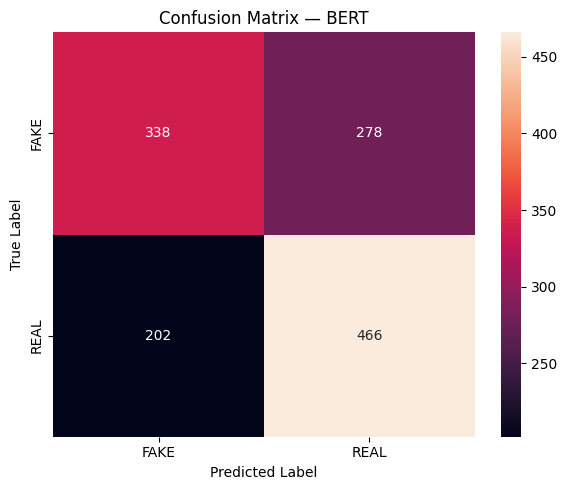

In [ ]:
# ============================================================
# 13.7 BERT — VALIDATION EVALUATION
# ============================================================

# This section:
# 1. Uses the best BERT model selected during training.
# 2. Generates predictions on the Validation dataset.
# 3. Calculates Accuracy, Precision, Recall, F1, and Macro F1.
# 4. Displays the classification report.
# 5. Displays the Validation confusion matrix.


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ------------------------------------------------------------
# Put the best BERT model into evaluation mode.
# ------------------------------------------------------------

bert_model.eval()


# Lists for storing predictions and true labels.
bert_final_validation_predictions = []
bert_final_validation_true_labels = []


# ------------------------------------------------------------
# Generate Validation predictions
# ------------------------------------------------------------

# No gradients are required during evaluation.
with torch.no_grad():

    for (
        bert_batch_input_ids,
        bert_batch_attention_mask,
        bert_batch_labels
    ) in bert_validation_loader:

        # Move the batch to the selected device.
        bert_batch_input_ids = bert_batch_input_ids.to(
            bert_device
        )

        bert_batch_attention_mask = bert_batch_attention_mask.to(
            bert_device
        )

        bert_batch_labels = bert_batch_labels.to(
            bert_device
        )


        # Pass the Validation batch through BERT.
        bert_outputs = bert_model(
            input_ids=bert_batch_input_ids,
            attention_mask=bert_batch_attention_mask
        )


        # Select the class with the highest output score.
        bert_batch_predictions = torch.argmax(
            bert_outputs.logits,
            dim=1
        )


        # Store predictions and actual labels on CPU.
        bert_final_validation_predictions.extend(
            bert_batch_predictions.cpu().numpy()
        )

        bert_final_validation_true_labels.extend(
            bert_batch_labels.cpu().numpy()
        )


# ------------------------------------------------------------
# Calculate Validation metrics
# ------------------------------------------------------------

bert_validation_accuracy = accuracy_score(
    bert_final_validation_true_labels,
    bert_final_validation_predictions
)

bert_validation_precision_fake = precision_score(
    bert_final_validation_true_labels,
    bert_final_validation_predictions,
    pos_label=0
)

bert_validation_recall_fake = recall_score(
    bert_final_validation_true_labels,
    bert_final_validation_predictions,
    pos_label=0
)

bert_validation_f1_fake = f1_score(
    bert_final_validation_true_labels,
    bert_final_validation_predictions,
    pos_label=0
)

bert_validation_f1_macro = f1_score(
    bert_final_validation_true_labels,
    bert_final_validation_predictions,
    average="macro"
)


# ------------------------------------------------------------
# Display Validation performance
# ------------------------------------------------------------

print("=" * 80)
print("BERT — VALIDATION PERFORMANCE")
print("=" * 80)

print(
    f"Accuracy       : "
    f"{bert_validation_accuracy:.4f}"
)

print(
    f"Precision FAKE : "
    f"{bert_validation_precision_fake:.4f}"
)

print(
    f"Recall FAKE    : "
    f"{bert_validation_recall_fake:.4f}"
)

print(
    f"F1 FAKE        : "
    f"{bert_validation_f1_fake:.4f}"
)

print(
    f"F1 Macro       : "
    f"{bert_validation_f1_macro:.4f}"
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BERT — CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        bert_final_validation_true_labels,
        bert_final_validation_predictions,
        target_names=["FAKE", "REAL"]
    )
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

bert_validation_confusion_matrix = confusion_matrix(
    bert_final_validation_true_labels,
    bert_final_validation_predictions,
    labels=[0, 1]
)


print("\n" + "=" * 80)
print("BERT — CONFUSION MATRIX")
print("=" * 80)

print(
    bert_validation_confusion_matrix
)


# ------------------------------------------------------------
# Plot confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

sns.heatmap(
    bert_validation_confusion_matrix,
    annot=True,
    fmt="d",
    xticklabels=["FAKE", "REAL"],
    yticklabels=["FAKE", "REAL"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "Confusion Matrix — BERT"
)

plt.tight_layout()
plt.show()

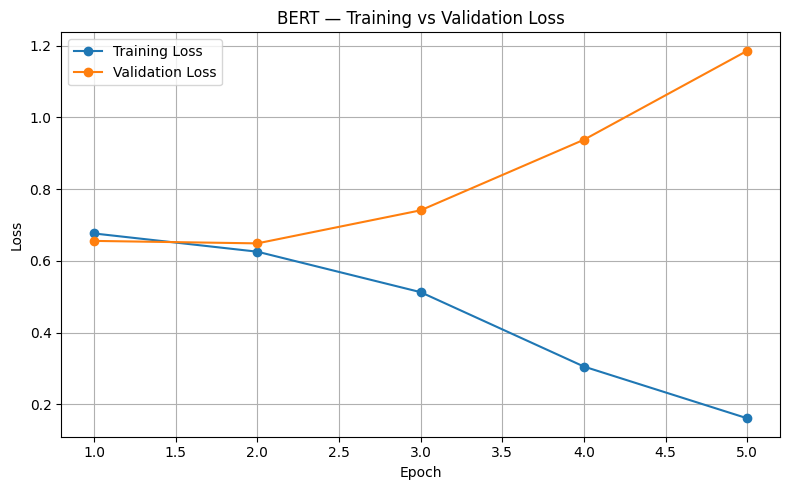

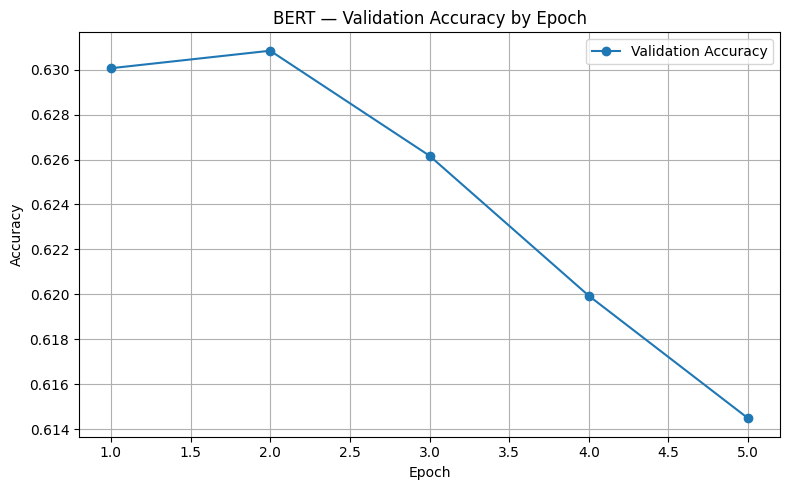

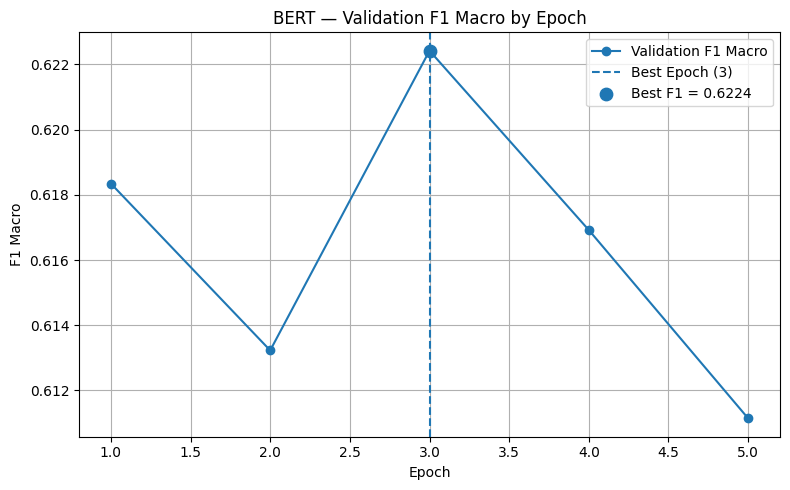

In [ ]:
# ============================================================
# 13.8 BERT — LEARNING CURVES
# ============================================================

# This section:
# 1. Uses the training history collected during BERT training.
# 2. Plots Training Loss and Validation Loss across epochs.
# 3. Plots Validation Accuracy across epochs.
# 4. Plots Validation F1 Macro across epochs.
# 5. Helps us identify overfitting and the best training epoch.


import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Extract values from BERT training history
# ------------------------------------------------------------

# Extract the epoch numbers.
bert_history_epochs = [
    record["epoch"]
    for record in bert_training_history
]

# Extract Training Loss for each epoch.
bert_history_train_loss = [
    record["train_loss"]
    for record in bert_training_history
]

# Extract Validation Loss for each epoch.
bert_history_validation_loss = [
    record["validation_loss"]
    for record in bert_training_history
]

# Extract Validation Accuracy for each epoch.
bert_history_validation_accuracy = [
    record["validation_accuracy"]
    for record in bert_training_history
]

# Extract Validation F1 Macro for each epoch.
bert_history_validation_f1 = [
    record["validation_f1_macro"]
    for record in bert_training_history
]


# ============================================================
# 1. LOSS CURVE
# ============================================================

# This plot compares Training Loss with Validation Loss.
plt.figure(figsize=(8, 5))

plt.plot(
    bert_history_epochs,
    bert_history_train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    bert_history_epochs,
    bert_history_validation_loss,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "BERT — Training vs Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 2. VALIDATION ACCURACY CURVE
# ============================================================

# This plot shows how Validation Accuracy changes across epochs.
plt.figure(figsize=(8, 5))

plt.plot(
    bert_history_epochs,
    bert_history_validation_accuracy,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "BERT — Validation Accuracy by Epoch"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 3. VALIDATION F1 MACRO CURVE
# ============================================================

# This plot shows how Validation F1 Macro changes across epochs.
plt.figure(figsize=(8, 5))

plt.plot(
    bert_history_epochs,
    bert_history_validation_f1,
    marker="o",
    label="Validation F1 Macro"
)

# Mark the best Validation F1 Macro epoch.
plt.axvline(
    x=bert_best_epoch,
    linestyle="--",
    label=f"Best Epoch ({bert_best_epoch})"
)

# Mark the best F1 Macro value.
plt.scatter(
    bert_best_epoch,
    bert_best_validation_f1,
    s=80,
    zorder=5,
    label=f"Best F1 = {bert_best_validation_f1:.4f}"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Macro")

plt.title(
    "BERT — Validation F1 Macro by Epoch"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 13.9 BERT — SAVE RESULTS IN COLAB
# ============================================================

# This section:
# 1. Creates a local BERT results folder in Colab.
# 2. Saves the best BERT validation metrics.
# 3. Saves the complete training history.
# 4. Saves the best epoch and best Validation F1.
# 5. Saves the Validation confusion matrix.
# 6. Saves the BERT training configuration.
# 7. Does NOT save anything to Google Drive yet.


import pickle
import os


# ------------------------------------------------------------
# Create local results folder
# ------------------------------------------------------------

# This folder exists only in the current Colab session.
BERT_LOCAL_RESULTS_DIR = "/content/bert_results"

os.makedirs(
    BERT_LOCAL_RESULTS_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Prepare BERT results
# ------------------------------------------------------------

bert_results = {

    # Best training information
    "best_epoch": bert_best_epoch,
    "best_validation_f1_macro": bert_best_validation_f1,

    # Validation performance
    "validation_accuracy": bert_validation_accuracy,
    "validation_precision_fake": bert_validation_precision_fake,
    "validation_recall_fake": bert_validation_recall_fake,
    "validation_f1_fake": bert_validation_f1_fake,
    "validation_f1_macro": bert_validation_f1_macro,

    # Validation confusion matrix
    "validation_confusion_matrix": bert_validation_confusion_matrix,

    # Complete training history
    "training_history": bert_training_history,

    # Model configuration
    "model_name": BERT_MODEL_NAME,
    "max_length": 128,
    "batch_size": BERT_BATCH_SIZE,
    "epochs": BERT_EPOCHS,
    "learning_rate": BERT_LEARNING_RATE,
    "warmup_steps": bert_warmup_steps,
    "total_training_steps": bert_total_training_steps,

    # Label mapping
    "label_mapping": {
        0: "FAKE",
        1: "REAL"
    }
}


# ------------------------------------------------------------
# Save BERT results
# ------------------------------------------------------------

BERT_LOCAL_RESULTS_PATH = os.path.join(
    BERT_LOCAL_RESULTS_DIR,
    "bert_results.pkl"
)

with open(
    BERT_LOCAL_RESULTS_PATH,
    "wb"
) as bert_results_file:

    pickle.dump(
        bert_results,
        bert_results_file
    )


# ------------------------------------------------------------
# Verify saved file
# ------------------------------------------------------------

print("=" * 80)
print("BERT RESULTS SAVED — COLAB")
print("=" * 80)

print(
    "Results folder :",
    BERT_LOCAL_RESULTS_DIR
)

print(
    "Results file   :",
    BERT_LOCAL_RESULTS_PATH
)

print(
    "Best Epoch     :",
    bert_best_epoch
)

print(
    f"Best Val F1    : "
    f"{bert_best_validation_f1:.4f}"
)

print(
    "File exists    :",
    os.path.exists(BERT_LOCAL_RESULTS_PATH)
)

BERT RESULTS SAVED — COLAB
Results folder : /content/bert_results
Results file   : /content/bert_results/bert_results.pkl
Best Epoch     : 3
Best Val F1    : 0.6224
File exists    : True


In [ ]:
# ============================================================
# ROC–AUC — VALIDATION SCORES FOR ALL 3 MODELS
# ============================================================

# This section:
# 1. Generates FAKE probability/score for the complete Validation dataset.
# 2. Uses the Logistic Regression model with TF-IDF + Engineered Features.
# 3. Uses the best BiLSTM + Attention model.
# 4. Uses the best BERT model.
# 5. Keeps the scores available for the combined ROC–AUC comparison.
#
# Label mapping:
# 0 = FAKE
# 1 = REAL


import numpy as np
import torch


# ============================================================
# 1. LOGISTIC REGRESSION
# ============================================================

# Logistic Regression produces probabilities for both classes.
# Generate FAKE probability for every Validation sample.
# Column 0 = FAKE
# Column 1 = REAL

tfidf_engineered_logreg_validation_probabilities = (
    tfidf_engineered_logreg_grid_search.predict_proba(
        tfidf_validation_combined
    )[:, 0]
)


# ============================================================
# 2. BiLSTM + ATTENTION
# ============================================================

# Load the best BiLSTM model state obtained during training.
bilstm_attention_model.load_state_dict(
    bilstm_best_state_dict
)

bilstm_attention_model.eval()


bilstm_validation_probabilities = []


with torch.no_grad():

    for (
        bilstm_batch_inputs,
        bilstm_batch_targets
    ) in bilstm_validation_loader:

        bilstm_batch_inputs = bilstm_batch_inputs.to(
            next(bilstm_attention_model.parameters()).device
        )

        bilstm_batch_outputs = bilstm_attention_model(
            bilstm_batch_inputs
        )

        # Convert logits into probabilities.
        # Sigmoid gives probability of class 1 (REAL).
        # Therefore 1 - probability gives probability of FAKE.
        bilstm_batch_real_probability = torch.sigmoid(
            bilstm_batch_outputs
        )

        bilstm_batch_fake_probability = (
            1 - bilstm_batch_real_probability
        )

        bilstm_validation_probabilities.extend(
            bilstm_batch_fake_probability.cpu().numpy().reshape(-1)
        )


bilstm_validation_probabilities = np.array(
    bilstm_validation_probabilities
)


# ============================================================
# 3. BERT
# ============================================================

# Load the best BERT model state obtained during training.
bert_model.load_state_dict(
    bert_best_model_state
)

bert_model.eval()


bert_validation_probabilities = []


with torch.no_grad():

    for (
        bert_batch_input_ids,
        bert_batch_attention_mask,
        bert_batch_labels
    ) in bert_validation_loader:

        bert_batch_input_ids = bert_batch_input_ids.to(
            bert_device
        )

        bert_batch_attention_mask = bert_batch_attention_mask.to(
            bert_device
        )

        bert_outputs = bert_model(
            input_ids=bert_batch_input_ids,
            attention_mask=bert_batch_attention_mask
        )

        # Convert BERT logits into class probabilities.
        bert_batch_probabilities = torch.softmax(
            bert_outputs.logits,
            dim=1
        )

        # Column 0 = FAKE probability.
        bert_batch_fake_probability = (
            bert_batch_probabilities[:, 0]
        )

        bert_validation_probabilities.extend(
            bert_batch_fake_probability.cpu().numpy()
        )


bert_validation_probabilities = np.array(
    bert_validation_probabilities
)


# ============================================================
# VERIFICATION
# ============================================================

print("=" * 80)
print("ROC–AUC VALIDATION SCORE VERIFICATION")
print("=" * 80)

print(
    "Validation samples :",
    len(tfidf_validation_y)
)

print(
    "Logistic Regression scores :",
    len(tfidf_engineered_logreg_validation_probabilities)
)

print(
    "BiLSTM scores              :",
    len(bilstm_validation_probabilities)
)

print(
    "BERT scores                :",
    len(bert_validation_probabilities)
)

print("\nExpected number of samples :", len(tfidf_validation_y))

ROC–AUC VALIDATION SCORE VERIFICATION
Validation samples : 1284
Logistic Regression scores : 1284
BiLSTM scores              : 1284
BERT scores                : 1284

Expected number of samples : 1284


ROC LABEL VERIFICATION
REAL (0) : 668
FAKE (1) : 616

ROC SCORE VERIFICATION
Validation samples       : 1284
Logistic Regression      : 1284
BiLSTM + Attention       : 1284
BERT                     : 1284


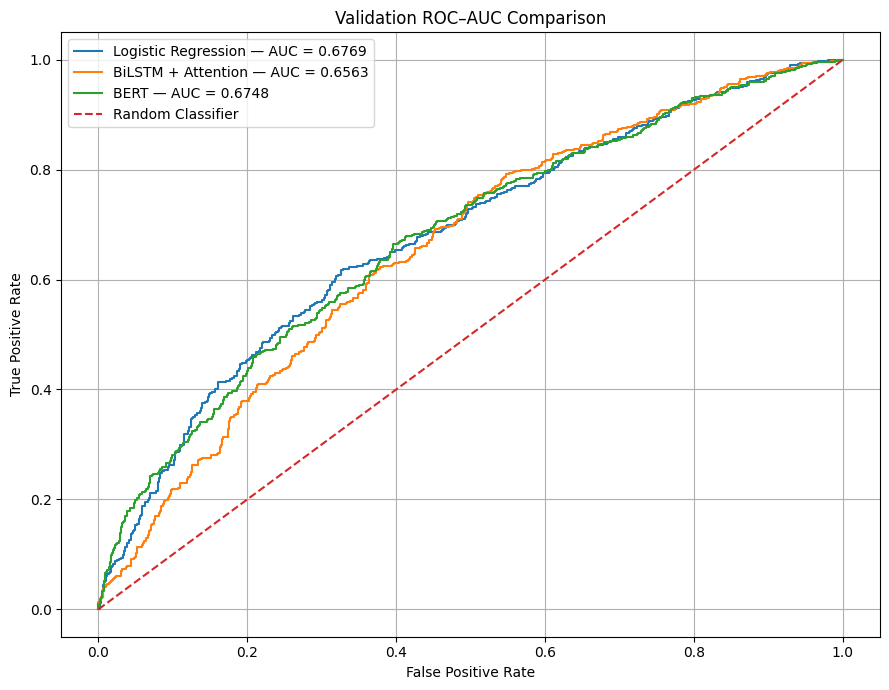


ROC–AUC VALIDATION COMPARISON
Logistic Regression AUC : 0.6769
BiLSTM + Attention AUC  : 0.6563
BERT AUC                : 0.6748


In [ ]:
# ============================================================
# 13.10 ROC–AUC COMPARISON — ALL 3 MODELS
# ============================================================

# This section:
# 1. Calculates the ROC curve for each deployment model.
# 2. Calculates ROC–AUC for each model.
# 3. Displays all three ROC curves together.
# 4. Prints the AUC value for each model.
#
# Original validation labels:
# FAKE / REAL
#
# For this ROC analysis:
# 1 = FAKE  (positive class)
# 0 = REAL


from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# Validation labels
# ------------------------------------------------------------

# The Logistic Regression validation labels are strings:
# "FAKE" and "REAL".
#
# Convert them into binary ROC labels:
# FAKE = 1
# REAL = 0

roc_validation_labels = (
    np.array(tfidf_validation_y) == "FAKE"
).astype(int)


# ------------------------------------------------------------
# Verify ROC labels
# ------------------------------------------------------------

print("=" * 80)
print("ROC LABEL VERIFICATION")
print("=" * 80)

print(
    "REAL (0) :",
    np.sum(roc_validation_labels == 0)
)

print(
    "FAKE (1) :",
    np.sum(roc_validation_labels == 1)
)


# ------------------------------------------------------------
# Convert model scores
# ------------------------------------------------------------

# All three score arrays represent:
# FAKE probability / score.

roc_logreg_scores = (
    tfidf_engineered_logreg_validation_probabilities
)

roc_bilstm_scores = (
    bilstm_validation_probabilities
)

roc_bert_scores = (
    bert_validation_probabilities
)


# ------------------------------------------------------------
# Verify score counts
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ROC SCORE VERIFICATION")
print("=" * 80)

print(
    "Validation samples       :",
    len(roc_validation_labels)
)

print(
    "Logistic Regression      :",
    len(roc_logreg_scores)
)

print(
    "BiLSTM + Attention       :",
    len(roc_bilstm_scores)
)

print(
    "BERT                     :",
    len(roc_bert_scores)
)


# ------------------------------------------------------------
# Calculate ROC curves
# ------------------------------------------------------------

logreg_fpr, logreg_tpr, _ = roc_curve(
    roc_validation_labels,
    roc_logreg_scores
)

bilstm_fpr, bilstm_tpr, _ = roc_curve(
    roc_validation_labels,
    roc_bilstm_scores
)

bert_fpr, bert_tpr, _ = roc_curve(
    roc_validation_labels,
    roc_bert_scores
)


# ------------------------------------------------------------
# Calculate AUC
# ------------------------------------------------------------

logreg_auc = roc_auc_score(
    roc_validation_labels,
    roc_logreg_scores
)

bilstm_auc = roc_auc_score(
    roc_validation_labels,
    roc_bilstm_scores
)

bert_auc = roc_auc_score(
    roc_validation_labels,
    roc_bert_scores
)


# ------------------------------------------------------------
# Display ROC curves
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.plot(
    logreg_fpr,
    logreg_tpr,
    label=f"Logistic Regression — AUC = {logreg_auc:.4f}"
)

plt.plot(
    bilstm_fpr,
    bilstm_tpr,
    label=f"BiLSTM + Attention — AUC = {bilstm_auc:.4f}"
)

plt.plot(
    bert_fpr,
    bert_tpr,
    label=f"BERT — AUC = {bert_auc:.4f}"
)


# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)


plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Validation ROC–AUC Comparison"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Display AUC values
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ROC–AUC VALIDATION COMPARISON")
print("=" * 80)

print(
    f"Logistic Regression AUC : {logreg_auc:.4f}"
)

print(
    f"BiLSTM + Attention AUC  : {bilstm_auc:.4f}"
)

print(
    f"BERT AUC                : {bert_auc:.4f}"
)

# 14. Final model comparision

In [ ]:
# 14. Final model comparision

In [ ]:
# ============================================================
# 13.11 FINAL MODEL LEADERBOARD — ALL 3 DEPLOYMENT MODELS
# ============================================================

# This section:
# 1. Combines the final Classical ML, BiLSTM, and BERT results.
# 2. Includes the features / architecture used by each model.
# 3. Includes Validation metrics and ROC–AUC.
# 4. Ranks the three deployment models by Validation F1 Macro.
# 5. Displays the final model leaderboard.
# 6. Displays detailed performance of the best Validation F1 Macro model.


# ------------------------------------------------------------
# Create final leaderboard
# ------------------------------------------------------------

final_model_comparison_df = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "BiLSTM + Attention",
        "BERT"
    ],

    "Features / Architecture": [
        "TF-IDF + Engineered Features",
        "Embedding + BiLSTM + Multi-Head Attention",
        "bert-base-uncased"
    ],

    "Validation Accuracy": [
        tfidf_engineered_logreg_validation_accuracy,
        bilstm_validation_accuracy,
        bert_validation_accuracy
    ],

    "Validation Precision FAKE": [
        tfidf_engineered_logreg_validation_precision,
        bilstm_validation_precision,
        bert_validation_precision_fake
    ],

    "Validation Recall FAKE": [
        tfidf_engineered_logreg_validation_recall,
        bilstm_validation_recall,
        bert_validation_recall_fake
    ],

    "Validation F1 FAKE": [
        tfidf_engineered_logreg_validation_f1,
        bilstm_validation_f1,
        bert_validation_f1_fake
    ],

    "Validation F1 Macro": [
        tfidf_engineered_logreg_validation_f1_macro,
        bilstm_validation_f1_macro,
        bert_validation_f1_macro
    ],

    "ROC–AUC": [
        logreg_auc,
        bilstm_auc,
        bert_auc
    ]
})


# ------------------------------------------------------------
# Rank models by Validation F1 Macro
# ------------------------------------------------------------

final_model_comparison_df = (
    final_model_comparison_df
    .sort_values(
        by="Validation F1 Macro",
        ascending=False
    )
    .reset_index(drop=True)
)


final_model_comparison_df.insert(
    0,
    "Rank",
    range(
        1,
        len(final_model_comparison_df) + 1
    )
)


# ------------------------------------------------------------
# Display leaderboard
# ------------------------------------------------------------

print("=" * 110)
print("AUTOMATIC FINAL MODEL LEADERBOARD")
print("=" * 110)

display(
    final_model_comparison_df.round(4)
)

AUTOMATIC FINAL MODEL LEADERBOARD


,Rank,Model,Features / Architecture,Validation Accuracy,Validation Precision FAKE,Validation Recall FAKE,Validation F1 FAKE,Validation F1 Macro,ROC–AUC
0,1,Logistic Regression,TF-IDF + Engineered Features,0.6262,0.6040,0.6412,0.6220,0.6261,0.6769
1,2,BERT,bert-base-uncased,0.6262,0.6259,0.5487,0.5848,0.6224,0.6748
2,3,BiLSTM + Attention,Embedding + BiLSTM + Multi-Head Attention,0.6176,0.6023,0.5974,0.5998,0.6168,0.6563


In [ ]:
# ============================================================
# P22 — FINAL SAVE FOR MODELS / RESULTS / ARTIFACTS
# DEPLOYMENT-READY VERSION
# ============================================================

import os
import pickle
import json
import numpy as np
import pandas as pd
import torch


# ============================================================
# 1. P22 DIRECTORIES
# ============================================================

P22_ROOT = "/content/drive/MyDrive/Ai_project/P22"

P22_MODELS_DIR = os.path.join(
    P22_ROOT,
    "models"
)

P22_RESULTS_DIR = os.path.join(
    P22_ROOT,
    "results"
)

P22_ARTIFACTS_DIR = os.path.join(
    P22_ROOT,
    "artifacts"
)

os.makedirs(P22_MODELS_DIR, exist_ok=True)
os.makedirs(P22_RESULTS_DIR, exist_ok=True)
os.makedirs(P22_ARTIFACTS_DIR, exist_ok=True)


print("=" * 90)
print("P22 FINAL SAVE — DEPLOYMENT PREPARATION")
print("=" * 90)


# ============================================================
# 2. FIND THE FITTED TF-IDF VECTORIZER
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer


tfidf_vectorizer_candidates = []


for variable_name, variable_value in list(globals().items()):

    if isinstance(
        variable_value,
        TfidfVectorizer
    ):

        tfidf_vectorizer_candidates.append(
            variable_name
        )


print("\nTF-IDF VECTORIZER CHECK")
print("-" * 90)

print(
    "Detected TF-IDF vectorizers:",
    tfidf_vectorizer_candidates
)


if len(tfidf_vectorizer_candidates) == 0:

    raise RuntimeError(
        "\nNo fitted TfidfVectorizer object was found.\n\n"
        "DO NOT create a new TF-IDF vectorizer for deployment.\n"
        "The original fitted vectorizer used to create the "
        "10,000 TF-IDF features must be saved.\n\n"
        "We need to locate the original TF-IDF vectorizer "
        "from the earlier Logistic Regression cells first."
    )


if len(tfidf_vectorizer_candidates) > 1:

    print(
        "\nWARNING: Multiple TF-IDF vectorizers were found:"
    )

    for name in tfidf_vectorizer_candidates:
        print("  ", name)

    raise RuntimeError(
        "\nMultiple TF-IDF vectorizers found. "
        "We need to identify the one used for the final "
        "10,000-feature Logistic Regression model before saving."
    )


# Use the single detected vectorizer
tfidf_vectorizer_variable_name = (
    tfidf_vectorizer_candidates[0]
)

tfidf_vectorizer = globals()[
    tfidf_vectorizer_variable_name
]


print(
    "Selected vectorizer:",
    tfidf_vectorizer_variable_name
)

print(
    "Number of TF-IDF features:",
    len(tfidf_vectorizer.get_feature_names_out())
)


# Confirm that it is really the 10,000-feature vectorizer
if len(
    tfidf_vectorizer.get_feature_names_out()
) != 10000:

    raise RuntimeError(
        "The selected TF-IDF vectorizer does not contain "
        "10,000 features. Deployment cannot continue."
    )


# ============================================================
# 3. SAVE TF-IDF VECTORIZER
# ============================================================

with open(
    os.path.join(
        P22_ARTIFACTS_DIR,
        "tfidf_vectorizer.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        tfidf_vectorizer,
        file
    )


# ============================================================
# 4. SAVE LOGISTIC REGRESSION MODEL
# ============================================================

with open(
    os.path.join(
        P22_MODELS_DIR,
        "logistic_regression_tfidf_engineered.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        tfidf_engineered_logreg_grid_search,
        file
    )


# Exact engineered feature order
logistic_engineered_features = [
    "caps_ratio",
    "exclamation_count",
    "question_mark_count"
]


with open(
    os.path.join(
        P22_ARTIFACTS_DIR,
        "logistic_engineered_features.json"
    ),
    "w"
) as file:

    json.dump(
        {
            "feature_order":
                logistic_engineered_features,

            "number_of_features":
                len(logistic_engineered_features)
        },
        file,
        indent=4
    )


# Logistic Regression results
logistic_regression_results = {

    "model":
        "Logistic Regression",

    "features":
        "TF-IDF + Engineered Features",

    "tfidf_features":
        10000,

    "engineered_features":
        logistic_engineered_features,

    "total_features":
        10003,

    "best_parameters":
        tfidf_engineered_logreg_grid_search.best_params_,

    "cv_f1_macro":
        tfidf_engineered_logreg_grid_search.best_score_,

    "validation_accuracy":
        tfidf_engineered_logreg_validation_accuracy,

    "validation_precision_fake":
        tfidf_engineered_logreg_validation_precision,

    "validation_recall_fake":
        tfidf_engineered_logreg_validation_recall,

    "validation_f1_fake":
        tfidf_engineered_logreg_validation_f1,

    "validation_f1_macro":
        tfidf_engineered_logreg_validation_f1_macro,

    "validation_roc_auc":
        logreg_auc
}


with open(
    os.path.join(
        P22_RESULTS_DIR,
        "logistic_regression_results.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        logistic_regression_results,
        file
    )


# ============================================================
# 5. SAVE BILSTM MODEL
# ============================================================

torch.save(
    bilstm_best_state_dict,
    os.path.join(
        P22_MODELS_DIR,
        "bilstm_attention_best_state_dict.pt"
    )
)


# BiLSTM reconstruction information
bilstm_artifacts = {

    "word_to_index":
        bilstm_word_to_index,

    "index_to_word":
        bilstm_index_to_word,

    "vocab_size":
        BILSTM_VOCAB_SIZE,

    "embedding_dim":
        BILSTM_EMBEDDING_DIM,

    "hidden_dim":
        BILSTM_HIDDEN_DIM,

    "attention_heads":
        BILSTM_ATTENTION_HEADS,

    "dropout":
        BILSTM_DROPOUT,

    "max_sequence_length":
        bilstm_max_sequence_length,

    "pad_token":
        BILSTM_PAD_TOKEN,

    "unk_token":
        BILSTM_UNK_TOKEN,

    "label_mapping":
        BILSTM_LABEL_MAPPING
}


with open(
    os.path.join(
        P22_ARTIFACTS_DIR,
        "bilstm_artifacts.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        bilstm_artifacts,
        file
    )


# BiLSTM results
bilstm_results_to_save = {

    "model":
        "BiLSTM + Attention",

    "best_epoch":
        bilstm_best_epoch,

    "best_validation_f1":
        bilstm_best_validation_f1,

    "validation_accuracy":
        bilstm_validation_accuracy,

    "validation_precision":
        bilstm_validation_precision,

    "validation_recall":
        bilstm_validation_recall,

    "validation_f1":
        bilstm_validation_f1,

    "validation_f1_macro":
        bilstm_validation_f1_macro,

    "validation_roc_auc":
        bilstm_auc
}


with open(
    os.path.join(
        P22_RESULTS_DIR,
        "bilstm_results.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        bilstm_results_to_save,
        file
    )


# Training history
with open(
    os.path.join(
        P22_RESULTS_DIR,
        "bilstm_training_history.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        bilstm_training_history,
        file
    )


# ============================================================
# 6. SAVE BERT MODEL
# ============================================================

torch.save(
    bert_best_model_state,
    os.path.join(
        P22_MODELS_DIR,
        "bert_best_state_dict.pt"
    )
)


# BERT configuration
bert_configuration = {

    "model_name":
        BERT_MODEL_NAME,

    "max_length":
        BERT_MAX_LENGTH,

    "number_of_labels":
        BERT_NUM_LABELS,

    "batch_size":
        BERT_BATCH_SIZE,

    "learning_rate":
        BERT_LEARNING_RATE,

    "epochs":
        BERT_EPOCHS,

    "best_epoch":
        bert_best_epoch,

    "best_validation_f1":
        bert_best_validation_f1
}


with open(
    os.path.join(
        P22_ARTIFACTS_DIR,
        "bert_configuration.json"
    ),
    "w"
) as file:

    json.dump(
        bert_configuration,
        file,
        indent=4
    )


# Save BERT tokenizer
bert_tokenizer.save_pretrained(
    os.path.join(
        P22_ARTIFACTS_DIR,
        "bert_tokenizer"
    )
)


# BERT results
bert_results_to_save = {

    "model":
        "BERT",

    "model_name":
        BERT_MODEL_NAME,

    "best_epoch":
        bert_best_epoch,

    "best_validation_f1":
        bert_best_validation_f1,

    "validation_accuracy":
        bert_validation_accuracy,

    "validation_precision_fake":
        bert_validation_precision_fake,

    "validation_recall_fake":
        bert_validation_recall_fake,

    "validation_f1_fake":
        bert_validation_f1_fake,

    "validation_f1_macro":
        bert_validation_f1_macro,

    "validation_roc_auc":
        bert_auc
}


with open(
    os.path.join(
        P22_RESULTS_DIR,
        "bert_results.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        bert_results_to_save,
        file
    )


# Training history
with open(
    os.path.join(
        P22_RESULTS_DIR,
        "bert_training_history.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        bert_training_history,
        file
    )


# ============================================================
# 7. LABEL MAPPING
# ============================================================

binary_label_mapping = {
    "FAKE": 0,
    "REAL": 1
}


with open(
    os.path.join(
        P22_ARTIFACTS_DIR,
        "binary_label_mapping.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        binary_label_mapping,
        file
    )


# ============================================================
# 8. FINAL MODEL COMPARISON
# ============================================================

final_model_comparison_df.to_csv(
    os.path.join(
        P22_RESULTS_DIR,
        "final_model_comparison.csv"
    ),
    index=False
)


with open(
    os.path.join(
        P22_RESULTS_DIR,
        "final_model_comparison.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        final_model_comparison_df,
        file
    )


# ============================================================
# 9. ROC-AUC RESULTS
# ============================================================

roc_auc_results = {

    "Logistic Regression":
        logreg_auc,

    "BiLSTM + Attention":
        bilstm_auc,

    "BERT":
        bert_auc
}


with open(
    os.path.join(
        P22_RESULTS_DIR,
        "roc_auc_comparison.pkl"
    ),
    "wb"
) as file:

    pickle.dump(
        roc_auc_results,
        file
    )


# ============================================================
# 10. FINAL DIRECTORY VERIFICATION
# ============================================================

print("\n" + "=" * 90)
print("P22 SAVE COMPLETE")
print("=" * 90)


print("\n📁 MODELS")
print("-" * 90)

for item in sorted(
    os.listdir(P22_MODELS_DIR)
):

    print("  ", item)


print("\n📁 RESULTS")
print("-" * 90)

for item in sorted(
    os.listdir(P22_RESULTS_DIR)
):

    print("  ", item)


print("\n📁 ARTIFACTS")
print("-" * 90)

for item in sorted(
    os.listdir(P22_ARTIFACTS_DIR)
):

    print("  ", item)

P22 FINAL SAVE — DEPLOYMENT PREPARATION

TF-IDF VECTORIZER CHECK
------------------------------------------------------------------------------------------
Detected TF-IDF vectorizers: ['tfidf_vectorizer']
Selected vectorizer: tfidf_vectorizer
Number of TF-IDF features: 10000

P22 SAVE COMPLETE

📁 MODELS
------------------------------------------------------------------------------------------
   bert_best_state_dict.pt
   bilstm_attention_best_state_dict.pt
   logistic_regression_tfidf_engineered.pkl

📁 RESULTS
------------------------------------------------------------------------------------------
   bert_results.pkl
   bert_training_history.pkl
   bilstm_results.pkl
   bilstm_training_history.pkl
   final_model_comparison.csv
   final_model_comparison.pkl
   logistic_regression_results.pkl
   roc_auc_comparison.pkl

📁 ARTIFACTS
------------------------------------------------------------------------------------------
   bert_configuration.json
   bert_tokenizer
   bilstm_artifacts

In [ ]:
# ============================================================
# COPY P22 MODELS / ARTIFACTS / RESULTS TO DEPLOYMENT
# ============================================================

import os
import shutil

# ------------------------------------------------------------
# P22 paths
# ------------------------------------------------------------

P22_ROOT = "/content/drive/MyDrive/Ai_project/P22"

SOURCE_MODELS = os.path.join(P22_ROOT, "models")
SOURCE_ARTIFACTS = os.path.join(P22_ROOT, "artifacts")
SOURCE_RESULTS = os.path.join(P22_ROOT, "results")

DEPLOYMENT_ROOT = os.path.join(P22_ROOT, "deployment")

DEPLOYMENT_MODELS = os.path.join(
    DEPLOYMENT_ROOT,
    "models"
)

DEPLOYMENT_ARTIFACTS = os.path.join(
    DEPLOYMENT_ROOT,
    "artifacts"
)

DEPLOYMENT_RESULTS = os.path.join(
    DEPLOYMENT_ROOT,
    "results"
)


# ------------------------------------------------------------
# Create deployment folders
# ------------------------------------------------------------

os.makedirs(DEPLOYMENT_MODELS, exist_ok=True)
os.makedirs(DEPLOYMENT_ARTIFACTS, exist_ok=True)
os.makedirs(DEPLOYMENT_RESULTS, exist_ok=True)


# ------------------------------------------------------------
# Copy function
# ------------------------------------------------------------

def copy_items(source_dir, destination_dir):

    for item in os.listdir(source_dir):

        source_path = os.path.join(
            source_dir,
            item
        )

        destination_path = os.path.join(
            destination_dir,
            item
        )

        if os.path.isdir(source_path):

            shutil.copytree(
                source_path,
                destination_path,
                dirs_exist_ok=True
            )

        else:

            shutil.copy2(
                source_path,
                destination_path
            )


# ------------------------------------------------------------
# Copy existing saved files
# ------------------------------------------------------------

copy_items(
    SOURCE_MODELS,
    DEPLOYMENT_MODELS
)

copy_items(
    SOURCE_ARTIFACTS,
    DEPLOYMENT_ARTIFACTS
)

copy_items(
    SOURCE_RESULTS,
    DEPLOYMENT_RESULTS
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 90)
print("P22 DEPLOYMENT FOLDER CREATED")
print("=" * 90)

print("\n📁 DEPLOYMENT")
print("-" * 90)
print(DEPLOYMENT_ROOT)

print("\n📁 MODELS")
print("-" * 90)

for item in sorted(
    os.listdir(DEPLOYMENT_MODELS)
):
    print("  ", item)


print("\n📁 ARTIFACTS")
print("-" * 90)

for item in sorted(
    os.listdir(DEPLOYMENT_ARTIFACTS)
):
    print("  ", item)


print("\n📁 RESULTS")
print("-" * 90)

for item in sorted(
    os.listdir(DEPLOYMENT_RESULTS)
):
    print("  ", item)


print("\n" + "=" * 90)
print("COPY COMPLETE")
print("=" * 90)

P22 DEPLOYMENT FOLDER CREATED

📁 DEPLOYMENT
------------------------------------------------------------------------------------------
/content/drive/MyDrive/Ai_project/P22/deployment

📁 MODELS
------------------------------------------------------------------------------------------
   bert_best_state_dict.pt
   bilstm_attention_best_state_dict.pt
   logistic_regression_tfidf_engineered.pkl

📁 ARTIFACTS
------------------------------------------------------------------------------------------
   bert_configuration.json
   bert_tokenizer
   bilstm_artifacts.pkl
   binary_label_mapping.pkl
   logistic_engineered_features.json
   tfidf_vectorizer.pkl

📁 RESULTS
------------------------------------------------------------------------------------------
   bert_results.pkl
   bert_training_history.pkl
   bilstm_results.pkl
   bilstm_training_history.pkl
   final_model_comparison.csv
   final_model_comparison.pkl
   logistic_regression_results.pkl
   roc_auc_comparison.pkl

COPY COMPLETE
